In [1]:
import os

import lifelines
import matplotlib.pyplot as plt
import matplotlib
import numpy
import pandas
import pickle
import time
import seaborn as sns

import immuw.clustering.clustering_utils as cimu
import tumorhood_analysis_utils as tau


# Number of enriched cellular neighborhood classes
CC_NB_OF_CLUSTERS = 34

CLUSTER_SELECTION_PATH = '/raid/immucan/immuw/cellohood_artifacts/NSCLC_P2'  # [Zenodo prep] was a relative path './NSCLC-Cello-v1-p2-34' that did not exist, which would have forced an expensive from-scratch cluster-selection recompute instead of using the precomputed p2_cs_result_sqrt.pickle staged for Zenodo.

VECTORIZER = lambda x: x.values.T ** 0.5
VECTORIZER_NAME = 'sqrt'
PANEL_1_CLUSTER_SELECTION_PATH = os.path.join(CLUSTER_SELECTION_PATH, f'p2_cs_result_{VECTORIZER_NAME}.pickle')

# PREDICTION RELATED 
TYPE = 'sd'
import joblib

PREDICTIONS_PATH = '/raid/immucan/immuw/cellohood_artifacts/NSCLC_P2/predictions.npy'  # [Zenodo prep] redirected from the internal compute-cluster path to the staged artifact (verified byte-identical: same shape (1656630,), np.array_equal == True).
PREDICTION_CLUSTER_COLUMN = 'Cellohood Neighborhood Cluster'
CC_CLUSTER_NAME = 'tumorhood_neighborhood_cluster'

# IMAGE/SAMPLE RELATED 
ROI_COLUMN = 'image'
SAMPLE_COLUMN = 'sample_id'

CLINICAL_DATA_DF = '/raid/immucan/immuw/cellohood_artifacts/NSCLC_P2/nsclc_clinical_corrected.csv'  # [Zenodo prep] the old relative filename 'nsclc_clinical_clean_corrected.csv' does not exist anywhere on disk; this is the canonical corrected clinical file.


PANEL_1_FULL_CSV_FILEPATH = '/raid/immucan/immuw/cellohood_artifacts/NSCLC_P2/nsclc2_p2_25.csv'  # [Zenodo prep] redirected from the internal compute-cluster path to the staged artifact (verified byte-identical content/row count).

# MARKER RELATED
MARKERS = tau.PANEL_2_MARKER_NAMES
MARKERS_CLEAN = MARKERS

# Clinical Related:
CLINICAL_DATA_COLS_FOR_ANALYSIS = [
    'roman_simple_stage', 
    'stage_2-',
    'simple_histology',
    #'neo_adjuvant_treatment',
    'death', 
    'smoking_status',
    'gender',
    #'environmental_exposure',
    'TPS_score',
    'CPS_score',
    'tmb_class',
    #'KRAS', 'TP53', 'EGFR', 'PIK3CA', 'ERBB2'
] 

# Additional Column names
DUMMY_COL_NAME = 'dummy'
CELLTYPE_COLNAME = 'celltypes'
CELLTYPE_PLOT_NAME = 'Cell type'
MARKER_PLOT_NAME = 'Marker'
ALL_PLOT_NAME = 'All'
ROI_CLUSTER_NAME = 'ROI'

# Plotting
PLOTTING_DPI = 300
sns.set_context("paper", rc={"font.size": 6, "axes.titlesize":6,"axes.labelsize":6})  
plt.rcParams['legend.title_fontsize'] = 6
plt.rcParams['legend.fontsize'] = 6

matplotlib.font_manager.fontManager.addfont('/raid/immucan/immuw/Arial.ttf')  # if you need to add the font file
plt.rcParams['font.family'] = 'Arial'

## Cell type level data loading and preprocessing

In [2]:
cell_df = pandas.read_csv(PANEL_1_FULL_CSV_FILEPATH)

/tmp/ipykernel_121012/796832730.py:1: DtypeWarning: Columns (15,38,84,85) have mixed types. Specify dtype option on import or set low_memory=False.
  cell_df = pandas.read_csv(PANEL_1_FULL_CSV_FILEPATH)


In [3]:
cell_df.groupby('image').size().shape

(566,)

In [4]:
', '.join(cell_df.groupby('celltypes').size().index)

'B, BnT, CD4, CD8, DC, Fibro, Igg, MDSC, MacCD204, MacCD204_CD209, MacCD209, NK, Neutrophil, PMN_MDSC, SMA, Treg, Tumor, Vasculature, mregDC, undefined, vCAF'

In [5]:
cell_df.shape, cell_df.groupby('image').size().shape

((1656630, 86), (566,))

In [6]:
# Marker ARCSINH x / 5 transformation
cell_df[MARKERS] =  cell_df[MARKERS].applymap(lambda x: numpy.arcsinh(x / 5.))

In [7]:
# Extra column for computations
cell_df[DUMMY_COL_NAME] = 1

## Prediction level loading

In [8]:
predictions = numpy.load(PREDICTIONS_PATH)

In [9]:
if TYPE == 'bag':
    cell_df[PREDICTION_CLUSTER_COLUMN] = cell_df[CC_CLUSTER_NAME].apply(lambda x: predictions[x])
elif TYPE == 'sd':
    cell_df[PREDICTION_CLUSTER_COLUMN] = predictions
else:
    raise ValueError('Unknown TYPE.')

## Cell type related preparation:

In [10]:
celltype_counts = pandas.pivot_table(
    cell_df, 
    values=DUMMY_COL_NAME, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CELLTYPE_COLNAME],
    aggfunc="sum",
).fillna(0)

In [11]:
celltype_percentages = (celltype_counts.T / celltype_counts.sum(axis=1)).T
celltype_percentages.columns.name = CELLTYPE_PLOT_NAME

In [12]:
celltypes = list(celltype_percentages.columns)

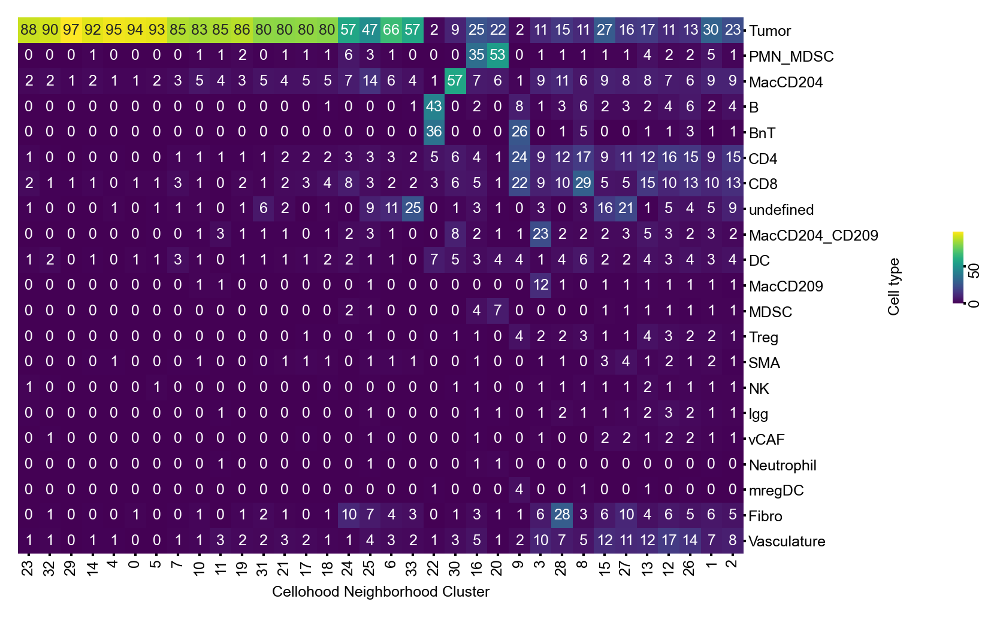

In [13]:
celltype_clustermap = sns.clustermap(
    celltype_percentages[celltypes].T * 100, 
    annot=True,
    #row_colors=celltypes_color_df,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.05, 0.4, 0.01, 0.1),
    annot_kws={"size": 6},
    cbar_kws={'label': ''}
)

#celltype_clustermap.ax_cbar.set_xlabel(f'{CELLTYPE_PLOT_NAME} percentage', labelpad=0, size=6)

celltype_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1, rotation=90)
celltype_clustermap.ax_row_dendrogram.set_visible(False)
celltype_clustermap.ax_col_dendrogram.set_visible(False)

celltype_clustermap.ax_heatmap.set_yticklabels(celltype_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
celltype_clustermap.ax_heatmap.set_xticklabels(celltype_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
#celltype_clustermap.ax_row_colors.set_xticklabels(celltype_clustermap.ax_row_colors.get_xticklabels(), size=6)
#celltype_clustermap.ax_row_colors.xaxis.set_tick_params(size=1, pad=1)

celltype_clustermap.fig.set_dpi(PLOTTING_DPI)
celltype_clustermap.fig.set_size_inches((6, 4))

In [14]:
meta_cluster_dict = {
    'PURE_TUMOR': [23, 32, 29, 14, 0, 11, 17, 19, 10, 5, 7, 31, 21, 18, 4],
    'PMN-MDSC': [16, 20],
    'INFILTRATION': [6, 33, 24, 12, 26, 13, 28, 1, 2, 8, 15, 27],
    'TLS': [22, 9],
    'MAC': [25, 3, 30][::-1],
}
[]

[]

In [15]:
non_inf = sum(meta_cluster_dict.values(), [])

In [16]:
meta_cluster_dict['TLS'] = meta_cluster_dict['TLS']

In [17]:
mc_to_c = tau.META_CLUSTER_TO_COLOR.copy()
mc_to_c['PMN-MDSC'] = '#C71585'

In [18]:
META_CLUSTER_PERM = []
meta_cluster_colors = []
meta_cluster_names = []


for mc, cls_ in meta_cluster_dict.items():
        for index_ in cls_:
            meta_cluster_colors.append(mc_to_c[mc])
            META_CLUSTER_PERM.append(index_)
            meta_cluster_names.append(mc)

In [19]:
from collections import defaultdict

celltypes_display_percentage = defaultdict(lambda: 0.1)
celltypes_display_percentage['Tumor'] = 0.1
celltypes_display_percentage['CD4'] = 0.05
celltypes_display_percentage['CD8'] = 0.05
celltypes_display_percentage['MacCD204'] = 0.05
celltypes_display_percentage['MacCD209'] = 0.05
celltypes_display_percentage['MacCD204&209'] = 0.05
#celltypes_display_percentage['Mural'] = 0.14

In [20]:
celltypes_to_marker_to_show = {
    'PMN_MDSC': ['CXCL8'],
    'MacCD204': ['CD11c'],
    'MacCD204_CD209': ['CD11c'],
    'CD4': ['PD1', 'CD134', 'Tim3', 'CD45'],
    'CD8': ['CD45', 'EOMES', 'PD1', 'Tim3', 'GITR', 'CD7', 'CD134'],
    'Tumor': ['CD73', 'CD155', 'Ecad', 'Bcl2', 'panCK', 'EGFR', 'CD56', 'Ki67', 'p53'],
    'All': ['Podoplanin', 'SMA', 'CD31', 'Lamp3', 'Ki67']
}

In [21]:
celltypes_cc_display = {
    ct: [
        ind_ 
        for ind_, cc_ in enumerate(celltype_percentages[ct] > celltypes_display_percentage[ct])
        if cc_
    ]
    for ct in celltypes_to_marker_to_show
    if ct in celltype_percentages.columns
}

In [22]:
def transform_vec_to_colors(
    vec,
    colors,
    standarize=True,
    display=None,
    permute=None,
    ignore_color=(160 / 255, 160 / 255, 160 / 255),
):
    if standarize:
        display = display if display is not None else numpy.arange(len(vec))
        vec = vec.copy()
        vec = vec - numpy.mean(vec[display])
        vec = vec / numpy.std(vec[display])
    result = [
        colors.to_rgba(x)
        for x in vec
    ]
    if display is not None:
        new_result = []
        for ind_, result_col in enumerate(result):
            current_color = list(result_col)
            if ind_ in display:
                pass 
            else:
                current_color = ignore_color
            new_result.append(current_color)
            
        result = new_result
    if permute:
        result = [
            result[i]
            for i in permute
        ]
    return result

## Marker analysis

### Cell type level:
For each marker compute the average marker expression for a given cell type:

In [23]:
marker_to_celltype_dfs = {}


for marker in MARKERS:
    marker_to_celltype_dfs[marker] = pandas.pivot_table(
    cell_df, 
    values=marker, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CELLTYPE_COLNAME],
    aggfunc='mean',
).fillna(0)

Now - let us transpose this dictionary to cell type to marker df:

In [24]:
marker_ct_ipc = numpy.stack([
    marker_df.values
    for marker_df in marker_to_celltype_dfs.values()
])

celltype_to_marker_dfs = {
    ct: pandas.DataFrame(
        marker_ct_ipc[:, :, ct_ind],
        index=MARKERS,
    )
    for ct_ind, ct in enumerate(celltypes)
}

Now - let's rename the markers to their clean names:

In [25]:
celltype_to_marker_dfs_clean = {}


for celltype, cdf in celltype_to_marker_dfs.items():
    cdf_clean = cdf.copy()
    cdf_clean[MARKER_PLOT_NAME] = MARKERS_CLEAN
    cdf_clean.set_index(MARKER_PLOT_NAME, inplace=True),
    celltype_to_marker_dfs_clean[celltype] = cdf_clean

In [26]:
marker_color_norm = matplotlib.colors.Normalize(vmin=-2, vmax=2)
marker_cmap = plt.get_cmap('coolwarm')

marker_sm = matplotlib.cm.ScalarMappable(norm=marker_color_norm, cmap=marker_cmap)

## All marker analysis:

Now let's compute the overall marker distribution across all cells:

In [27]:
all_markers_distribution = cell_df.groupby([PREDICTION_CLUSTER_COLUMN]).mean()[MARKERS]
all_markers_distribution -= all_markers_distribution.mean()
all_markers_distribution /= all_markers_distribution.std()
all_markers_distribution.columns = MARKERS_CLEAN

celltype_to_marker_dfs_clean[ALL_PLOT_NAME] = all_markers_distribution.T

/tmp/ipykernel_121012/762203048.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  all_markers_distribution = cell_df.groupby([PREDICTION_CLUSTER_COLUMN]).mean()[MARKERS]


Now let's display the all marker distributions:

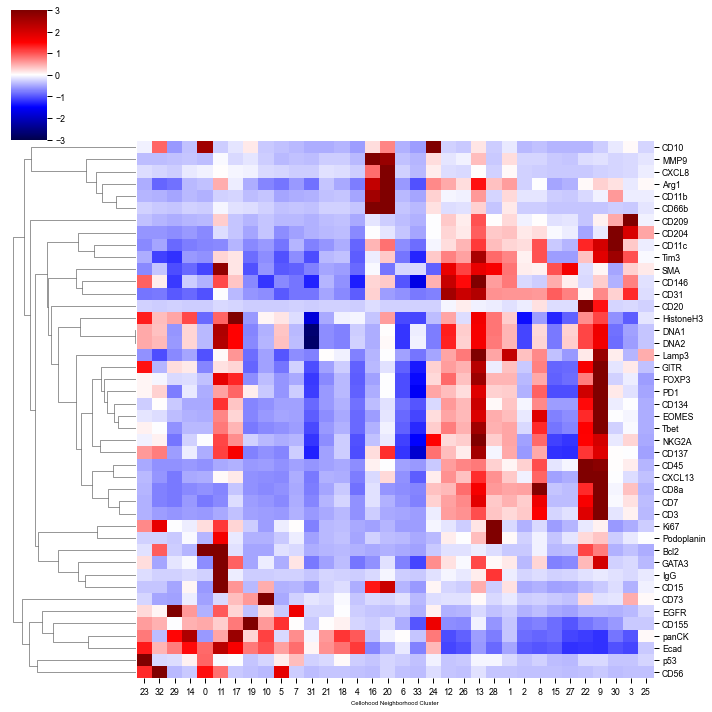

In [28]:
sns.clustermap(
    all_markers_distribution.T[META_CLUSTER_PERM], 
    col_cluster=False,
    center=0, cmap='seismic', vmin=-3, vmax=3, yticklabels=True)

Now - let's visualize the Cellohood Neighobrhoods with average markers.

Let's start with providing some handy tools:
- marker colormap:

In [29]:
marker_color_norm = matplotlib.colors.Normalize(vmin=-2, vmax=2)
marker_cmap = plt.get_cmap('coolwarm')

marker_sm = matplotlib.cm.ScalarMappable(norm=marker_color_norm, cmap=marker_cmap)

and a code to transform values to vectors:

In [30]:
def transform_vec_to_colors(
    vec,
    colors,
    standarize=True,
    display=None,
    permute=None,
    ignore_color=(160 / 255, 160 / 255, 160 / 255),
):
    if standarize:
        display = display if display is not None else numpy.arange(len(vec))
        vec = vec.copy()
        vec = vec - numpy.mean(vec[display])
        vec = vec / numpy.std(vec[display])
    result = [
        colors.to_rgba(x)
        for x in vec
    ]
    if display is not None:
        new_result = []
        for ind_, result_col in enumerate(result):
            current_color = list(result_col)
            if ind_ in display:
                pass 
            else:
                current_color = ignore_color
            new_result.append(current_color)
            
        result = new_result
    if permute:
        result = [
            result[i]
            for i in permute
        ]
    return result

Now let's transform average markers across all cells to colors:

In [31]:
all_colors_dict = {
    f'{marker}': transform_vec_to_colors( 
        vec=celltype_to_marker_dfs_clean[ALL_PLOT_NAME].loc[marker],
        colors=marker_sm,
    )
    for marker in MARKERS_CLEAN
}

all_colors_df = pandas.DataFrame(all_colors_dict)

and visualize CC clusters with average marker distributions:

In [32]:
cc_densities = cell_df.groupby(
    [PREDICTION_CLUSTER_COLUMN, CC_CLUSTER_NAME]
).size().groupby(PREDICTION_CLUSTER_COLUMN).mean()

In [33]:
cc_colors_dict = {}
for ct, markers in celltypes_to_marker_to_show.items():
    for marker in markers:
        print(ct, marker)
        cc_colors_dict[f'{ct}: {marker}'] = transform_vec_to_colors( 
                vec=celltype_to_marker_dfs_clean[ct].loc[marker],
                colors=marker_sm,
                display=celltypes_cc_display[ct] if ct in celltypes_cc_display else None,
            )


cc_marker_ct_colors = pandas.DataFrame(cc_colors_dict)

cc_marker_ct_colors['All: Cell density'] = transform_vec_to_colors( 
        vec=cc_densities,
        colors=marker_sm,
)

PMN_MDSC CXCL8
MacCD204 CD11c
MacCD204_CD209 CD11c
CD4 PD1
CD4 CD134
CD4 Tim3
CD4 CD45
CD8 CD45
CD8 EOMES
CD8 PD1
CD8 Tim3
CD8 GITR
CD8 CD7
CD8 CD134
Tumor CD73
Tumor CD155
Tumor Ecad
Tumor Bcl2
Tumor panCK
Tumor EGFR
Tumor CD56
Tumor Ki67
Tumor p53
All Podoplanin
All SMA
All CD31
All Lamp3
All Ki67


In [34]:
cc_marker_ct_colors['CN Class'] = numpy.array(meta_cluster_colors)[numpy.argsort(META_CLUSTER_PERM)]

In [35]:
celltype_replacement = {
    'PMN_MDSC': 'PMN-MDSC',
    'MacCD204_CD209': 'MacCD204&209'
}

def clean_up_celltype(str_, replacement_dict=None):
    if replacement_dict is None:
        replacement_dict = celltype_replacement
    for pattern, replacement in replacement_dict.items():
        if pattern in str_:
            str_ = str_.replace(pattern, replacement)
    return str_

cc_marker_ct_colors.columns = [
    clean_up_celltype(col) for col in cc_marker_ct_colors.columns
]

In [36]:
celltype_percentages.columns = [
    clean_up_celltype(col) for col in celltype_percentages.columns
]

celltypes = [clean_up_celltype(ct) for ct in celltypes]

In [37]:
IMMU_METAS_CLEAN = [
    'Pure Tumor',
    'PMN-MDSC-enriched',
    'Infiltration',
    'CD20+',
    'Mac-enriched',
]

/tmp/ipykernel_121012/2352195052.py:91: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


/tmp/ipykernel_121012/2352195052.py:91: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


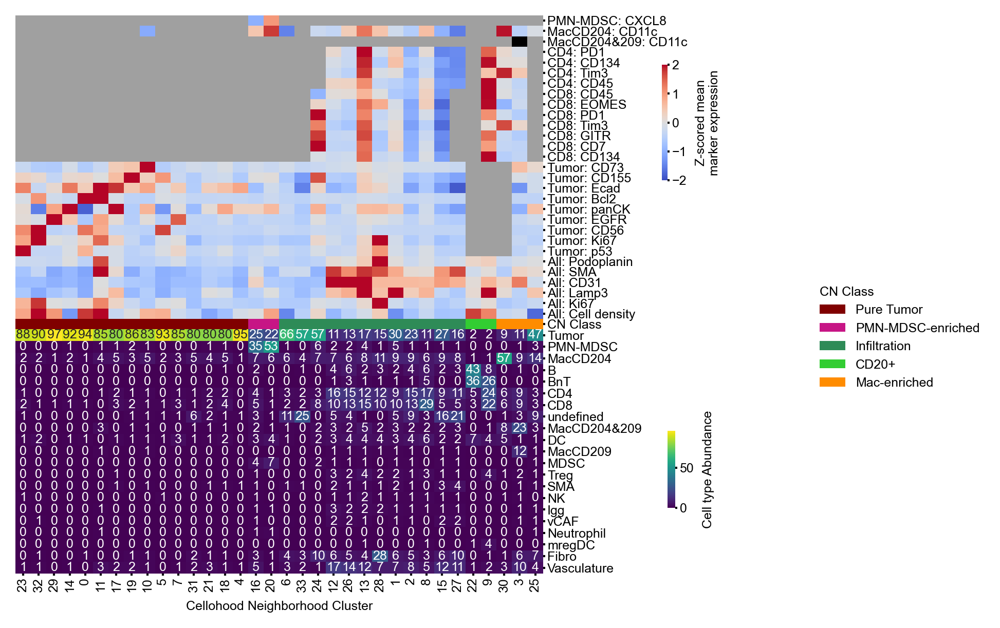

In [38]:
COLORBARS_SHIFT = .98

cc_abundance_std_argsort = (-celltype_percentages['Tumor'].values).argsort()

celltype_clustermap = sns.clustermap(
    (celltype_percentages[celltypes].T * 100)[META_CLUSTER_PERM], 
    annot=True,
    col_cluster=False,
    fmt='.0f',
    cmap='viridis',
    figsize=(12, 8),
    col_colors=cc_marker_ct_colors,
    #row_colors=[class_to_color[celltype_to_class[ct]] for ct in numpy.array(celltypes)],
    colors_ratio=0.015,
    yticklabels=True,
    xticklabels=META_CLUSTER_PERM,
    #linewidth=0.003,
    annot_kws={"size": 6},
    cbar_pos=[COLORBARS_SHIFT + 0.05, 0.15, 0.01, .1],
    cbar_kws={'label': 'Cell type Abundance'}
)


#handles = [Patch(facecolor=class_to_color[name]) for name in class_to_color]
#plt.legend(
#    handles, 
#    class_to_color, 
#    title=' Cell type Metatype',
#    bbox_to_anchor=(0.17, 0.53), 
#    bbox_transform=plt.gcf().transFigure,
#    frameon=False,
#    fontsize=6,
#)

celltype_clustermap.ax_col_dendrogram.set_visible(False)

cb_ax = celltype_clustermap.fig.add_axes([COLORBARS_SHIFT, .25, .05, .8])
cb_ax.imshow([[0, 1]])
cb_ax.set_visible(False)

cbar = celltype_clustermap.fig.colorbar(
    marker_sm, 
    drawedges=False,
    #bbox_to_anchor=(1, 0.5),
    label='Z-scored mean\nmarker expression',
    ax=cb_ax,
    #panchor=(1.5, 0.5),
    #anchor=(1.5, 0.5),
)

cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=6, size=1, pad=1)

meta_handles = [matplotlib.patches.Patch(facecolor=mc_to_c[name]) for name in meta_cluster_dict]

meta_legend = plt.legend(
    meta_handles, 
    IMMU_METAS_CLEAN, 
    title='CN Class',
    bbox_to_anchor=(1.45, .4525), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    ncols=1,
    fontsize=6,
    alignment='left',
    markerfirst=True,
)
plt.gcf().add_artist(meta_legend)

celltype_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_clustermap.ax_row_dendrogram.set_visible(False)
celltype_clustermap.ax_col_dendrogram.set_visible(False)

celltype_clustermap.ax_heatmap.set_yticklabels(celltype_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1)
celltype_clustermap.ax_heatmap.set_xticklabels(celltype_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
celltype_clustermap.ax_col_colors.set_yticklabels(celltype_clustermap.ax_col_colors.get_yticklabels(), size=6)
celltype_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

ax_row_colors = celltype_clustermap.ax_row_colors
ax_col_colors = celltype_clustermap.ax_col_colors
col_box = ax_col_colors.get_position()

box_heatmap = celltype_clustermap.ax_heatmap.get_position()
ax_col_colors.set_position([col_box.x0, box_heatmap.y1, col_box.width, col_box.height])


celltype_clustermap.fig.set_dpi(300)
celltype_clustermap.fig.set_size_inches((5, 5))
plt.tight_layout()

Tumor


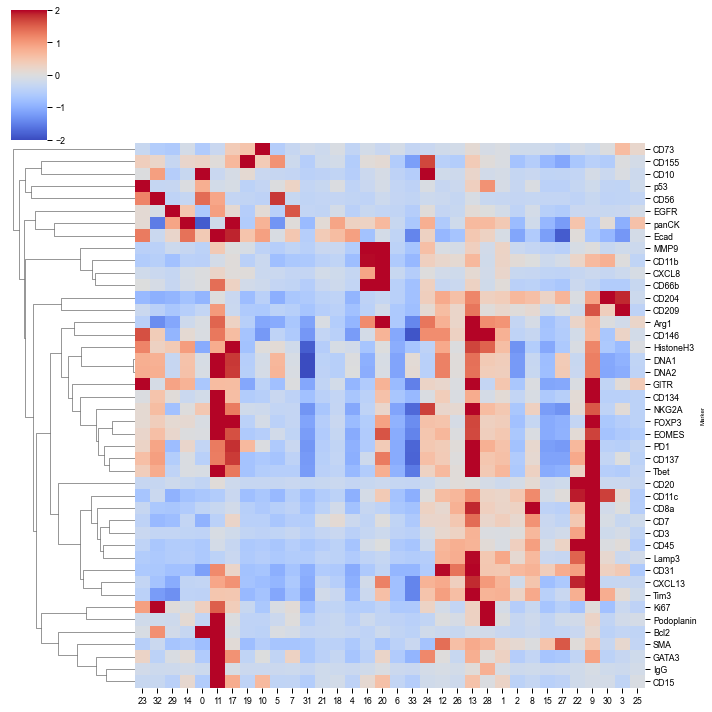

In [39]:
for ct in ['Tumor']:
    print(ct)
    sns.clustermap(
        celltype_to_marker_dfs_clean[ct].loc[MARKERS_CLEAN][META_CLUSTER_PERM], 
        yticklabels=MARKERS_CLEAN,
        z_score=0,
        center=0,
        cmap='coolwarm',
        col_cluster=False,
        vmin=-2,
        vmax=2,
    )
    plt.show()

In [40]:
cc_marker_ct_colors['CN Class'] = numpy.array(meta_cluster_colors)[numpy.argsort(META_CLUSTER_PERM)]

and visualize CC clusters with average marker distributions:

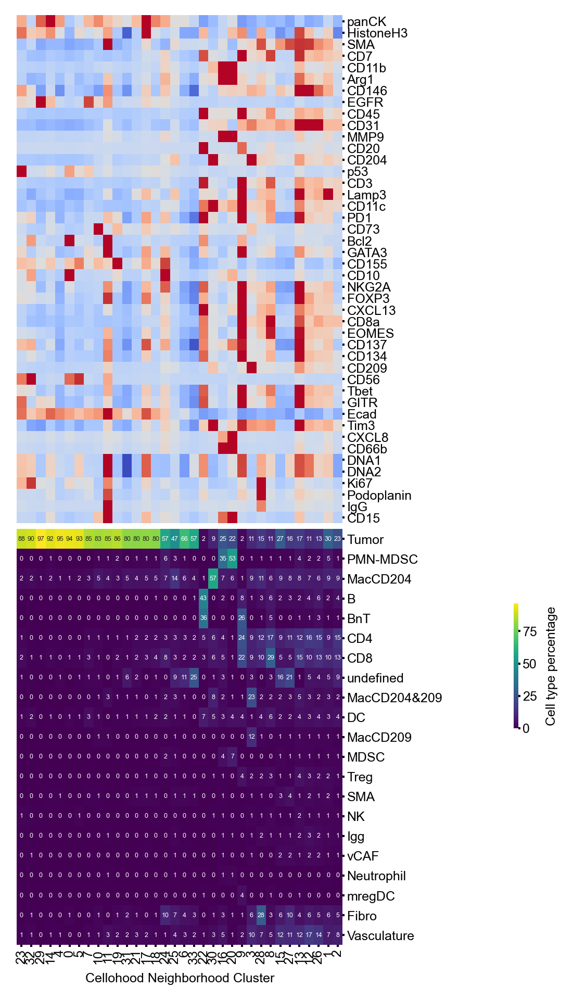

In [41]:
celltype_with_all_markers_clustermap = sns.clustermap(
    celltype_percentages[celltypes].T * 100, 
    annot=True,
    #row_colors=celltypes_color_df,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.25, 0.225, 0.01, 0.1),
    col_colors=all_colors_df,
    annot_kws={'size': 3},
    yticklabels=1,
    colors_ratio=(0.01, 0.01),
    cbar_kws={'label': f'{CELLTYPE_PLOT_NAME} percentage'}
)

celltype_with_all_markers_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_with_all_markers_clustermap.ax_row_dendrogram.set_visible(False)
celltype_with_all_markers_clustermap.ax_col_dendrogram.set_visible(False)

celltype_with_all_markers_clustermap.ax_heatmap.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_with_all_markers_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_with_all_markers_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
celltype_with_all_markers_clustermap.ax_heatmap.set_xticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)

#celltype_with_all_markers_clustermap.ax_row_colors.set_xticklabels(
#    celltype_with_all_markers_clustermap.ax_row_colors.get_xticklabels(), size=6
#)
celltype_with_all_markers_clustermap.ax_col_colors.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_col_colors.get_yticklabels(), size=6
)
celltype_with_all_markers_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

celltype_with_all_markers_clustermap.fig.set_dpi(PLOTTING_DPI)
celltype_with_all_markers_clustermap.fig.set_size_inches((3, 8))


## Density analysis

In [42]:
cc_densities = cell_df.groupby(
    [PREDICTION_CLUSTER_COLUMN, CC_CLUSTER_NAME]
).size().groupby(PREDICTION_CLUSTER_COLUMN).mean()

In [43]:
from collections import defaultdict

celltypes_display_percentage = defaultdict(lambda: 0.1)
celltypes_display_percentage['Tumor'] = 0.1
celltypes_display_percentage['CD4'] = 0.05
celltypes_display_percentage['CD8'] = 0.05
celltypes_display_percentage['MacCD204'] = 0.05
celltypes_display_percentage['MacCD209'] = 0.05
celltypes_display_percentage['MacCD204&209'] = 0.05
#celltypes_display_percentage['Mural'] = 0.14

In [44]:
celltypes_to_marker_to_show = {
    'CD4': ['PD1', 'CD45', 'Tim3'],
    'CD8': ['CD45', 'EOMES', 'PD1', 'CD7', 'Tim3'],
    'Tumor': ['CD73', 'CD155', 'Ecad', 'Bcl2', 'panCK', 'EGFR', 'CD56', 'Ki67', 'p53'],
    'All': ['SMA', 'CD31',  'CD146', 'Lamp3', 'Ki67', 
            'NKG2A', 'Arg1', 'MMP9', 'FOXP3', 'Tbet', 'CXCL8', 'CXCL13',
            'CD134', 'CD137', 'GITR',
           ]
}

In [45]:
celltype_percentages.columns = ['B', 'BnT', 'CD4', 'CD8', 'DC', 'Fibro', 'Igg', 'MDSC', 'MacCD204',
       'MacCD204&209', 'MacCD209', 'NK', 'Neutrophil', 'PMN-MDSC', 'SMA',
       'Treg', 'Tumor', 'Vasculature', 'mregDC', 'undefined', 'vCAF']

In [46]:
celltypes_cc_display = {
    ct: [
        ind_ 
        for ind_, cc_ in enumerate(celltype_percentages[ct] > celltypes_display_percentage[ct])
        if cc_
    ]
    for ct in celltypes_to_marker_to_show
    if ct != 'All'
}

In [47]:
def transform_vec_to_colors(
    vec,
    colors,
    standarize=True,
    display=None,
    permute=None,
    ignore_color=(160 / 255, 160 / 255, 160 / 255),
):
    if standarize:
        display = display if display is not None else numpy.arange(len(vec))
        vec = vec.copy()
        vec = vec - numpy.mean(vec[display])
        vec = vec / numpy.std(vec[display])
    result = [
        colors.to_rgba(x)
        for x in vec
    ]
    if display is not None:
        new_result = []
        for ind_, result_col in enumerate(result):
            current_color = list(result_col)
            if ind_ in display:
                pass 
            else:
                current_color = ignore_color
            new_result.append(current_color)
            
        result = new_result
    if permute:
        result = [
            result[i]
            for i in permute
        ]
    return result

In [48]:
celltype_to_marker_dfs_clean = {
    key if key not in celltype_replacement else celltype_replacement[key]: value
    for key, value in celltype_to_marker_dfs_clean.items()
}

In [49]:
cc_colors_dict = {}
for ct, markers in celltypes_to_marker_to_show.items():
    for marker in markers:
        print(ct, marker)
        cc_colors_dict[f'{ct}: {marker}'] = transform_vec_to_colors( 
                vec=celltype_to_marker_dfs_clean[ct].loc[marker],
                colors=marker_sm,
                display=celltypes_cc_display[ct] if ct in celltypes_cc_display else None,
            )


cc_marker_ct_colors = pandas.DataFrame(cc_colors_dict)

cc_marker_ct_colors['All: Cell density'] = transform_vec_to_colors( 
        vec=cc_densities,
        colors=marker_sm,
)

CD4 PD1
CD4 CD45
CD4 Tim3
CD8 CD45
CD8 EOMES
CD8 PD1
CD8 CD7
CD8 Tim3
Tumor CD73
Tumor CD155
Tumor Ecad
Tumor Bcl2
Tumor panCK
Tumor EGFR
Tumor CD56
Tumor Ki67
Tumor p53
All SMA
All CD31
All CD146
All Lamp3


All Ki67
All NKG2A
All Arg1
All MMP9
All FOXP3
All Tbet
All CXCL8
All CXCL13
All CD134
All CD137
All GITR


In [50]:
cc_marker_ct_colors['CN Class'] = numpy.array(meta_cluster_colors)[numpy.argsort(META_CLUSTER_PERM)]

In [51]:
celltype_replacement = {
    'PMN_MDSC': 'PMN-MDSC',
    'MacCD204_CD209': 'MacCD204&209'
}

def clean_up_celltype(str_, replacement_dict=None):
    if replacement_dict is None:
        replacement_dict = celltype_replacement
    for pattern, replacement in replacement_dict.items():
        if pattern in str_:
            str_ = str_.replace(pattern, replacement)
    return str_

cc_marker_ct_colors.columns = [
    clean_up_celltype(col) for col in cc_marker_ct_colors.columns
]

In [52]:
celltype_percentages.columns = [
    clean_up_celltype(col) for col in celltype_percentages.columns
]

celltypes = [clean_up_celltype(ct) for ct in celltypes]

In [53]:
IMMU_METAS_CLEAN = [
    'Pure Tumor',
    'PMN-MDSC-enriched',
    'Infiltration',
    'TLS',
    'Mac-enriched',
]

/tmp/ipykernel_121012/1373128903.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/tmp/ipykernel_121012/1373128903.py:92: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


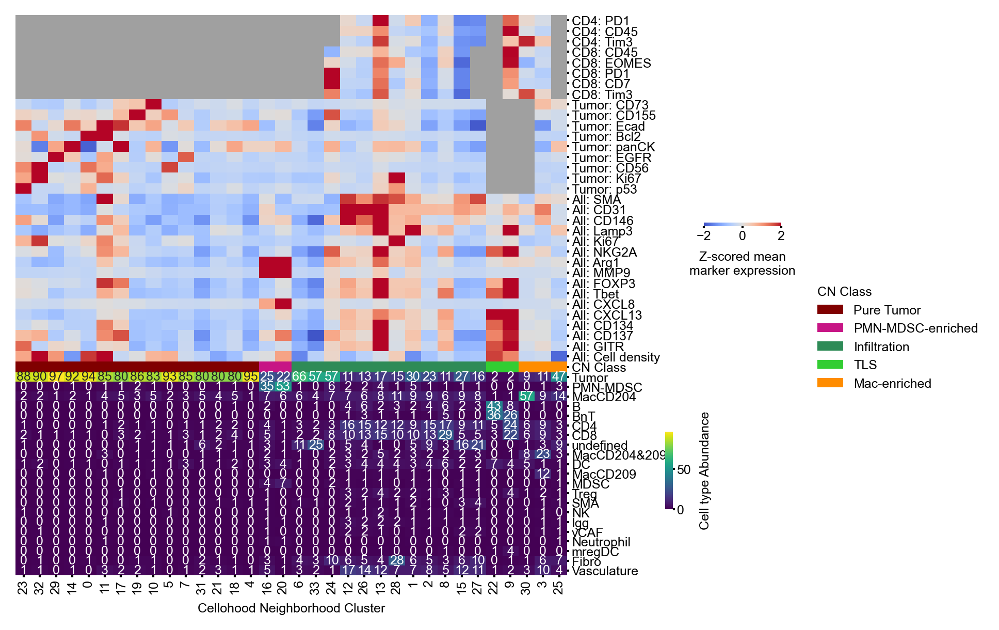

In [54]:
COLORBARS_SHIFT = .98

cc_abundance_std_argsort = (-celltype_percentages['Tumor'].values).argsort()

celltype_clustermap = sns.clustermap(
    (celltype_percentages[celltypes].T * 100)[META_CLUSTER_PERM], 
    annot=True,
    col_cluster=False,
    fmt='.0f',
    cmap='viridis',
    figsize=(12, 8),
    col_colors=cc_marker_ct_colors,
    #row_colors=[class_to_color[celltype_to_class[ct]] for ct in numpy.array(celltypes)],
    colors_ratio=0.015,
    yticklabels=True,
    xticklabels=META_CLUSTER_PERM,
    #linewidth=0.003,
    annot_kws={"size": 6},
    cbar_pos=[COLORBARS_SHIFT + 0.05, 0.15, 0.01, .1],
    cbar_kws={'label': 'Cell type Abundance'}
)


#handles = [Patch(facecolor=class_to_color[name]) for name in class_to_color]
#plt.legend(
#    handles, 
#    class_to_color, 
#    title=' Cell type Metatype',
#    bbox_to_anchor=(0.17, 0.53), 
#    bbox_transform=plt.gcf().transFigure,
#    frameon=False,
#    fontsize=6,
#)

celltype_clustermap.ax_col_dendrogram.set_visible(False)

cb_ax = celltype_clustermap.fig.add_axes([COLORBARS_SHIFT + 0.1, .4, .1, 0.8])
cb_ax.imshow([[0, 1]])
cb_ax.set_visible(False)

cbar = celltype_clustermap.fig.colorbar(
    marker_sm, 
    drawedges=False,
    #bbox_to_anchor=(1, 0.5),
    orientation='horizontal',
    label='Z-scored mean\nmarker expression',
    ax=cb_ax,
    #panchor=(1.5, 0.5),
    #anchor=(1.5, 0.5),
)

cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=6, size=1, pad=1)

meta_handles = [matplotlib.patches.Patch(facecolor=mc_to_c[name]) for name in meta_cluster_dict]

meta_legend = plt.legend(
    meta_handles, 
    IMMU_METAS_CLEAN, 
    title='CN Class',
    bbox_to_anchor=(1.45, .4525), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    ncols=1,
    fontsize=6,
    alignment='left',
    markerfirst=True,
)
plt.gcf().add_artist(meta_legend)

celltype_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_clustermap.ax_row_dendrogram.set_visible(False)
celltype_clustermap.ax_col_dendrogram.set_visible(False)

celltype_clustermap.ax_heatmap.set_yticklabels(celltype_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1)
celltype_clustermap.ax_heatmap.set_xticklabels(celltype_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
celltype_clustermap.ax_col_colors.set_yticklabels(celltype_clustermap.ax_col_colors.get_yticklabels(), size=6)
celltype_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

ax_row_colors = celltype_clustermap.ax_row_colors
ax_col_colors = celltype_clustermap.ax_col_colors
col_box = ax_col_colors.get_position()

box_heatmap = celltype_clustermap.ax_heatmap.get_position()
ax_col_colors.set_position([col_box.x0, box_heatmap.y1, col_box.width, col_box.height])


celltype_clustermap.fig.set_dpi(300)
celltype_clustermap.fig.set_size_inches((5, 5))
plt.tight_layout()

Tumor


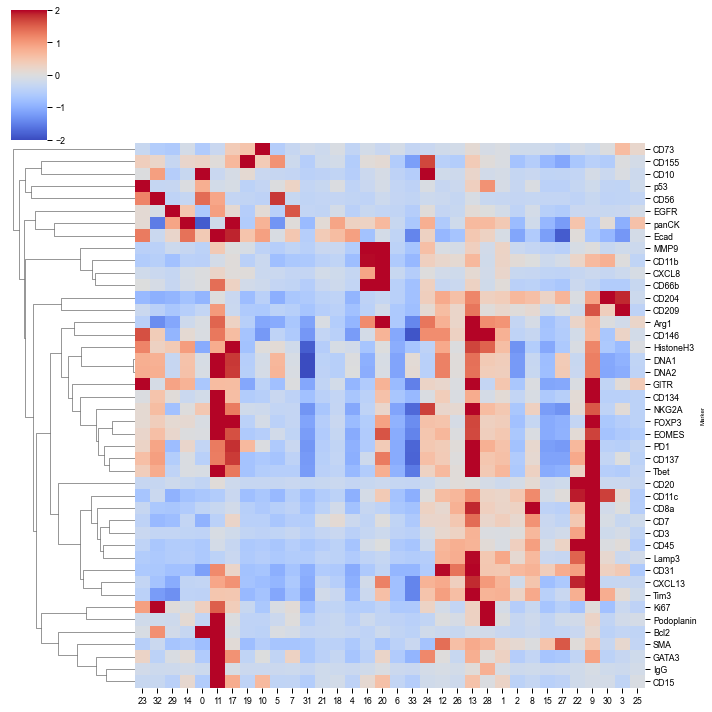

In [55]:
for ct in ['Tumor']:
    print(ct)
    sns.clustermap(
        celltype_to_marker_dfs_clean[ct].loc[MARKERS_CLEAN][META_CLUSTER_PERM], 
        yticklabels=MARKERS_CLEAN,
        z_score=0,
        center=0,
        cmap='coolwarm',
        col_cluster=False,
        vmin=-2,
        vmax=2,
    )
    plt.show()

## Density analysis

In [56]:
cc_densities = cell_df.groupby(
    [PREDICTION_CLUSTER_COLUMN, CC_CLUSTER_NAME]
).size().groupby(PREDICTION_CLUSTER_COLUMN).mean()

## ROI Based Analysis:

Let us start from collection of the roi counts:

In [57]:
roi_counts = pandas.pivot_table(
    cell_df, 
    values=DUMMY_COL_NAME, 
    index=[ROI_COLUMN],
    columns=[PREDICTION_CLUSTER_COLUMN],
    aggfunc="sum",
).fillna(0)

Now, let's clinical data:

In [58]:
clinical_data_df = pandas.read_csv(CLINICAL_DATA_DF)
clinical_data_df['is_squamous'] = clinical_data_df['simple_histology'].apply(lambda x: 'squamous' in x.lower())

In [59]:
image_to_sample = cell_df.groupby(ROI_COLUMN)[SAMPLE_COLUMN].first()

In [60]:
roi_counts[ROI_COLUMN] = roi_counts.index

In [61]:
roi_counts['immucan_id'] = roi_counts['image'].apply(lambda x: image_to_sample[x])
roi_counts['immucan_id'] = roi_counts['immucan_id'].apply(
    lambda x: '-'.join(x.split('-')[:3])
)

In [62]:
roi_counts = pandas.merge(clinical_data_df, roi_counts, on='immucan_id')

In [63]:
roi_counts['patient'] = roi_counts['immucan_id']

## Core correlations analysis:

Let us start with obtaining general Cellohood cluster counts:

In [64]:
cluster_counts = cell_df.groupby(PREDICTION_CLUSTER_COLUMN).size()

Now - let's visualize Clusters correlations and counts:

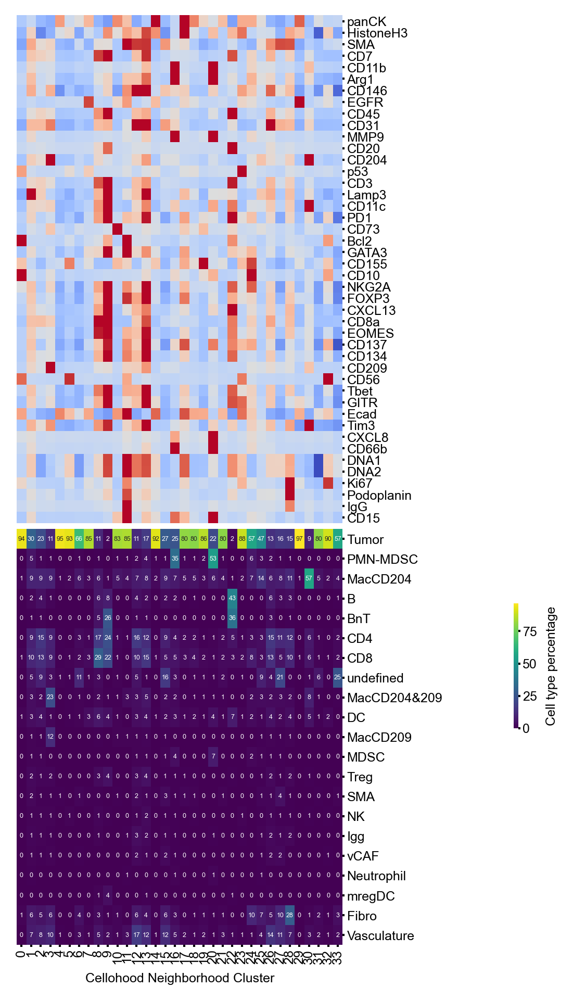

In [65]:
celltype_with_all_markers_clustermap = sns.clustermap(
    celltype_percentages[celltypes].T * 100, #[corr_cmap.data2d.index] * 100, 
    annot=True,
    #row_colors=celltypes_color_df,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.25, 0.225, 0.01, 0.1),
    col_colors=all_colors_df,
    col_cluster=False,
    annot_kws={'size': 3},
    yticklabels=1,
    colors_ratio=(0.01, 0.01),
    cbar_kws={'label': f'{CELLTYPE_PLOT_NAME} percentage'}
)

celltype_with_all_markers_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_with_all_markers_clustermap.ax_row_dendrogram.set_visible(False)
celltype_with_all_markers_clustermap.ax_col_dendrogram.set_visible(False)

celltype_with_all_markers_clustermap.ax_heatmap.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_with_all_markers_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_with_all_markers_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
celltype_with_all_markers_clustermap.ax_heatmap.set_xticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)

#celltype_with_all_markers_clustermap.ax_row_colors.set_xticklabels(
#    celltype_with_all_markers_clustermap.ax_row_colors.get_xticklabels(), size=6
#)
celltype_with_all_markers_clustermap.ax_col_colors.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_col_colors.get_yticklabels(), size=6
)
celltype_with_all_markers_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

celltype_with_all_markers_clustermap.fig.set_dpi(PLOTTING_DPI)
celltype_with_all_markers_clustermap.fig.set_size_inches((3, 8))


## Cluster number selection:

Let us run the algorithm for the cluster number selection:

In [66]:
start_time = time.time()


if os.path.exists(PANEL_1_CLUSTER_SELECTION_PATH):
    with open(PANEL_1_CLUSTER_SELECTION_PATH, 'rb') as handle:
        cs_result = pickle.load(handle)
        cs_best_clusterers = cimu.get_best_clusters_from_cimu_result(cs_result)
else:
    cs_result, cs_best_clusterers = tau.perform_cluster_selection(
        cluster_counts, 
        list(range(PANEL_1_NB_OF_CLUSTERS)),
        vectorization_function=VECTORIZER,
        nb_of_tries_per_cluster_nb=10,
    )
    os.makedirs(CLUSTER_SELECTION_PATH, exist_ok=True)
    with open(PANEL_1_CLUSTER_SELECTION_PATH, 'wb') as handle:
        pickle.dump(panel_1_cs_result, handle)

print(time.time() - start_time)

0.20913410186767578


and let us have a look at found cluster numbers:

In [67]:
cs_best_clusterers

{11: MiniBatchKMeans(n_clusters=11, n_init='auto', random_state=129),
 17: MiniBatchKMeans(n_clusters=17, n_init='auto', random_state=183),
 26: MiniBatchKMeans(n_clusters=26, n_init='auto', random_state=279)}

## Patient Clustermap

In [68]:
ROI_CLUSTERS = 11
clusterer = cs_best_clusterers[ROI_CLUSTERS]




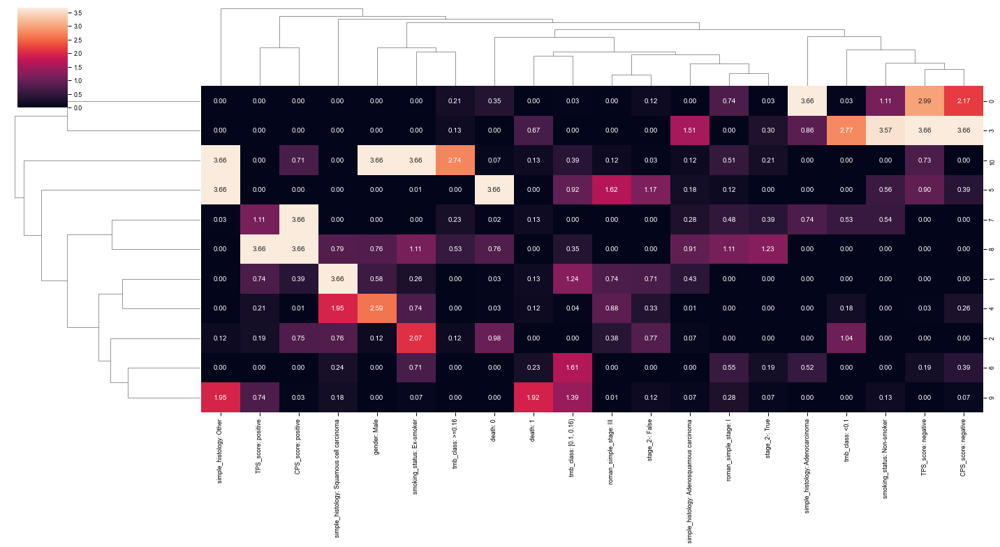

In [69]:
_, vectors, clusters, clusterer, qvals = tau.visualize_patient_clusters_with_survival_analysis_and_hg_no_lung(
    patients_df=roi_counts,
    clusterer_type=clusterer,
    clusters_to_select=list(range(CC_NB_OF_CLUSTERS)),
    hypergeometric_columns=CLINICAL_DATA_COLS_FOR_ANALYSIS,
    vectorization_function=VECTORIZER, 
    filter_below_percentage=0.01,
    cmap='seismic',
    number_of_clusters=ROI_CLUSTERS,
    hypergeometric_fdr_alpha=0.1,
    hypergeometric_filter_nas=True,
)

In [70]:
from collections import defaultdict

import matplotlib.colors as mpc


hist_to_int = {
    'Adenocarcinoma': 0, 
    'Squamous cell carcinoma': 1, 
    'Other': 2,
    'Adenosquamous carcinoma': 3,
}


tmb_colors_dict = defaultdict(lambda: mpc.TABLEAU_COLORS['tab:cyan'])
tmb_colors_dict['[0.1, 0.16)'] = mpc.CSS4_COLORS['goldenrod']
tmb_colors_dict['>=0.16'] = mpc.CSS4_COLORS['maroon']
tmb_colors_dict['<0.1'] = mpc.CSS4_COLORS['limegreen']

In [71]:
UNK_COLOR = mpc.CSS4_COLORS['lightgrey']

HISTOLOGY_PLOT_NAME = 'Histology'
STAGE_PLOT_NAME = 'Stage'
TMB_PLOT_NAME = 'TMB'
DEATH_PLOT_NAME = 'Death'
CPS_PLOT_NAME = 'CPS'
TPS_PLOT_NAME = 'TPS'
GENDER_PLOT_NAME = 'Gender'
SMOKING_PLOT_NAME = 'Smoking'

# Genes
KRAS_PLOT_NAME = 'GM: KRAS'
TP53_PLOT_NAME = 'GM: TP53'
EGFR_PLOT_NAME = 'GM: EGFR'
PIK3CA_PLOT_NAME = 'GM: PIK3CA'
ERBB2_PLOT_NAME = 'GM: ERBB2'
ENV_EXP_NAME = 'Env.Exp.'

In [72]:
patient_to_clinical_colors_dict = {}

# Histology
patient_to_clinical_colors_dict[HISTOLOGY_PLOT_NAME] = [
    tau.SIMPLE_HISTOLOGY_COLORS[hist] for hist in roi_counts['simple_histology']
]

# Stage
patient_to_clinical_colors_dict[STAGE_PLOT_NAME] = [
    tau.SIMPLE_STAGE_COLORS[st] for st in roi_counts['simple_stage']
]

# TMB
tmb_color = defaultdict(lambda: UNK_COLOR)
tmb_color['[0.1, 0.16)'] = mpc.CSS4_COLORS['goldenrod']
tmb_color['>=0.16'] = mpc.CSS4_COLORS['maroon']
tmb_color['<0.1'] = mpc.CSS4_COLORS['limegreen']
patient_to_clinical_colors_dict[TMB_PLOT_NAME] = [
    tmb_color[st] for st in roi_counts['tmb_class']
]

# Death
death_color = defaultdict(lambda: UNK_COLOR)
death_color[True] = mpc.CSS4_COLORS['red']
death_color[False] = mpc.CSS4_COLORS['black']
patient_to_clinical_colors_dict[DEATH_PLOT_NAME] = [
    death_color[st] for st in roi_counts['death']
]

# CPS
cps_color = defaultdict(lambda: UNK_COLOR)
cps_color['positive'] = mpc.CSS4_COLORS['blue']
cps_color['negative'] = mpc.CSS4_COLORS['black']
patient_to_clinical_colors_dict[CPS_PLOT_NAME] = [
    cps_color[st] for st in roi_counts['CPS_score']
]

# TPS
tps_color = defaultdict(lambda: UNK_COLOR)
tps_color['positive'] = mpc.CSS4_COLORS['blue']
tps_color['negative'] = mpc.CSS4_COLORS['black']
patient_to_clinical_colors_dict[TPS_PLOT_NAME] = [
    tps_color[st] for st in roi_counts['TPS_score']
]

# gender therapy
neo_color = defaultdict(lambda: UNK_COLOR)
neo_color['Male'] = mpc.CSS4_COLORS['blue']
neo_color['Female'] = mpc.CSS4_COLORS['red']
patient_to_clinical_colors_dict[GENDER_PLOT_NAME] = [
    neo_color[st] for st in roi_counts['gender']
]

# # GENES:
# gene_color = defaultdict(lambda: UNK_COLOR)
# gene_color[True] = mpc.CSS4_COLORS['white']
# gene_color[False] = mpc.CSS4_COLORS['black']

# # KRAS:
# patient_to_clinical_colors_dict[KRAS_PLOT_NAME] = [
#     gene_color[st] for st in roi_counts['KRAS']
# ]

# # TP53
# patient_to_clinical_colors_dict[TP53_PLOT_NAME] = [
#     gene_color[st] for st in roi_counts['TP53']
# ]

# #EGFR
# patient_to_clinical_colors_dict[EGFR_PLOT_NAME] = [
#     gene_color[st] for st in roi_counts['EGFR']
# ]

# # PIK3CA
# patient_to_clinical_colors_dict[PIK3CA_PLOT_NAME] = [
#     gene_color[st] for st in roi_counts['PIK3CA']
# ]

# # ERBB2
# patient_to_clinical_colors_dict[ERBB2_PLOT_NAME] = [
#     gene_color[st] for st in roi_counts['ERBB2']
# ]

env_color = defaultdict(lambda: UNK_COLOR)
env_color['None'] = mpc.CSS4_COLORS['black']
env_color['Asbestos'] = mpc.CSS4_COLORS['yellowgreen']
env_color['Chemical agent'] = mpc.CSS4_COLORS['yellow']
env_color['Other'] = mpc.CSS4_COLORS['orange']

smoking_colors = {
    'Ex-smoker': '#d95f02',      # Orange
    'Current smoker': '#7570b3',  # Purple
    'Non-smoker': '#1b9e77'      # Green-blue
}


patient_to_clinical_colors_dict[SMOKING_PLOT_NAME] = [
    smoking_colors[x] for x in roi_counts['smoking_status']
]

# patient_to_clinical_colors_dict[ENV_EXP_NAME] = [
#     env_color[st] for st in roi_counts['environmental_exposure']
# ]

patient_to_clinical_colors_df = pandas.DataFrame(patient_to_clinical_colors_dict)

In [73]:
centers = []
bars = [0]
aux = 0


for cl_ in range(ROI_CLUSTERS):
    current_cluster_count = (clusters == cl_).sum()
    centers.append(aux + current_cluster_count // 2)
    aux += current_cluster_count
    bars.append(aux - 1)

    
ticks = []
current_cluster = 0

for i in range(len(clusters)):
    if i in centers:
        ticks.append(current_cluster)
        current_cluster += 1
        continue
    elif i in bars:
        ticks.append('|')
        continue
    else:
        ticks.append('')
        

In [74]:
horizontal_ticks = [
    str(tick).replace('|', '—') 
    for tick in ticks
]

/tmp/ipykernel_121012/2539302664.py:55: UserWarning: FixedFormatter should only be used together with FixedLocator
  barplot_ax.set_xticklabels(


array([2.71, 2.71])

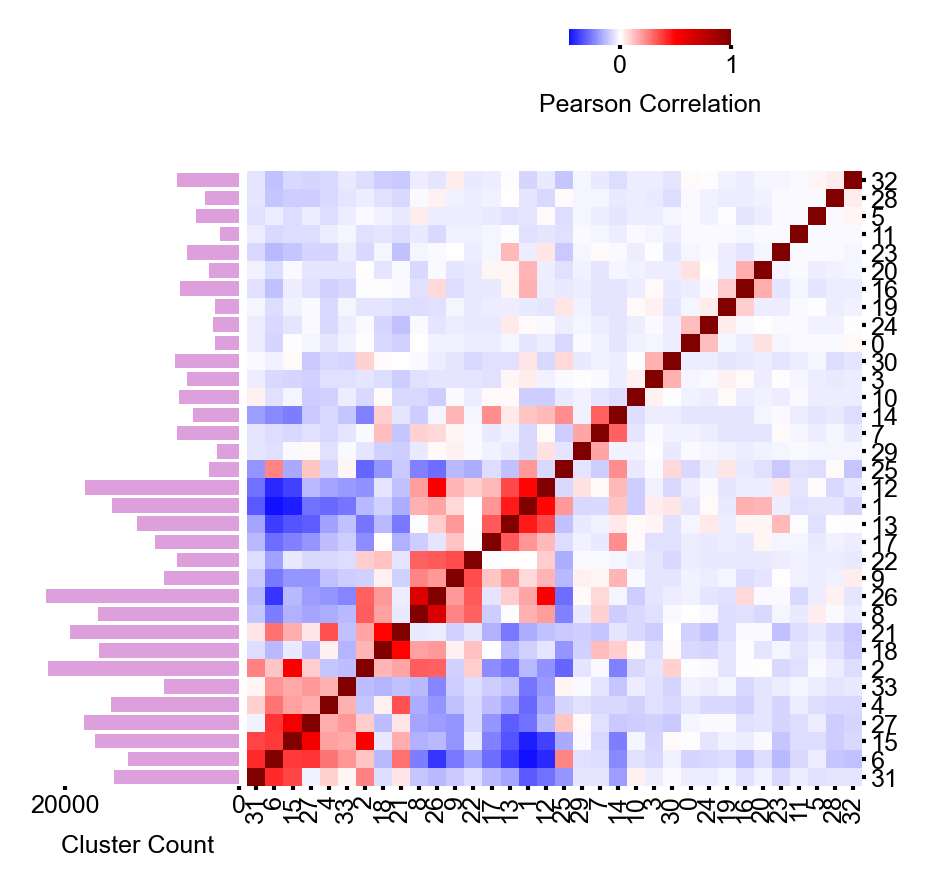

In [75]:
corr_df = roi_counts[list(range(CC_NB_OF_CLUSTERS))].corr()
#corr_df.index.name = 'Cellohood Neighborhood Cluster'
#corr_df.columns.name = 'Cellohood Neighborhood Cluster'

#matplotlib.rcParams.update(matplotlib.rcParamsDefault)

#sns.set_context("paper", rc={"font.size": 6, "axes.titlesize":6,"axes.labelsize":6})  
#plt.rcParams['legend.title_fontsize'] = 6
#plt.rcParams['legend.fontsize'] = 6
#matplotlib.rcParams['font.family'] = 'Arial'


corr_cmap = sns.clustermap(
    corr_df,
    center=0,
    cmap='seismic',
    xticklabels=True,
    yticklabels=True,
    #annot=True,
    #fmt='.2f',
    #annot_kws={'size': 3},
    cbar_pos=[0.6, 0.95, 0.2, 0.02],
    cbar_kws={'label': 'Pearson Correlation', 'orientation': 'horizontal'}
)

corr_cmap.ax_row_dendrogram.set_visible(False)
corr_cmap.ax_col_dendrogram.set_visible(False)
#corr_cmap.ax_cbar.set_visible(False)

hm_pos = corr_cmap.ax_heatmap.get_position()

BOX_WIDTH = 0.25
BOX_SPACE = 0.01

barplot_ax = corr_cmap.fig.add_axes([hm_pos.x0 - BOX_WIDTH - BOX_SPACE, hm_pos.y0, BOX_WIDTH, hm_pos.height], sharey=corr_cmap.ax_heatmap)


#barplot_ax = corr_cmap.fig.add_axes([-.11, 0.045, .3, .755], sharey=corr_cmap.ax_heatmap)
barplot_ax.barh(
    numpy.arange(len(corr_cmap.data2d.columns)) + 0.5,
    cluster_counts.loc[corr_cmap.data2d.columns],
    align='center',
    height=0.8,
    color='plum',
)
barplot_ax.invert_yaxis()
barplot_ax.invert_xaxis()
barplot_ax.spines['left'].set_visible(False)
barplot_ax.spines['top'].set_visible(False)
barplot_ax.spines['right'].set_visible(False)
barplot_ax.spines['bottom'].set_visible(False)
barplot_ax.yaxis.set_visible(False)
barplot_ax.set_xlabel('Cluster Count', size=6)
barplot_ax.xaxis.set_tick_params(size=1, left=True, pad=1)
barplot_ax.set_xticklabels(
    barplot_ax.get_xticklabels(), size=6, rotation=0
)
barplot_ax.set_facecolor('white')

corr_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
corr_cmap.ax_row_dendrogram.set_visible(False)
corr_cmap.ax_col_dendrogram.set_visible(False)



# NOTE: full_cc_colors_with_ct is defined later in the notebook (out-of-order
# editing artifact); guard rather than fail here -- ticks keep default color.
try:
    for tick in corr_cmap.ax_heatmap.get_xticklabels():
        tick.set_color(full_cc_colors_with_ct.iloc[int(tick.get_text())]['CN Class'])

    for tick in corr_cmap.ax_heatmap.get_yticklabels():
        tick.set_color(full_cc_colors_with_ct.iloc[int(tick.get_text())]['CN Class'])
except (NameError, KeyError):
    pass

corr_cmap.ax_heatmap.set_yticklabels(
    corr_cmap.ax_heatmap.get_yticklabels(), size=6)
corr_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
corr_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
corr_cmap.ax_heatmap.set_xticklabels(
    corr_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90)

corr_cmap.fig.set_dpi(PLOTTING_DPI)
corr_cmap.fig.set_size_inches((2.71, 2.71))
plt.gcf().get_size_inches()

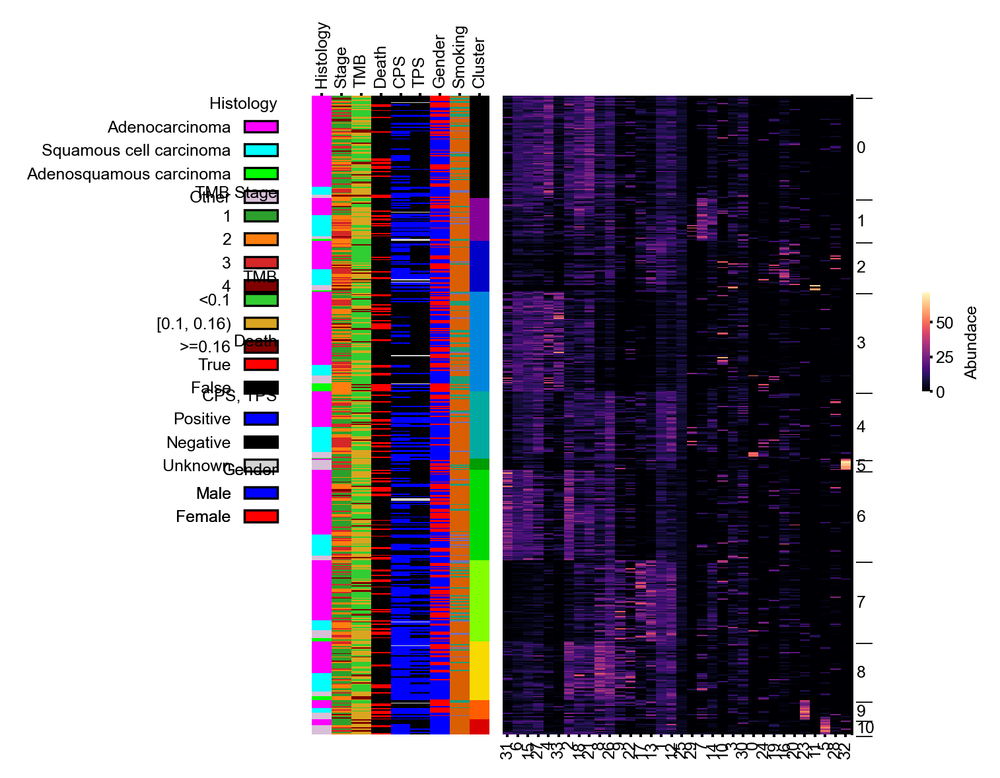

In [76]:
plt.rcParams['font.family'] = 'Arial'

cluster_norm = matplotlib.colors.Normalize(vmin=0, vmax=ROI_CLUSTERS)
cluster_cmap = plt.get_cmap('nipy_spectral')

cluster_sm = matplotlib.cm.ScalarMappable(norm=cluster_norm, cmap=cluster_cmap)

vectors_df = pandas.DataFrame(
    vectors.T,
    index=patient_to_clinical_colors_df.index,
)
#vectors_df.index.name = ROI_PLOT_NAME
#vectors_df.columns.name = CC_PLOT_NAME


patient_to_clinical_colors_df['Cluster'] = [cluster_sm.to_rgba(x) for x in clusters]

BASE = 30

hist_to_int = {
    'Adenocarcinoma': 0, 
    'Squamous cell carcinoma': 1, 
    'Other': 2,
    'Adenosquamous carcinoma': 3,
}

clusters_with_histology = clusters.copy()

for ind_, (cl, hist) in enumerate(zip(clusters_with_histology, roi_counts['simple_histology'])):
    clusters_with_histology[ind_] = BASE * cl + hist_to_int[hist]

patient_clustermap = sns.clustermap( 
    vectors_df.iloc[clusters_with_histology.argsort()].T.iloc[corr_cmap.data2d.index].T,
    col_cluster=False,
    row_cluster=False,
    xticklabels=1,
    cbar_pos=[.99, 0.5, 0.01, .1],
    cbar_kws={'label': 'Abundace'},
    yticklabels=horizontal_ticks,
    row_colors=patient_to_clinical_colors_df,
    figsize=(4, 5),
    cmap='magma',
)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(rotation=0)

patient_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
patient_clustermap.ax_row_dendrogram.set_visible(False)
patient_clustermap.ax_col_dendrogram.set_visible(False)

patient_clustermap.ax_heatmap.set_yticklabels(
    patient_clustermap.ax_heatmap.get_yticklabels(), size=6)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
patient_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
patient_clustermap.ax_heatmap.set_xticklabels(
    patient_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)


patient_clustermap.ax_row_colors.xaxis.set_tick_params(size=1, top=True, pad=2, rotation=90)
patient_clustermap.ax_row_colors.set_xticklabels(
    patient_clustermap.ax_row_colors.get_xticklabels(), size=6,
)
patient_clustermap.ax_row_colors.xaxis.tick_top()
#patient_clustermap.ax_col_colors.set_yticklabels(
#    patient_clustermap.ax_col_colors.get_yticklabels(), size=6
#)
#patient_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

LEGEND_SPACING = 0.195

GOOD_HISTS = ['Adenocarcinoma', 'Squamous cell carcinoma', 'Adenosquamous carcinoma', 'Other']

pos_neg_handles = [
    matplotlib.patches.Patch(
        facecolor=tau.SIMPLE_HISTOLOGY_COLORS[name], 
        edgecolor='black') for name in GOOD_HISTS
]
pos_neg_legend = plt.legend(
    pos_neg_handles, 
    GOOD_HISTS, 
    title='Histology',
    bbox_to_anchor=(LEGEND_SPACING, .8125), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(pos_neg_legend)

GOOD_STAGES = [1, 2, 3, 4]

grade_handles = [
    matplotlib.patches.Patch(facecolor=tau.SIMPLE_STAGE_COLORS[name], edgecolor='black') 
    for name in GOOD_STAGES
]
grade_legend = plt.legend(
    grade_handles, 
    GOOD_STAGES, 
    title='TMB Stage',
    bbox_to_anchor=(LEGEND_SPACING, .7225), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(grade_legend)

GOOD_TMB = ['<0.1', '[0.1, 0.16)', '>=0.16']

tmb_handles = [
    matplotlib.patches.Patch(facecolor=tmb_color[name], edgecolor='black')
    for name in GOOD_TMB
]
tmb_legend = plt.legend(
    tmb_handles, 
    GOOD_TMB, 
    title='TMB',
    bbox_to_anchor=(LEGEND_SPACING, .6375), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(tmb_legend)

death_handles = [
    matplotlib.patches.Patch(facecolor=death_color[name], edgecolor='black') 
    for name in death_color
]
death_legend = plt.legend(
    death_handles, 
    death_color, 
    title='Death',
    bbox_to_anchor=(LEGEND_SPACING, .5725), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(death_legend)

GOOD_TPSES = ['Positive', 'Negative', 'Unknown']

ps_handles = [
    matplotlib.patches.Patch(facecolor=tps_color[name], edgecolor='black')
    for name in tps_color
]
ps_legend = plt.legend(
    ps_handles, 
    GOOD_TPSES,
    title='CPS, TPS',
    bbox_to_anchor=(LEGEND_SPACING, .5175), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(ps_legend)

neo_handles = [
    matplotlib.patches.Patch(facecolor=neo_color[x], edgecolor='black')
    for x in neo_color
]
neo_legend = plt.legend(
    neo_handles, 
    neo_color, 
    title=f'{GENDER_PLOT_NAME}',
    bbox_to_anchor=(LEGEND_SPACING, .4425), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(neo_legend)

patient_clustermap.fig.set_dpi(PLOTTING_DPI)
#patient_clustermap.fig.set_size_inches((4, 8))

In [77]:
PC_PLOT_COLS = ['Histology', 'Stage', 'TMB', 'Death', 'CPS', 'TPS', 'Gender', 'Smoking']

In [78]:
horizontal_ticks = [
    str(tick).replace('|', '—') 
    for tick in ticks
]

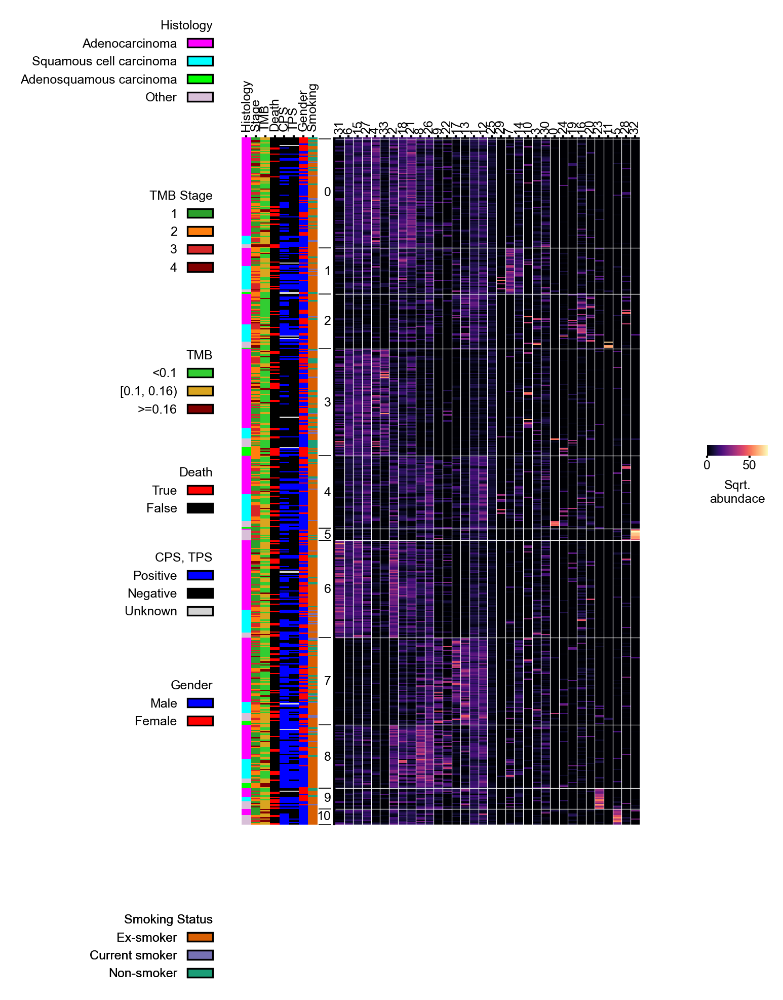

In [79]:
plt.rcParams['font.family'] = 'Arial'

cluster_norm = matplotlib.colors.Normalize(vmin=0, vmax=ROI_CLUSTERS)
cluster_cmap = plt.get_cmap('nipy_spectral')

cluster_sm = matplotlib.cm.ScalarMappable(norm=cluster_norm, cmap=cluster_cmap)

vectors_df = pandas.DataFrame(
    vectors.T,
    index=patient_to_clinical_colors_df.index,
)
#vectors_df.index.name = ROI_PLOT_NAME
#vectors_df.columns.name = CC_PLOT_NAME


patient_to_clinical_colors_df['Cluster'] = [cluster_sm.to_rgba(x) for x in clusters]

BASE = 30

hist_to_int = {
    'Adenocarcinoma': 0, 
    'Squamous cell carcinoma': 1, 
    'Other': 2,
    'Adenosquamous carcinoma': 3,
}

clusters_with_histology = clusters.copy()

for ind_, (cl, hist) in enumerate(zip(clusters_with_histology, roi_counts['simple_histology'])):
    clusters_with_histology[ind_] = BASE * cl + hist_to_int[hist]

patient_clustermap = sns.clustermap( 
    vectors_df.iloc[clusters_with_histology.argsort()].T.iloc[corr_cmap.data2d.index].T,
    col_cluster=False,
    row_cluster=False,
    xticklabels=1,
    cbar_pos=[.99, 0.5, 0.1, .01],
    cbar_kws={'label': 'Sqrt.\nabundace', 'orientation': 'horizontal'},
    yticklabels=horizontal_ticks,
    colors_ratio=0.02,
    row_colors=patient_to_clinical_colors_df[PC_PLOT_COLS],
    figsize=(3.3, 5),
    cmap='magma',
)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(rotation=0)

patient_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
patient_clustermap.ax_row_dendrogram.set_visible(False)
patient_clustermap.ax_col_dendrogram.set_visible(False)

patient_clustermap.ax_heatmap.set_yticklabels(
    patient_clustermap.ax_heatmap.get_yticklabels(), size=6)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
patient_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
patient_clustermap.ax_heatmap.set_xticklabels(
    patient_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
patient_clustermap.ax_heatmap.xaxis.tick_top()

patient_clustermap.ax_row_colors.xaxis.set_tick_params(size=1, top=True, pad=2, rotation=90)
patient_clustermap.ax_row_colors.set_xticklabels(
    patient_clustermap.ax_row_colors.get_xticklabels(), size=6,
)
patient_clustermap.ax_row_colors.xaxis.tick_top()

#patient_clustermap.ax_col_colors.set_yticklabels(
#    patient_clustermap.ax_col_colors.get_yticklabels(), size=6
#)
#patient_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

LEGEND_SPACING = 0.195

GOOD_HISTS = ['Adenocarcinoma', 'Squamous cell carcinoma', 'Adenosquamous carcinoma', 'Other']

pos_neg_handles = [
    matplotlib.patches.Patch(
        facecolor=tau.SIMPLE_HISTOLOGY_COLORS[name], 
        edgecolor='black') for name in GOOD_HISTS
]
pos_neg_legend = plt.legend(
    pos_neg_handles, 
    GOOD_HISTS, 
    title='Histology',
    bbox_to_anchor=(LEGEND_SPACING, .92), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(pos_neg_legend)

GOOD_STAGES = [1, 2, 3, 4]

grade_handles = [
    matplotlib.patches.Patch(facecolor=tau.SIMPLE_STAGE_COLORS[name], edgecolor='black') 
    for name in GOOD_STAGES
]
grade_legend = plt.legend(
    grade_handles, 
    GOOD_STAGES, 
    title='TMB Stage',
    bbox_to_anchor=(LEGEND_SPACING, .76), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(grade_legend)

GOOD_TMB = ['<0.1', '[0.1, 0.16)', '>=0.16']

tmb_handles = [
    matplotlib.patches.Patch(facecolor=tmb_color[name], edgecolor='black')
    for name in GOOD_TMB
]
tmb_legend = plt.legend(
    tmb_handles, 
    GOOD_TMB, 
    title='TMB',
    bbox_to_anchor=(LEGEND_SPACING, .61), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(tmb_legend)

death_handles = [
    matplotlib.patches.Patch(facecolor=death_color[name], edgecolor='black') 
    for name in death_color
]
death_legend = plt.legend(
    death_handles, 
    death_color, 
    title='Death',
    bbox_to_anchor=(LEGEND_SPACING, .5), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(death_legend)

GOOD_TPSES = ['Positive', 'Negative', 'Unknown']

ps_handles = [
    matplotlib.patches.Patch(facecolor=tps_color[name], edgecolor='black')
    for name in tps_color
]
ps_legend = plt.legend(
    ps_handles, 
    GOOD_TPSES,
    title='CPS, TPS',
    bbox_to_anchor=(LEGEND_SPACING, .42), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(ps_legend)

neo_handles = [
    matplotlib.patches.Patch(facecolor=neo_color[x], edgecolor='black')
    for x in neo_color
]
neo_legend = plt.legend(
    neo_handles, 
    neo_color, 
    title=f'{GENDER_PLOT_NAME}',
    bbox_to_anchor=(LEGEND_SPACING, .3), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(neo_legend)



sst_handles = [
    matplotlib.patches.Patch(facecolor=smoking_colors[x], edgecolor='black')
    for x in smoking_colors
]
sst_legend = plt.legend(
    sst_handles, 
    smoking_colors, 
    title='Smoking Status',
    bbox_to_anchor=(LEGEND_SPACING, .08), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(sst_legend)

# NOTE: full_cc_colors_with_ct is defined later in the notebook (out-of-order
# editing artifact); guard rather than fail here -- ticks keep default color.
try:
    for tick in patient_clustermap.ax_heatmap.get_xticklabels():
        tick.set_color(full_cc_colors_with_ct.iloc[int(tick.get_text())]['CN Class'])
except (NameError, KeyError):
    pass

ax_row_colors = patient_clustermap.ax_row_colors
row_box = ax_row_colors.get_position()

box_heatmap = patient_clustermap.ax_heatmap.get_position()
ax_row_colors.set_position([box_heatmap.x0 - row_box.width - 0.029, row_box.y0, row_box.width, row_box.height])

patient_clustermap.fig.set_dpi(PLOTTING_DPI)
patient_clustermap.ax_heatmap.yaxis.tick_left()
patient_clustermap.fig.set_size_inches((4, 7))

for i in range(1, vectors_df.shape[1]):
    patient_clustermap.ax_heatmap.vlines(i, 0, vectors_df.shape[0], linewidth=0.3, color="white")

for bar in bars:
    patient_clustermap.ax_heatmap.hlines(bar + 1, 0, vectors_df.shape[1], linewidth=0.3, color="white")

## Clinical Data analysis

In [80]:
roi_counts[DUMMY_COL_NAME] = 1
roi_counts[ROI_CLUSTER_NAME] = clusters

In [81]:
roi_cluster_counts = pandas.pivot_table(
    roi_counts, 
    values=DUMMY_COL_NAME, 
    index=['immucan_id'],
    columns=[ROI_CLUSTER_NAME],
    aggfunc="sum",
).fillna(0) > 0

In [82]:
roi_cluster_counts.shape

(189, 11)

In [83]:
ROI_CLUSTER_NAMES = [f'{ROI_CLUSTER_NAME}: {cl_}' for cl_ in roi_cluster_counts.columns]

ROI_CLUSTER_INDICES = list(roi_cluster_counts.columns)
roi_cluster_counts.columns = ROI_CLUSTER_NAMES
roi_cluster_counts.index.name = 'immucan_id'

In [84]:
roi_cluster_with_clinical = pandas.merge(roi_cluster_counts, clinical_data_df, on='immucan_id')

Now, let's filter out patients with percentage lower than `0.04`.

In [85]:
PERCENTAGE_TO_FILTER_OUT = 0.00

GOOD_ROI_CLUSTERS = [
    cl 
    for cl, row in roi_cluster_with_clinical[ROI_CLUSTER_NAMES].mean(axis=0).to_frame().iterrows()
    if row[0] > PERCENTAGE_TO_FILTER_OUT
]


GOOD_ROI_CLUSTERS_INDS = [
    row_nb 
    for row_nb, (cl, row) in enumerate(roi_cluster_with_clinical[ROI_CLUSTER_NAMES].mean(axis=0).to_frame().iterrows())
    if row[0] > PERCENTAGE_TO_FILTER_OUT
]

Now, let us compute a table with enrichements scores for clusters and clinical features, for subgroups of patients that have a particular ROI cluster:

In [86]:
import matplotlib.pyplot as plt


roi_pval_table = pandas.concat(
    [
        pandas.concat(
            [
                tau.compute_hypergeometrics_for_df(
                    df=roi_cluster_with_clinical,
                    clusters=roi_cluster_with_clinical[cluster] > 0,
                    column=column,
                    values=None,
                    filter_nas=True,
            ).iloc[[1]]
            for column in CLINICAL_DATA_COLS_FOR_ANALYSIS],
            axis=1,
        )
        for cluster in GOOD_ROI_CLUSTERS
    ],
    axis=0,
)

roi_pval_table.index = [
    f'{cluster}'
    for cluster in GOOD_ROI_CLUSTERS
]

Now, let's compute the FDR corrected p-values:

In [87]:
roi_qval_table = tau.apply_fdr_to_df(roi_pval_table)

Now, let's clean out the names of the clinical features:

In [88]:
raw_clinical_to_clean_clinical_names = {
    'smoking_status: ': '',
    '_score:': ':',
    'positive': 'Positive',
    'negative': 'Negative',
    'roman_simple_stage': 'TNM:',
    'simple_histology': 'Histology',
    'tmb_class': 'TMB',
    'stage_2-: False': 'TNM: 3, 4',
    'neo_adjuvant_treatment:': 'NeoAdj. Treat.:',
    'gender: ': '',
    'environmental_exposure': 'Env. Exposure',
    'KRAS': 'GM: KRAS',
    'PIK3CA': 'GM: PIK3CA',
    'EGFR': 'GM: EGFR',
    'TP53': 'GM: TP53',
    'ERBB2': 'GM: ERBB2',
    'death: 1': 'Death: True',
    'death: 0': 'Death: False'
}

def clean_clinical_name(name, replacement_dict=None):
    if replacement_dict is None:
        replacement_dict = raw_clinical_to_clean_clinical_names
    for raw_name, clean_name in replacement_dict.items():
        name = name.replace(raw_name, clean_name)
    return name

In [89]:
roi_qval_table.columns = [clean_clinical_name(col) for col in roi_qval_table.columns]

Now, let's filter out the cases with `FDR_ALPHA` and lower scores:

In [90]:
FDR_ALPHA = 0.2

q_vals_sig_series = roi_qval_table.min() < FDR_ALPHA

sl_qvals_text = roi_qval_table.copy()
sl_qvals_text = sl_qvals_text.applymap(lambda x: str(round(x, 2)) if x < FDR_ALPHA  else '')

<Figure size 3600x2400 with 0 Axes>

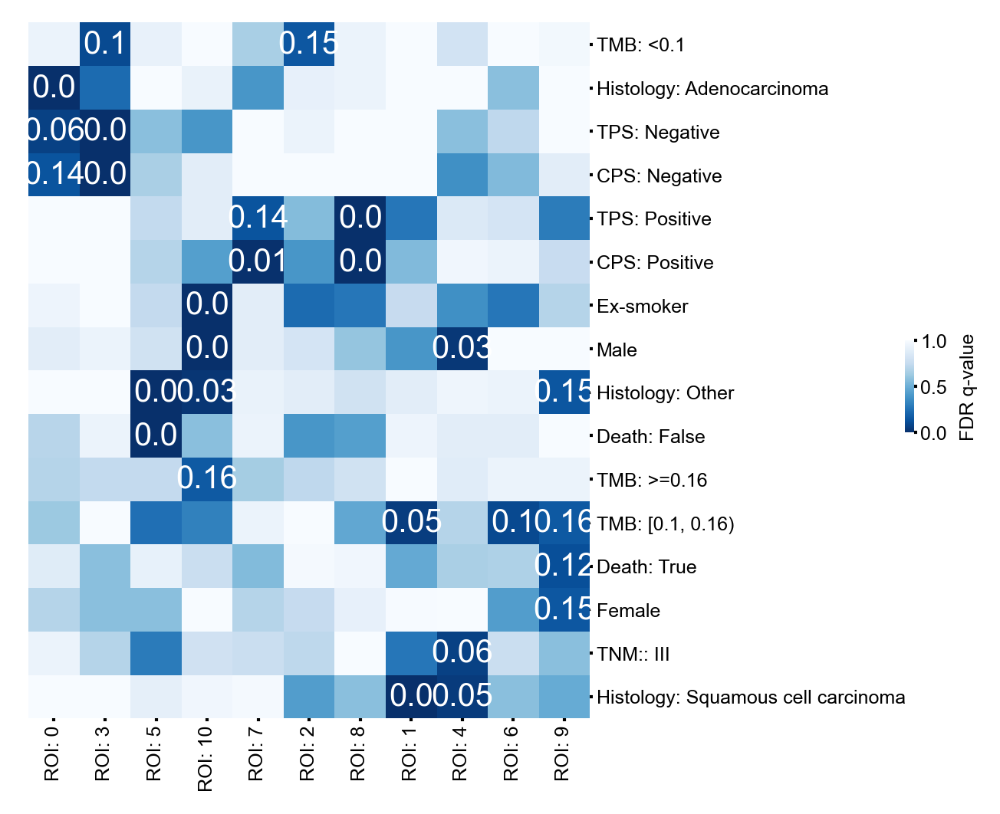

In [91]:
plt.figure(dpi=600)

clinical_cm = sns.clustermap(
    roi_qval_table.T[q_vals_sig_series], 
    cmap='Blues_r', 
    annot=sl_qvals_text.T[q_vals_sig_series], 
    yticklabels=sl_qvals_text.T[q_vals_sig_series].index,
    fmt='', 
    vmin=0,
    vmax=1.0,
    cbar_pos=[1.12, 0.35, 0.01, .1],
    cbar_kws={'label': 'FDR q-value'},
)
clinical_cm.ax_cbar.set_visible('False')
clinical_cm.ax_heatmap.xaxis.set_tick_params(rotation=0)

clinical_cm.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
clinical_cm.ax_row_dendrogram.set_visible(False)
clinical_cm.ax_col_dendrogram.set_visible(False)

clinical_cm.ax_heatmap.set_yticklabels(
    clinical_cm.ax_heatmap.get_yticklabels(), size=6
)
clinical_cm.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
clinical_cm.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
clinical_cm.ax_heatmap.set_xticklabels(
    clinical_cm.ax_heatmap.get_xticklabels(), size=6, rotation=90
)

clinical_cm.fig.set_dpi(PLOTTING_DPI)
clinical_cm.fig.set_size_inches((4, 4))

## Histology Narrowed Clinical Analysis

Analysis within histologies:

<Figure size 3600x2400 with 0 Axes>

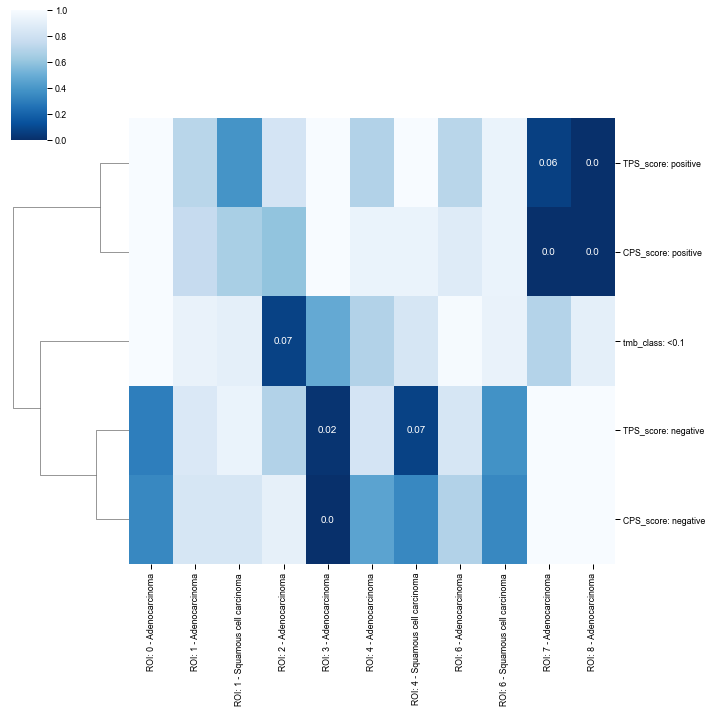

In [92]:
import matplotlib.pyplot as plt
from itertools import product


GROUP_SIZE_LIMIT = (roi_cluster_with_clinical['simple_stage'] == 4).sum()
CLINICAL_TYPES = tau.SIMPLE_HISTOLOGY_COLORS.keys()


dfs = []
indexes = []
for cluster, hist in product(GOOD_ROI_CLUSTERS, CLINICAL_TYPES):
    current_list = []
    hist_current_df = roi_cluster_with_clinical[roi_cluster_with_clinical['simple_histology'] == hist] 
    current_clusters = hist_current_df[cluster] > 0
    if sum(current_clusters) < GROUP_SIZE_LIMIT:
        continue
    for column in CLINICAL_DATA_COLS_FOR_ANALYSIS:
        if column == 'simple_histology':
            continue
        current_df = tau.compute_hypergeometrics_for_df(
                    df=hist_current_df,
                    clusters=current_clusters,
                    column=column,
                    values=None,
            )
        if current_df.shape[0] > 1:
            current_list.append(current_df.iloc[[1]])
    if len(current_list) > 0:
        dfs.append(pandas.concat(current_list, axis=1))
        indexes.append(f'{cluster} - {hist}')
    

p1_pl_sl_hist_p_val_table = pandas.concat(dfs)
p1_pl_sl_hist_p_val_table.fillna(1., inplace=True)


p1_pl_sl_hist_p_val_table.index = indexes

p1_pl_sl_hist_qvals = tau.apply_fdr_to_df(p1_pl_sl_hist_p_val_table)

fdr_alpha = 0.1

p1_pl_hist_q_vals_sig_series = p1_pl_sl_hist_qvals.min() < fdr_alpha

p1_pl_sl_hist_qvals_text = p1_pl_sl_hist_qvals.copy()
p1_pl_sl_hist_qvals_text = p1_pl_sl_hist_qvals_text.applymap(lambda x: str(round(x, 2)) if x < fdr_alpha else '')

plt.figure(dpi=600)

in_hist_clinical_cm = sns.clustermap(
    p1_pl_sl_hist_qvals.sort_index().T[p1_pl_hist_q_vals_sig_series], 
    cmap='Blues_r', 
    col_cluster=False,
    annot=p1_pl_sl_hist_qvals_text.sort_index().T[p1_pl_hist_q_vals_sig_series], 
    yticklabels=p1_pl_sl_hist_qvals_text.T[p1_pl_hist_q_vals_sig_series].index,
    fmt='', 
    vmin=0,
    vmax=1.0,
    #cbar=False,
    figsize=(10, 10),
)
#clinical_cm.ax_cbar.set_visible('False')

and within the whole dataset:

<Figure size 3600x2400 with 0 Axes>

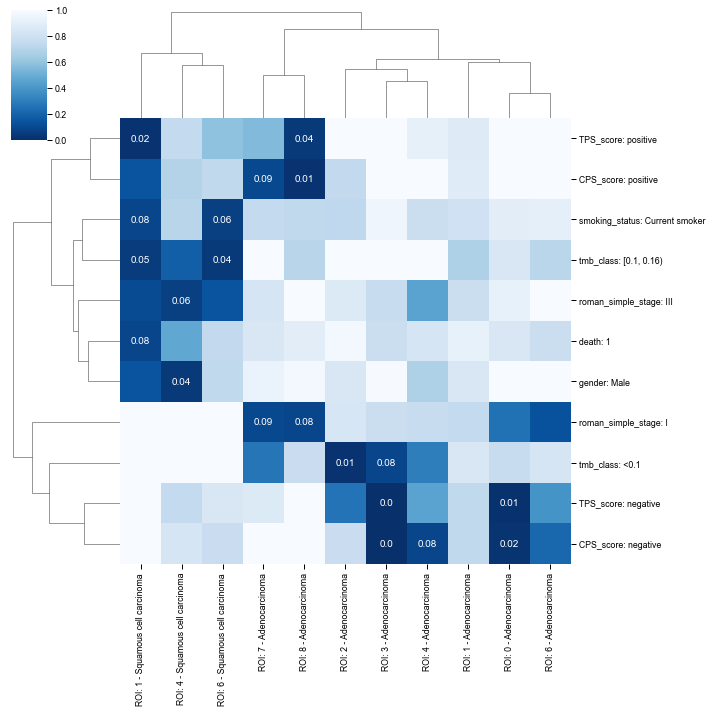

In [93]:
import matplotlib.pyplot as plt
from itertools import product


GROUP_SIZE_LIMIT = (roi_cluster_with_clinical['simple_stage'] == 4).sum()
CLINICAL_TYPES = tau.SIMPLE_HISTOLOGY_COLORS.keys()


dfs = []
indexes = []
for cluster, hist in product(GOOD_ROI_CLUSTERS, CLINICAL_TYPES):
    current_list = []
    current_clusters = (
        roi_cluster_with_clinical[cluster] > 0
    ) * (roi_cluster_with_clinical['simple_histology'] == hist)
    if sum(current_clusters) < GROUP_SIZE_LIMIT:
        continue
    for column in CLINICAL_DATA_COLS_FOR_ANALYSIS:
        if column == 'simple_histology':
            continue
        current_df = tau.compute_hypergeometrics_for_df(
                    df=roi_cluster_with_clinical,
                    clusters=current_clusters,
                    column=column,
                    values=None,
            )
        if current_df.shape[0] > 1:
            current_list.append(current_df.iloc[[1]])
    if len(current_list) > 0:
        dfs.append(pandas.concat(current_list, axis=1))
        indexes.append(f'{cluster} - {hist}')
    

p1_pl_sl_hist_p_val_table = pandas.concat(dfs)
p1_pl_sl_hist_p_val_table.fillna(1., inplace=True)


p1_pl_sl_hist_p_val_table.index = indexes

p1_pl_sl_hist_qvals = tau.apply_fdr_to_df(p1_pl_sl_hist_p_val_table)

fdr_alpha = 0.1

p1_pl_hist_q_vals_sig_series = p1_pl_sl_hist_qvals.min() < fdr_alpha

p1_pl_sl_hist_qvals_text = p1_pl_sl_hist_qvals.copy()
p1_pl_sl_hist_qvals_text = p1_pl_sl_hist_qvals_text.applymap(lambda x: str(round(x, 2)) if x < fdr_alpha else '')

plt.figure(dpi=600)

hist_clinical_cm = sns.clustermap(
    p1_pl_sl_hist_qvals.T[p1_pl_hist_q_vals_sig_series], 
    cmap='Blues_r', 
    annot=p1_pl_sl_hist_qvals_text.T[p1_pl_hist_q_vals_sig_series], 
    yticklabels=p1_pl_sl_hist_qvals_text.T[p1_pl_hist_q_vals_sig_series].index,
    fmt='', 
    vmin=0,
    vmax=1.0,
    #cbar=False,
    figsize=(10, 10),
)
#clinical_cm.ax_cbar.set_visible('False')

Now, let's prepare a colored version of the above table:

In [94]:
clinical_norm = matplotlib.colors.Normalize(vmin=0, vmax=1)
clinical_cmap = plt.get_cmap('Blues_r')

clinical_sm = matplotlib.cm.ScalarMappable(norm=clinical_norm, cmap=clinical_cmap)

clinical_colors = clinical_cm.data2d.applymap(lambda x: clinical_sm.to_rgba(x))

## Survival analysis:

Now, let's prepare a table for the Cox analysis. We will use the information about grades and clinical types, similarly to the original paper.

### CC Cluster analysis:

Now, let's prepare the main Cox table for the Cellohood cluster sqrt counts:

In [95]:
additional_feature_columns=('is_adeno', 'is_squamous',)# 'Gender_male', 'Smoking', 'Smoking-Non', 'Smoking-Ex')

STD_EPS = 2

jackson_survival_df_clusters = pandas.DataFrame(
    {
        **{
            'died': roi_counts[tau.DEATH_COLNAME],
            'survival': roi_counts[tau.SURVIVAL_COLNAME], 
            'simple_stage': roi_counts[tau.SIMPLE_STAGE_COLNAME],
        },
       **{
            col: roi_counts[col]
            for col in additional_feature_columns
        },
        **{
            f'simple_stage_{i}': (roi_counts[tau.SIMPLE_STAGE_COLNAME] == i).astype('int')
            for i in range(1, 4 + 1) if sum(roi_counts[tau.SIMPLE_STAGE_COLNAME] == i)
        },
        **{
            f'pl_{i}': roi_counts[i] ** 0.5 
            for i in range(CC_NB_OF_CLUSTERS)
            if (roi_counts[i] ** 0.5).std() > STD_EPS
        },
    }
)

Now, let's run the Cox model:

In [96]:
def rename_cox_summary_index(index_, prefix='SG', simple_stage_name='TNM'):
    new_index = []
    for el in index_:
        if el.startswith('pl'):
            new_index.append(f'{prefix}: {el.split("_")[-1]}')
            continue
        if el.startswith('simple_stage'):
            new_index.append(f'{simple_stage_name}: {el.split("_")[-1]}')
            continue
        if el == 'is_squamous':
            new_index.append('Squam.')
            continue
        if el == 'is_adeno':
            new_index.append('Adeno')
            continue
        new_index.append(el)
    return new_index
        

/tmp/ipykernel_121012/4228937197.py:29: UserWarning: FixedFormatter should only be used together with FixedLocator
  _ = cox_ax.set_xticklabels(cox_ax.get_xticklabels(), size=6)


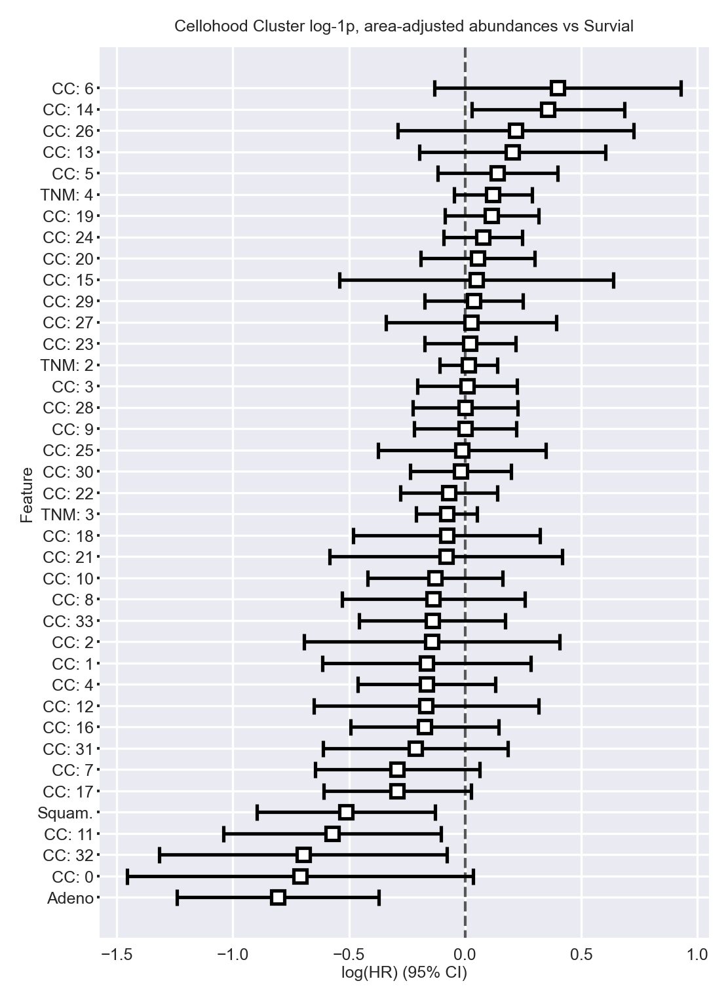

In [97]:
l2_true_value = 1e-3
l1_true_value = 0

coxphf_penalizer = l1_true_value + l2_true_value
coxphf_l1 = l1_true_value / (l1_true_value + l2_true_value)


jackson_cluster_cox = tau.surivial_on_df(
    jackson_survival_df_clusters, 
    l1_ratio=coxphf_l1,
    penalizer=coxphf_penalizer, 
    standardize=True,
    #cox_kwargs={'step_size': 0.1},
    fit_kwargs={
        'robust': True, 
        'strata': 'simple_stage_1', 
    }
)
plt.style.use('seaborn-v0_8-darkgrid')
plt.figure(figsize=(4, 6), dpi=300)
jackson_cluster_cox.plot()
plt.title('Cellohood Cluster log-1p, area-adjusted abundances vs Survial', size=6)
cox_ax = plt.gca()
yticklabels = [el.get_text() for el in cox_ax.get_yticklabels()]
_ = cox_ax.set_yticklabels(rename_cox_summary_index(yticklabels, prefix='CC'), size=6)
plt.ylabel('Feature', labelpad=1, fontdict={'size': 6})
plt.xlabel('log(HR) (95% CI)', labelpad=1, fontdict={'size': 6})
cox_ax.yaxis.set_tick_params(pad=1, size=1)
_ = cox_ax.set_xticklabels(cox_ax.get_xticklabels(), size=6)

### ROI Cluster Analysis

In [98]:
survival_df = pandas.DataFrame(
       {
            **{
                'died': roi_cluster_with_clinical[tau.DEATH_COLNAME],
                'survival': roi_cluster_with_clinical[tau.SURVIVAL_COLNAME], 
                'simple_stage': roi_cluster_with_clinical[tau.SIMPLE_STAGE_COLNAME],
            },
           **{
               col: roi_cluster_with_clinical[col]
               for col in additional_feature_columns
           },
            **{
                f'simple_stage_{i}': roi_cluster_with_clinical[tau.SIMPLE_STAGE_COLNAME] == i
                for i in range(1, 4 + 1) if sum(roi_cluster_with_clinical[tau.SIMPLE_STAGE_COLNAME] == i)
            },
            **{
                f'pl_{ROI_CLUSTERS}_{int(i)}': roi_cluster_with_clinical[f'ROI: {i}']
                for i in GOOD_ROI_CLUSTERS_INDS
            },
        }
    )

In [99]:
def get_cox_feature_colors(
    feature,
    cluster_prefix='ROI: '
):
    if feature.startswith(cluster_prefix):
        cluster_ind = int(feature.split(cluster_prefix)[-1])
        return cluster_sm.to_rgba(cluster_ind)
    if feature.startswith('HR'):
        return clinical_type_color[feature]
    if feature.startswith('Grade'):
        grade_int = int(feature[-1])
        return grade_color[grade_int]

/tmp/ipykernel_121012/873622742.py:17: UserWarning: FixedFormatter should only be used together with FixedLocator
  _ = ax.set_xticklabels(ax.get_xticklabels(), size=6)


Text(0.5, 1.0, 'Cox PH Model\nfor Slide Groups')

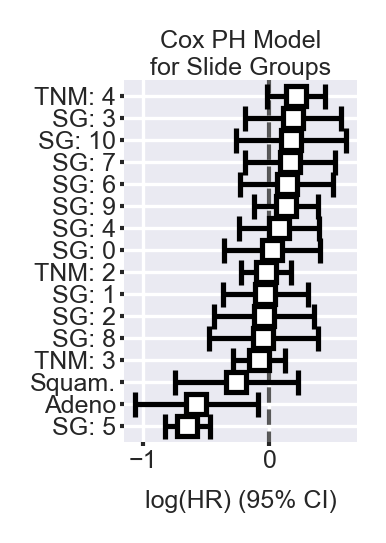

In [100]:
jackson_cox = tau.surivial_on_df(
    survival_df,
    l1_ratio=coxphf_l1,
    penalizer=coxphf_penalizer,
    fit_kwargs={'robust': True, 'strata': 'simple_stage_1'},
)

plt.style.use('seaborn-v0_8-darkgrid')
plt.figure(figsize=(1., 1.6), dpi=300)
ax = jackson_cox.plot()
yticklabels = [el.get_text() for el in ax.get_yticklabels()]
new_labels = rename_cox_summary_index(yticklabels)
_ = ax.set_yticklabels(new_labels, size=6)
#for ticklabel, tickcolor in zip(ax.get_yticklabels(), labels_colors):
#    ticklabel.set_color(tickcolor)
ax.yaxis.set_tick_params(pad=1, size=1)
_ = ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.xaxis.set_tick_params(pad=1, size=1)
#ax.set_ylabel('Feature')
ax.set_title('Cox PH Model\nfor Slide Groups', fontsize=6, pad=1)
#ax.get_children()[0].set_color('blue')

In [101]:
DATA_COX_COLS = ['died', 'survival', 'simple_stage', 'is_adeno', 'simple_stage_1',
       'simple_stage_2', 'simple_stage_3', 'simple_stage_4']


for roi in GOOD_ROI_CLUSTERS_INDS:
    current_cluster_colname = f'pl_{ROI_CLUSTERS}_{int(roi)}'
    current_cox_cols = DATA_COX_COLS + [current_cluster_colname]
    current_cox = tau.surivial_on_df(
        survival_df[current_cox_cols], 
        l1_ratio=coxphf_l1, 
        penalizer=coxphf_penalizer,
        fit_kwargs={'robust': False, 'strata': 'simple_stage_1'},
    )
    if current_cox.summary.loc[current_cluster_colname]['coef lower 95%'] * current_cox.summary.loc[current_cluster_colname]['coef upper 95%'] > 0:
        plt.figure(figsize=(10, 10))
        current_cox.plot()
        plt.title(roi)

In [102]:
hg_survival_df = pandas.DataFrame(
       {
            **{
                'died': roi_cluster_with_clinical[tau.DEATH_COLNAME],
                'survival': roi_cluster_with_clinical[tau.SURVIVAL_COLNAME], 
                'simple_stage': roi_cluster_with_clinical[tau.SIMPLE_STAGE_COLNAME],
            },
           **{
               col: roi_cluster_with_clinical[col]
               for col in additional_feature_columns
           },
            **{
                f'simple_stage_{i}': roi_cluster_with_clinical[tau.SIMPLE_STAGE_COLNAME] == i
                for i in range(1, 4 + 1) if sum(roi_cluster_with_clinical[tau.SIMPLE_STAGE_COLNAME] == i)
            },
           **{
               f'HG: {i}': (roi_cluster_with_clinical[ROI_CLUSTER_NAMES].sum(axis=1) == i).astype(int)
               for i in range(1, 3 + 1)
           }
        }
    )

/tmp/ipykernel_121012/3531850059.py:17: UserWarning: FixedFormatter should only be used together with FixedLocator
  _ = ax.set_xticklabels(ax.get_xticklabels(), size=6)


Text(0.5, 1.0, 'Cox PH Model\nfor Tumor heterogeneity')

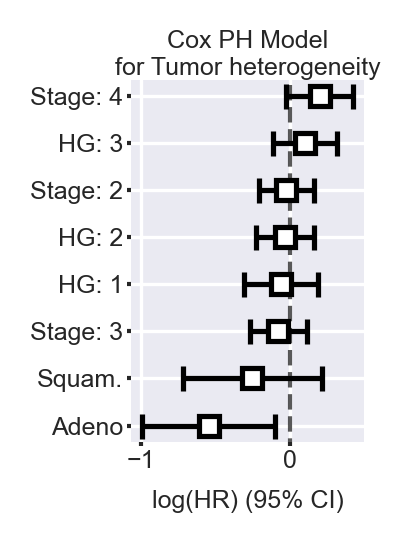

In [103]:
hg_jackson_cox = tau.surivial_on_df(
    hg_survival_df,
    l1_ratio=coxphf_l1,
    penalizer=coxphf_penalizer,
    fit_kwargs={'robust': True, 'strata': 'simple_stage_1'},
)

plt.style.use('seaborn-v0_8-darkgrid')
plt.figure(figsize=(1., 1.6), dpi=300)
ax = hg_jackson_cox.plot()
yticklabels = [el.get_text() for el in ax.get_yticklabels()]
new_labels = rename_cox_summary_index(yticklabels, simple_stage_name='Stage')
_ = ax.set_yticklabels(new_labels, size=6)
#for ticklabel, tickcolor in zip(ax.get_yticklabels(), labels_colors):
#    ticklabel.set_color(tickcolor)
ax.yaxis.set_tick_params(pad=1, size=1)
_ = ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.xaxis.set_tick_params(pad=1, size=1)
#ax.set_ylabel('Feature')
ax.set_title('Cox PH Model\nfor Tumor heterogeneity', fontsize=6, pad=1)
#ax.get_children()[0].set_color('blue')

In [104]:
DATA_COX_COLS = ['died', 'survival', 'simple_stage', 'is_adeno', 'simple_stage_1',
       'simple_stage_2', 'simple_stage_3', 'simple_stage_4']


for roi in range(1, 4):
    current_cluster_colname = f'HG: {int(roi)}'
    current_cox_cols = DATA_COX_COLS + [current_cluster_colname]
    current_cox = tau.surivial_on_df(
        hg_survival_df[current_cox_cols], 
        l1_ratio=coxphf_l1, 
        penalizer=coxphf_penalizer,
        fit_kwargs={'robust': False, 'strata': 'simple_stage_1'},
    )
    if current_cox.summary.loc[current_cluster_colname]['coef lower 95%'] * current_cox.summary.loc[current_cluster_colname]['coef upper 95%'] > 0:
        plt.figure(figsize=(10, 10))
        current_cox.plot()
        plt.title(roi)

## Kaplan-Meier Curves:

### Cross-ROI clusters analysis

In [105]:
cluster_log_rank_p_values = numpy.ones((len(GOOD_ROI_CLUSTERS), 1))


for l_ind, l_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
        l_current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] == l_ind]
        r_current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] != l_ind]
        l_N = l_current_df.shape[0]
#         if l_N < 15:
#             print(l_N)
#             continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        cluster_log_rank_p_values[l_ind, 0] = current_test.p_value
        if cluster_log_rank_p_values[l_ind, 0] < 0.01:
            plt.figure(figsize=(2, 2), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f' {l_roi_cc}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'!{l_roi_cc}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(f'{l_roi_cc} N = {l_current_df.shape[0]}\n(log-rank p = {round(cluster_log_rank_p_values[l_ind, 0], 3)})', size=6)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=1)
            plt.show()

In [106]:
cluster_log_rank_p_values_df = pandas.DataFrame(
    cluster_log_rank_p_values,
    index=GOOD_ROI_CLUSTERS,
)

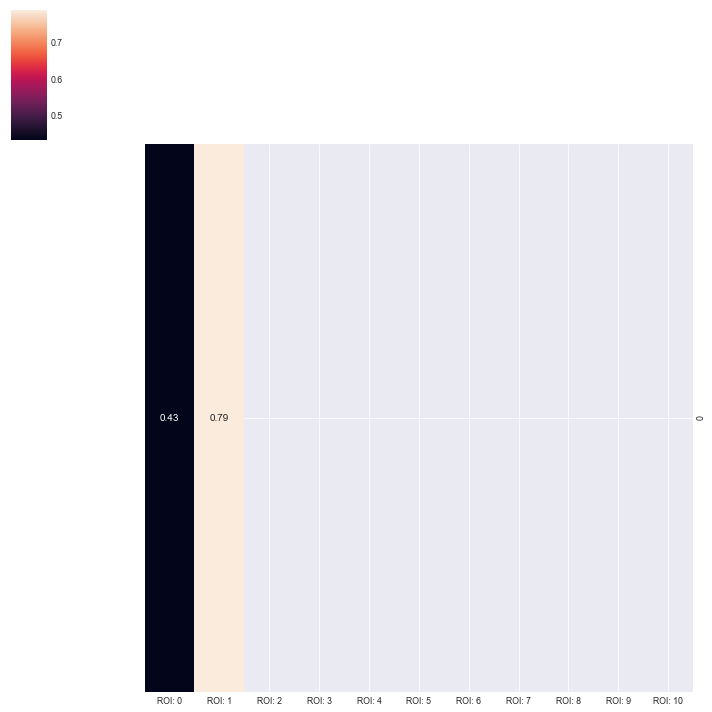

In [107]:
# NOTE: added col_cluster=False -- this p-value matrix can contain NaN (e.g. groups too small for a valid log-rank test), and scipy's dendrogram linkage can't handle NaN; row_cluster was already disabled, disabling column clustering too rather than dropping/imputing real NaN values.
sns.clustermap(cluster_log_rank_p_values_df.T, row_cluster=False, col_cluster=False, annot=True)

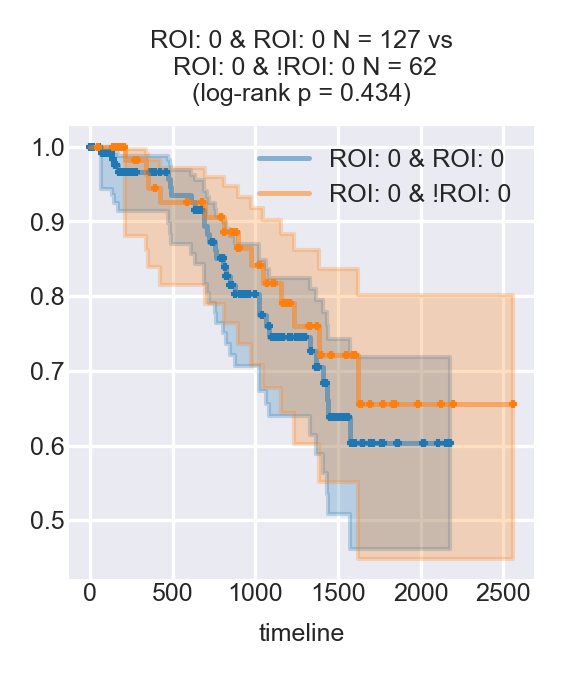

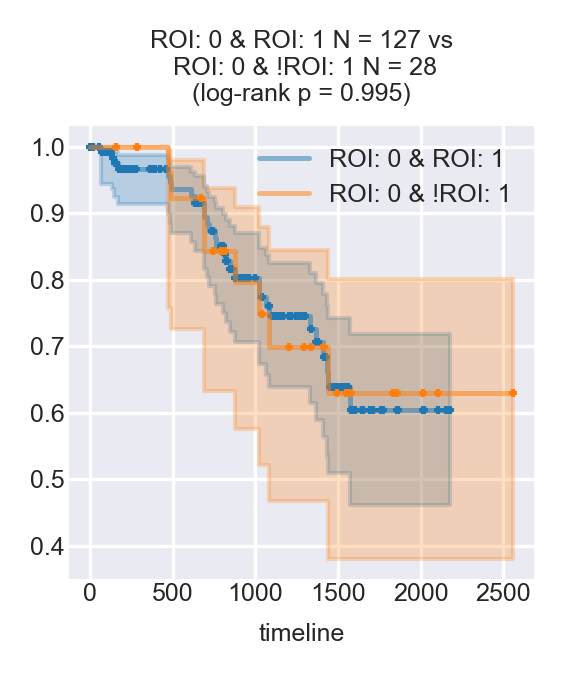

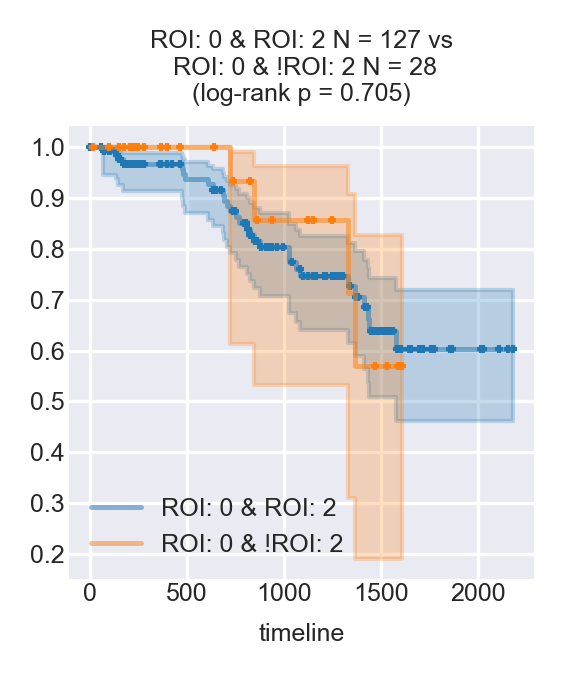

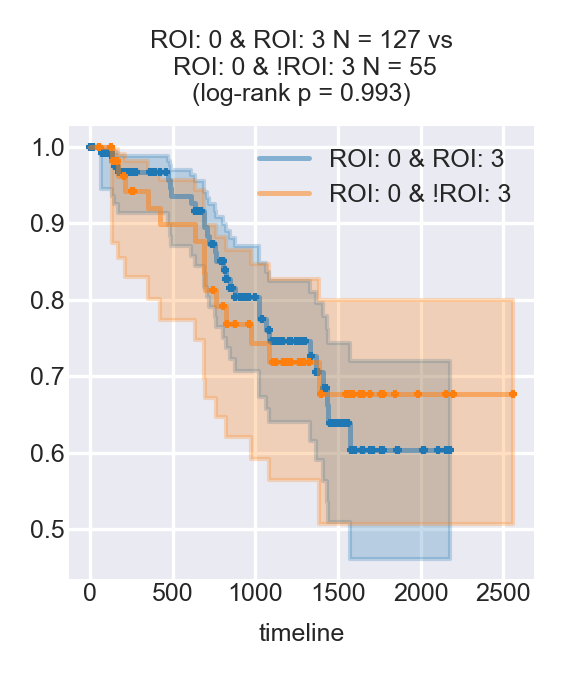

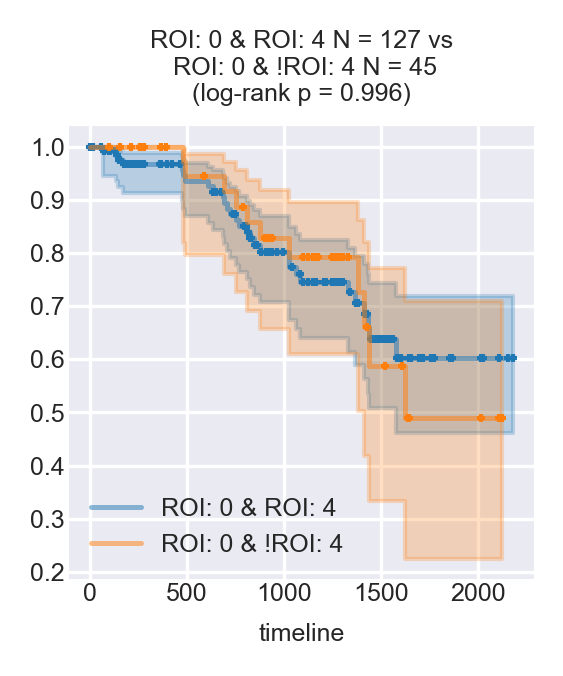

...

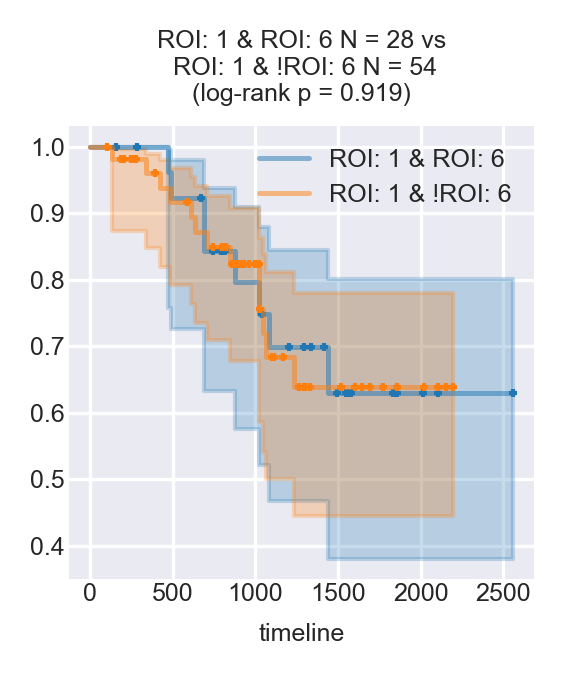

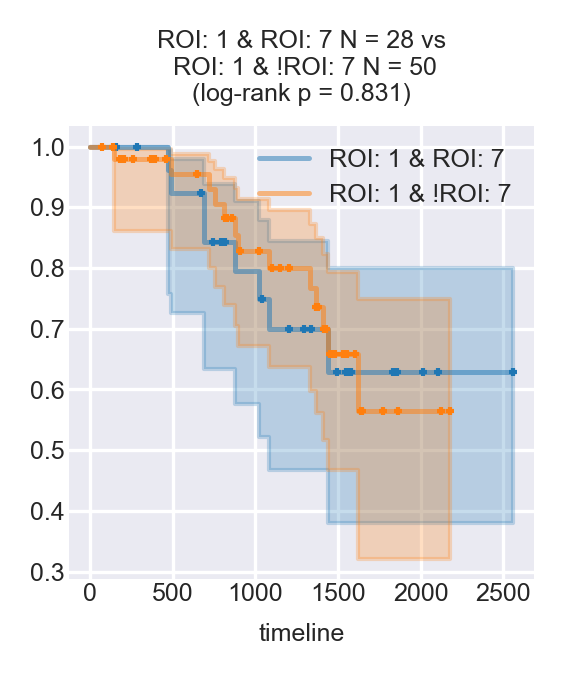

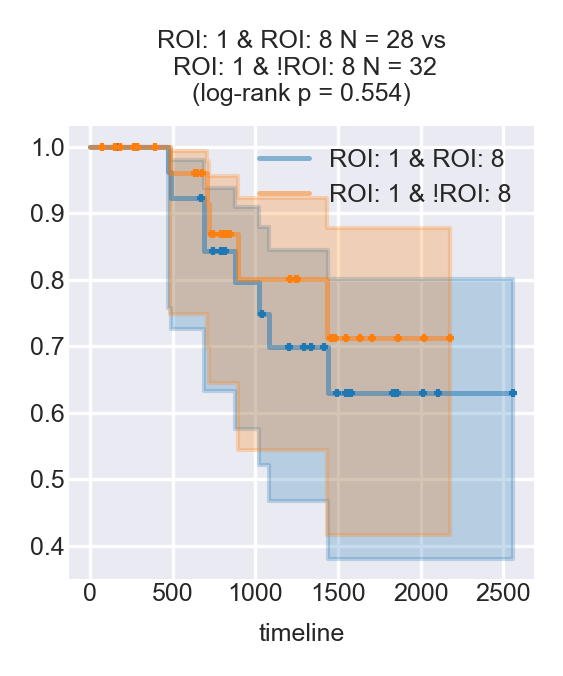

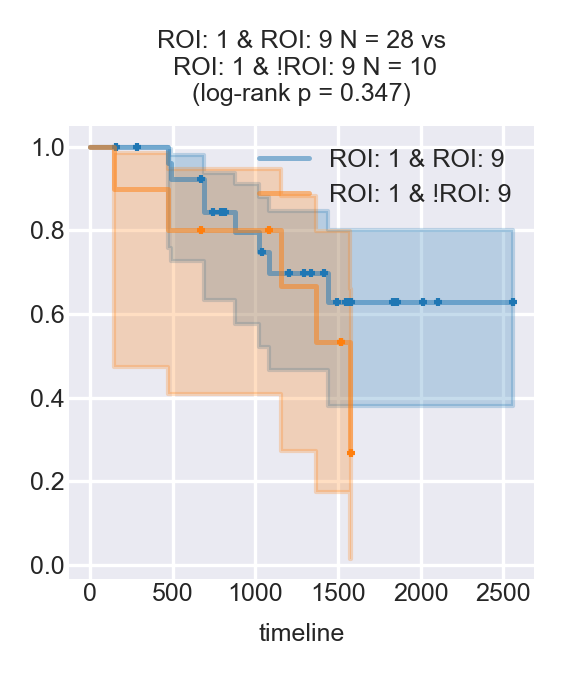

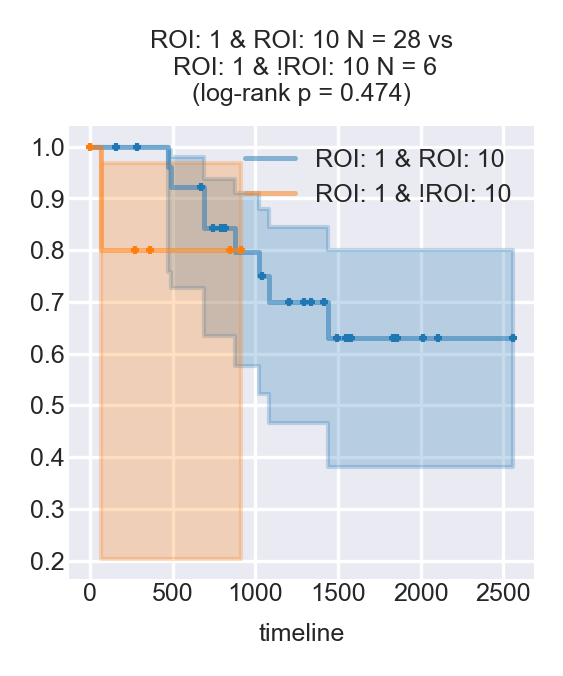

In [108]:
cross_cluster_log_rank_p_values = numpy.ones((len(GOOD_ROI_CLUSTERS), len(GOOD_ROI_CLUSTERS)))


for l_ind, l_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
    for r_ind, r_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
        l_current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] == l_ind]
        r_current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[r_roi_cc] == 1]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        #if l_N < 15 or r_N < 15:
        #    continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        cross_cluster_log_rank_p_values[l_ind, r_ind] = current_test.p_value
        if cross_cluster_log_rank_p_values[l_ind, r_ind] < 5:
            plt.figure(figsize=(2, 2), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & {r_roi_cc}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & !{r_roi_cc}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(f'{l_roi_cc} & {r_roi_cc} N = {l_current_df.shape[0]} vs\n {l_roi_cc} & !{r_roi_cc} N = {r_current_df.shape[0]}\n(log-rank p = {round(cross_cluster_log_rank_p_values[l_ind, r_ind], 3)})', size=6)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=1)
            plt.show()

In [109]:
cross_cluster_log_rank_p_values_df = pandas.DataFrame(
    cross_cluster_log_rank_p_values,
    index=GOOD_ROI_CLUSTERS,
    columns=GOOD_ROI_CLUSTERS,
)
cross_cluster_log_rank_p_values_df.index.name = f'{ROI_COLUMN} Clusters'
cross_cluster_log_rank_p_values_df.columns.name = f'{ROI_COLUMN} Clusters'

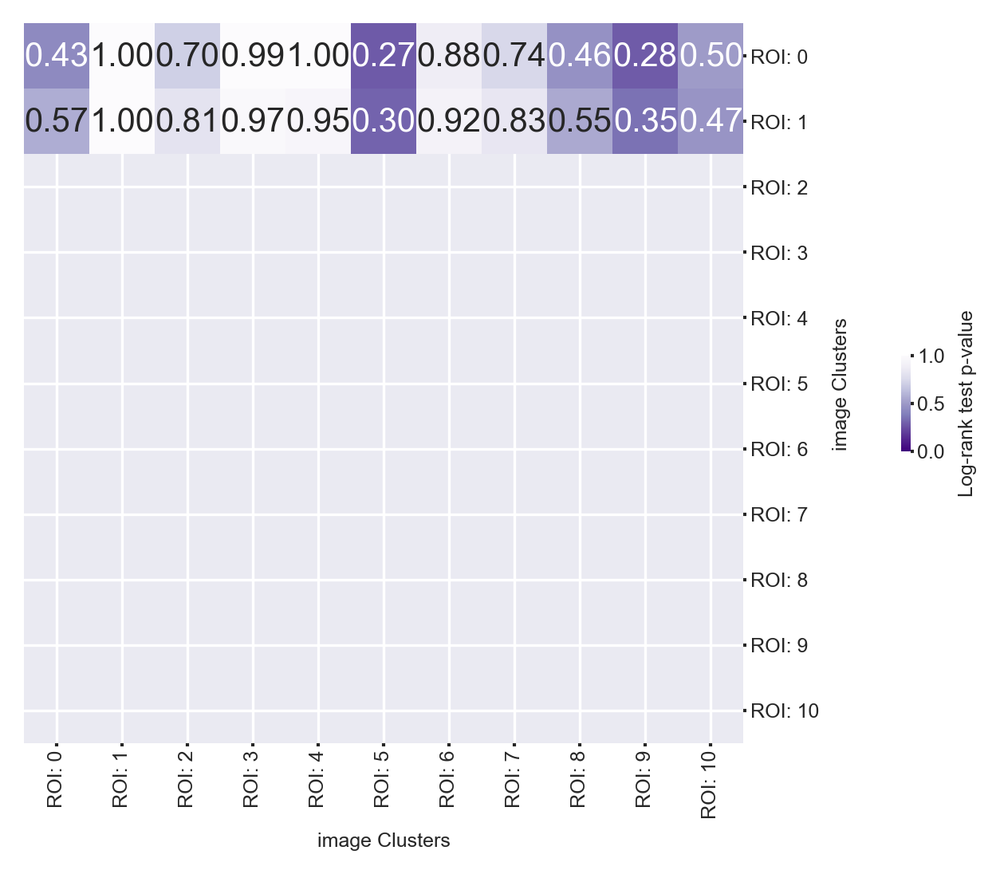

In [110]:
# NOTE: added row_cluster=False, col_cluster=False -- same NaN/dendrogram issue as
# the cluster_log_rank_p_values_df clustermap above.
cross_cluster_log_rank_cmap = sns.clustermap(
    cross_cluster_log_rank_p_values_df,
    row_cluster=False,
    col_cluster=False,
    cmap='Purples_r',
    annot=True,
    fmt='.2f',
    vmin=0,
    vmax=1.0,
    cbar_pos=[1.12, 0.35, 0.01, .1],
    cbar_kws={'label': 'Log-rank test p-value'},
)

cross_cluster_log_rank_cmap.ax_cbar.set_visible('False')
cross_cluster_log_rank_cmap.ax_heatmap.xaxis.set_tick_params(rotation=0)

cross_cluster_log_rank_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
cross_cluster_log_rank_cmap.ax_row_dendrogram.set_visible(False)
cross_cluster_log_rank_cmap.ax_col_dendrogram.set_visible(False)

cross_cluster_log_rank_cmap.ax_heatmap.set_yticklabels(
    cross_cluster_log_rank_cmap.ax_heatmap.get_yticklabels(), size=6
)
cross_cluster_log_rank_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
cross_cluster_log_rank_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
cross_cluster_log_rank_cmap.ax_heatmap.set_xticklabels(
    cross_cluster_log_rank_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90
)

cross_cluster_log_rank_cmap.fig.set_dpi(PLOTTING_DPI)
cross_cluster_log_rank_cmap.fig.set_size_inches((4, 4))

### Clinical Type vs ROI analysis

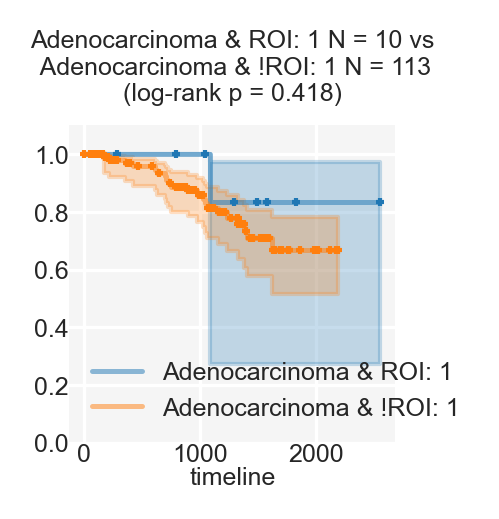

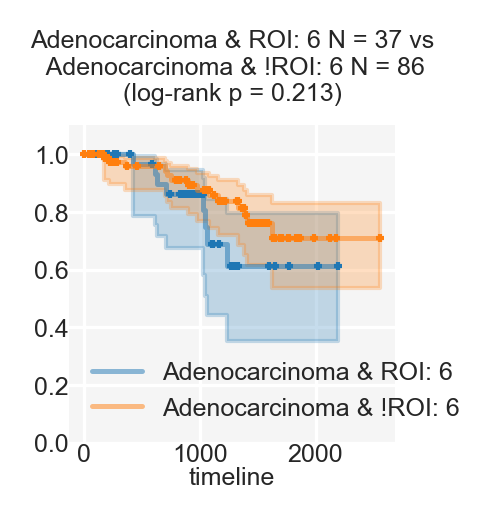

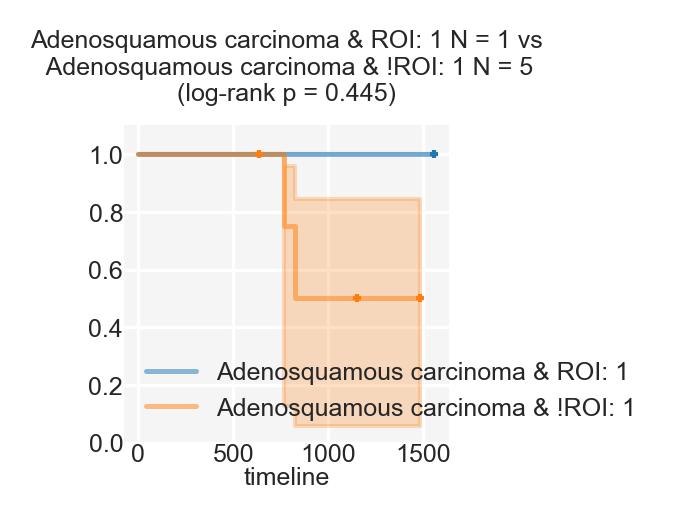

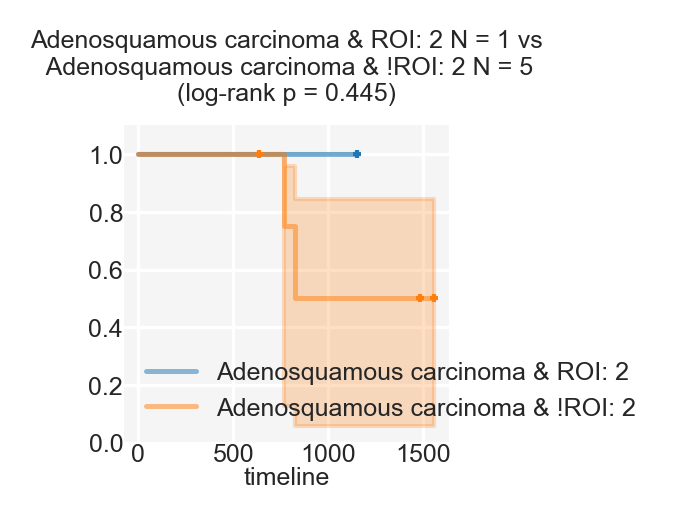

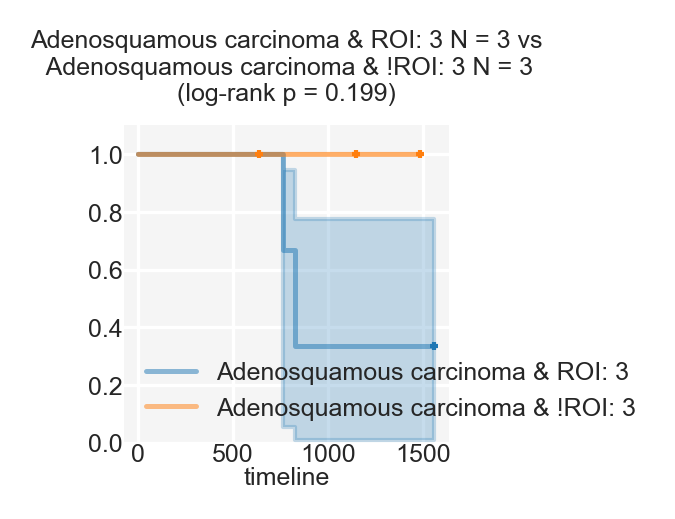

...

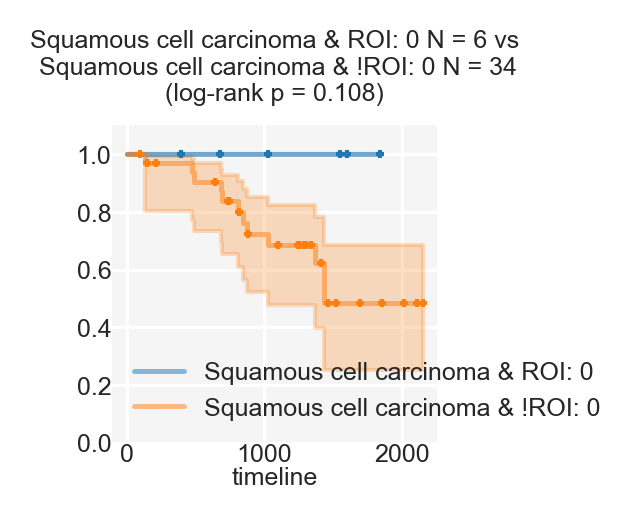

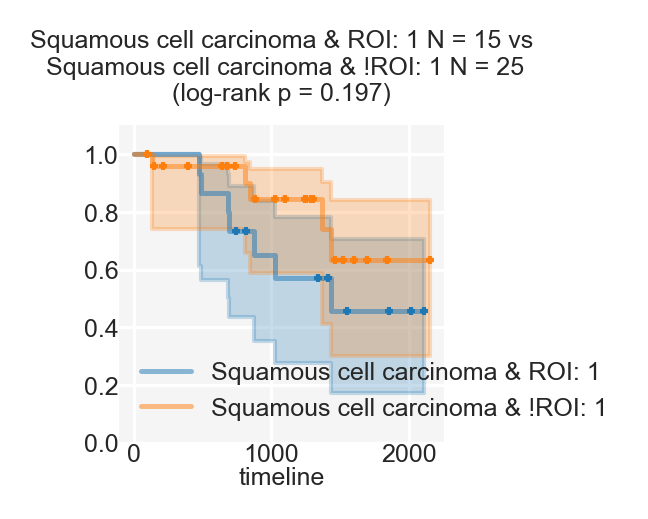

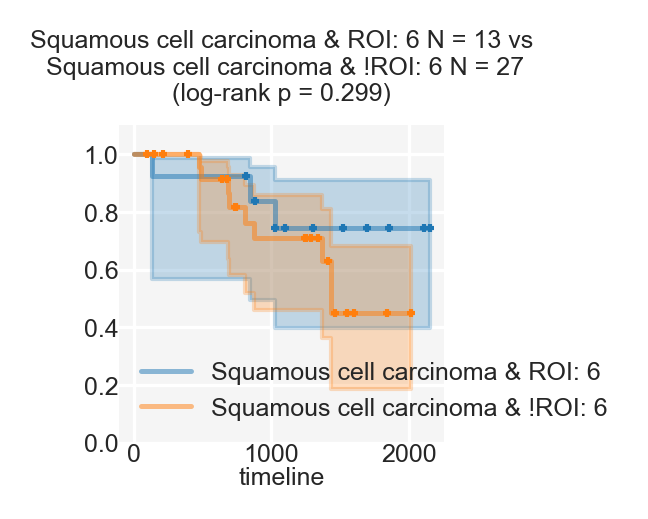

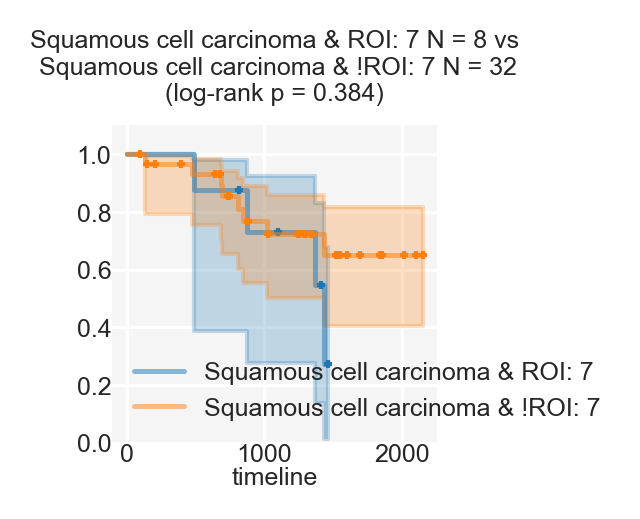

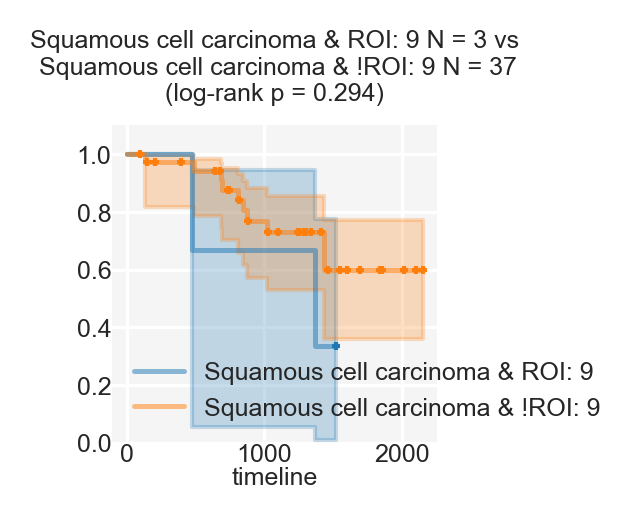

In [111]:
CLINICAL_TYPES = tau.SIMPLE_HISTOLOGY_COLORS.keys()


cluster_vs_ct_log_rank_pvalues = numpy.ones((len(CLINICAL_TYPES), len(GOOD_ROI_CLUSTERS)))


for l_ind, l_roi_cc in enumerate(CLINICAL_TYPES):
    current_df = roi_cluster_with_clinical[roi_cluster_with_clinical['simple_histology'] == l_roi_cc]
    for r_ind, r_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
        l_current_df = current_df[current_df[r_roi_cc] == 1]
        r_current_df = current_df[current_df[r_roi_cc] != 1]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        #if l_N < 15 or r_N < 15:
        #    continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        if numpy.isnan(current_test.p_value):
            continue
        cluster_vs_ct_log_rank_pvalues[l_ind, r_ind] = current_test.p_value
        if cluster_vs_ct_log_rank_pvalues[l_ind, r_ind] < 0.5:
            plt.figure(figsize=(1.4, 1.4), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & {r_roi_cc}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & !{r_roi_cc}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(f'{l_roi_cc} & {r_roi_cc} N = {l_N} vs\n {l_roi_cc} & !{r_roi_cc} N = {r_N}\n(log-rank p = {round(cluster_vs_ct_log_rank_pvalues[l_ind, r_ind], 3)})', size=6)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=0.1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=0.1)
            ax.set_xlabel('timeline', labelpad=0)
            ax.grid(zorder=0)
            plt.ylim([0, 1.1])
            ax.spines[['left', 'right', 'top', 'bottom']].set_visible(False)
            ax.set_axisbelow(True)
            ax.set_facecolor('whitesmoke')
            ax.grid(color='white', gapcolor='gray')
            plt.show()

In [112]:
cluster_vs_ct_log_rank_pvalues_df = pandas.DataFrame(
    cluster_vs_ct_log_rank_pvalues,
    columns=GOOD_ROI_CLUSTERS,
    index=CLINICAL_TYPES,
)
cluster_vs_ct_log_rank_pvalues_df.columns.name = f'{ROI_COLUMN} Clusters'
cluster_vs_ct_log_rank_pvalues_df.index.name = f'Clinical Type'

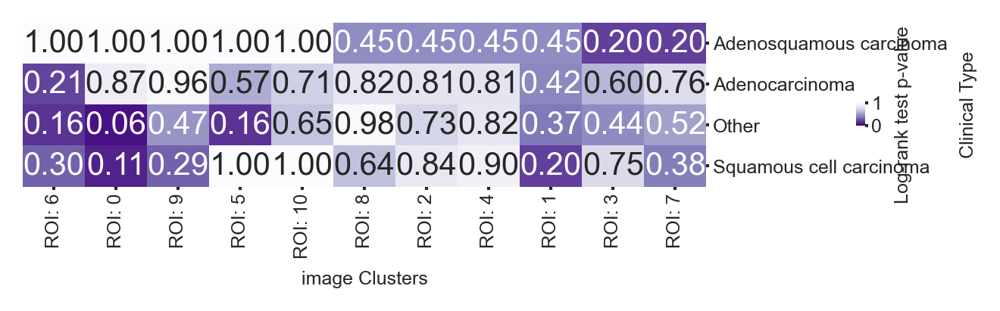

In [113]:
cluster_vs_ct_log_rank_cmap = sns.clustermap(
    cluster_vs_ct_log_rank_pvalues_df,
    cmap='Purples_r',
    annot=True,
    fmt='.2f',
    vmin=0,
    vmax=1.0,
    cbar_pos=[1.12, 0.35, 0.01, .1],
    cbar_kws={'label': 'Log-rank test p-value'},
)

cluster_vs_ct_log_rank_cmap.ax_cbar.set_visible('False')
cluster_vs_ct_log_rank_cmap.ax_heatmap.xaxis.set_tick_params(rotation=0)

cluster_vs_ct_log_rank_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
cluster_vs_ct_log_rank_cmap.ax_row_dendrogram.set_visible(False)
cluster_vs_ct_log_rank_cmap.ax_col_dendrogram.set_visible(False)

cluster_vs_ct_log_rank_cmap.ax_heatmap.set_yticklabels(
    cluster_vs_ct_log_rank_cmap.ax_heatmap.get_yticklabels(), size=6
)
cluster_vs_ct_log_rank_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
cluster_vs_ct_log_rank_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
cluster_vs_ct_log_rank_cmap.ax_heatmap.set_xticklabels(
    cluster_vs_ct_log_rank_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90
)

cluster_vs_ct_log_rank_cmap.fig.set_dpi(PLOTTING_DPI)
cluster_vs_ct_log_rank_cmap.fig.set_size_inches((4, 1))

### Clinical type vs ROI

/tmp/ipykernel_121012/2577734267.py:42: MatplotlibDeprecationWarning: The legendHandles attribute was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use legend_handles instead.
  handles = leg.legendHandles


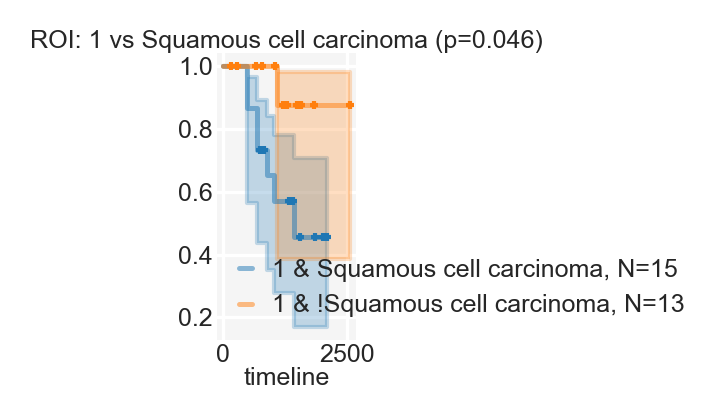

In [114]:
ct_vs_cluster_log_rank_pvalues = numpy.ones((len(GOOD_ROI_CLUSTERS), len(CLINICAL_TYPES)))


for l_ind, l_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
    current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] == 1]
    for r_ind, r_roi_cc in enumerate(CLINICAL_TYPES):
        l_current_df = current_df[current_df['simple_histology'] == r_roi_cc]
        r_current_df = current_df[current_df['simple_histology'] != r_roi_cc]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 10 or r_N < 10:
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        if numpy.isnan(current_test.p_value):
            continue
        ct_vs_cluster_log_rank_pvalues[l_ind, r_ind] = current_test.p_value
        if ct_vs_cluster_log_rank_pvalues[l_ind, r_ind] < 0.05:
            plt.figure(figsize=(1.4, 1.5), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc.replace("ROI: ", "")} & {r_roi_cc}, N={l_N}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc.replace("ROI: ", "")} & !{r_roi_cc}, N={r_N}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(
                f'{l_roi_cc} vs {r_roi_cc} (p={round(ct_vs_cluster_log_rank_pvalues[l_ind, r_ind], 3)})',
                size=6, pad=0)
            ax.set_xlabel('timeline', labelpad=0)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.spines[['left', 'right', 'top', 'bottom']].set_visible(False)
            ax.set_axisbelow(True)
            ax.set_facecolor('whitesmoke')
            leg = plt.gca().get_legend()

            # Get the current legend properties
            labels = [text.get_text() for text in leg.get_texts()]
            handles = leg.legendHandles

# Remove old legend
            leg.remove()

# Create new legend with desired handle length
            plt.legend(handles, labels, handlelength=.5)
            ax.get_legend().handlelength = 0.1
#             for legend_line in ax.get_legend().get_lines():
#                 legend_line.set_xdata(legend_line.get_xdata() / 3.)
#             for t in ax.get_legend().get_texts():
#                 text_width = t.get_window_extent().width
#                 t.set_ha('right')
            ax.grid(color='white', gapcolor='gray')
            plt.tight_layout()
            plt.show()

In [115]:
ct_vs_cluster_log_rank_pvalues_df = pandas.DataFrame(
    ct_vs_cluster_log_rank_pvalues,
    index=GOOD_ROI_CLUSTERS,
    columns=CLINICAL_TYPES,
)
ct_vs_cluster_log_rank_pvalues_df.index.name = f'{ROI_COLUMN} Clusters'
ct_vs_cluster_log_rank_pvalues_df.columns.name = f'Clinical Type'

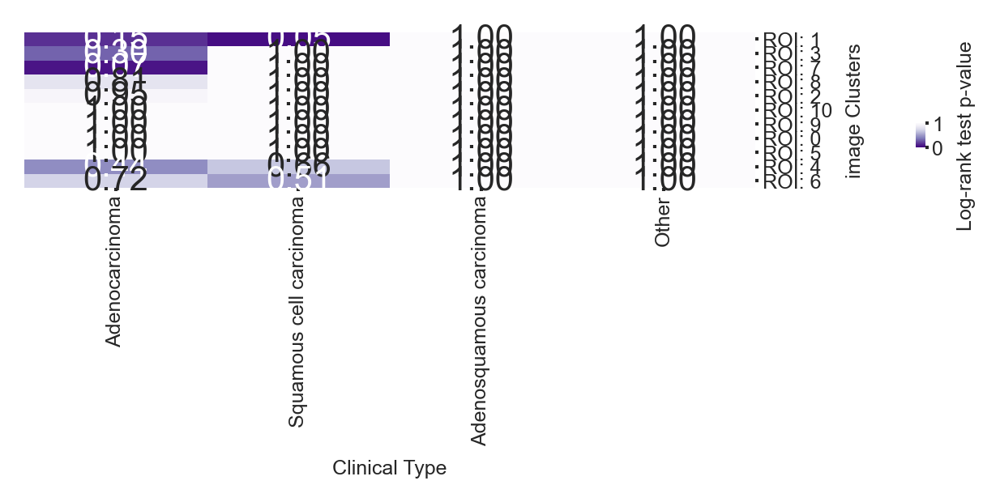

In [116]:
ct_vs_clusterlog_rank_cmap = sns.clustermap(
    ct_vs_cluster_log_rank_pvalues_df,
    cmap='Purples_r',
    annot=True,
    fmt='.2f',
    vmin=0,
    vmax=1.0,
    cbar_pos=[1.12, 0.35, 0.01, .1],
    cbar_kws={'label': 'Log-rank test p-value'},
)

ct_vs_clusterlog_rank_cmap.ax_cbar.set_visible('False')
ct_vs_clusterlog_rank_cmap.ax_heatmap.xaxis.set_tick_params(rotation=0)

ct_vs_clusterlog_rank_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
ct_vs_clusterlog_rank_cmap.ax_row_dendrogram.set_visible(False)
ct_vs_clusterlog_rank_cmap.ax_col_dendrogram.set_visible(False)

ct_vs_clusterlog_rank_cmap.ax_heatmap.set_yticklabels(
    ct_vs_clusterlog_rank_cmap.ax_heatmap.get_yticklabels(), size=6
)
ct_vs_clusterlog_rank_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
ct_vs_clusterlog_rank_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
ct_vs_clusterlog_rank_cmap.ax_heatmap.set_xticklabels(
    ct_vs_clusterlog_rank_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90
)

ct_vs_clusterlog_rank_cmap.fig.set_dpi(PLOTTING_DPI)
ct_vs_clusterlog_rank_cmap.fig.set_size_inches((4, 1))

## Grade vs ROI

In [117]:
GRADES = [1, 2, 3, 4]

grade_vs_cluster_log_rank_pvalues = numpy.ones((len(GOOD_ROI_CLUSTERS), len(GRADES)))


for l_ind, l_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
    current_df = roi_cluster_with_clinical[roi_cluster_with_clinical[l_roi_cc] == 1]
    for r_ind, r_roi_cc in enumerate(GRADES):
        l_current_df = current_df[current_df['simple_stage'] == r_roi_cc]
        r_current_df = current_df[current_df['simple_stage'] != r_roi_cc]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 10 or r_N < 10:
            print(l_roi_cc, r_roi_cc, l_N, r_N)
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        if numpy.isnan(current_test.p_value):
            continue
        grade_vs_cluster_log_rank_pvalues[l_ind, r_ind] = current_test.p_value
        if grade_vs_cluster_log_rank_pvalues[l_ind, r_ind] < 0.05:
            plt.figure(figsize=(2, 2), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & {r_roi_cc}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'{l_roi_cc} & !{r_roi_cc}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(f'{l_roi_cc} & {r_roi_cc} N = {l_N} vs\n {l_roi_cc} & !{r_roi_cc} N = {r_N}\n(log-rank p = {round(grade_vs_cluster_log_rank_pvalues[l_ind, r_ind], 3)})', size=6)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=1)
            plt.show()

ROI: 0 4 5 57
ROI: 1 1 4 24
ROI: 1 4 2 26
ROI: 2 1 7 21
ROI: 2 3 7 21
ROI: 2 4 2 26


ROI: 3 4 2 53
ROI: 4 4 0 45
ROI: 5 1 2 2
ROI: 5 2 0 4
ROI: 5 3 2 2
ROI: 5 4 0 4
ROI: 6 4 3 51
ROI: 7 4 2 48


ROI: 8 2 9 23
ROI: 8 3 5 27
ROI: 8 4 1 31
ROI: 9 1 3 7
ROI: 9 2 3 7
ROI: 9 3 3 7
ROI: 9 4 1 9
ROI: 10 1 4 2
ROI: 10 2 1 5
ROI: 10 3 1 5
ROI: 10 4 0 6


In [118]:
GRADES = [1, 2, 3, 4]

grade_vs_cluster_log_rank_pvalues = numpy.ones((len(GRADES), len(GOOD_ROI_CLUSTERS)))

xticks_font = matplotlib.font_manager.FontProperties(family='Arial')


for l_ind, l_roi_cc in enumerate(GRADES):
    current_df = roi_cluster_with_clinical[roi_cluster_with_clinical['simple_stage'] == l_roi_cc]
    for r_ind, r_roi_cc in enumerate(GOOD_ROI_CLUSTERS):
        l_current_df = current_df[current_df[r_roi_cc] == 1]
        r_current_df = current_df[current_df[r_roi_cc] != 1]
        l_N = l_current_df.shape[0]
        r_N = r_current_df.shape[0]
        if l_N < 10 or r_N < 10:
            print(l_roi_cc, r_roi_cc)
            continue
        current_test = lifelines.statistics.logrank_test(
            l_current_df['days_to_death'], r_current_df['days_to_death'],
            l_current_df['death'], r_current_df['death'],
        )
        if numpy.isnan(current_test.p_value):
            continue
        grade_vs_cluster_log_rank_pvalues[l_ind, r_ind] = current_test.p_value
        if grade_vs_cluster_log_rank_pvalues[l_ind, r_ind] < 0.05:
            plt.figure(figsize=(1.4, 1.5), dpi=300)
            ax = plt.gca()
            c_kmf = lifelines.KaplanMeierFitter(label=f'Gr. {l_roi_cc} & {r_roi_cc},  N={l_N}')
            c_kmf.fit(l_current_df['days_to_death'], l_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            c_kmf = lifelines.KaplanMeierFitter(label=f'Gr. {l_roi_cc} & !{r_roi_cc}, N={r_N}')
            c_kmf.fit(r_current_df['days_to_death'], r_current_df['death'])
            c_kmf.plot(show_censors=True, alpha=0.5, censor_styles={'ms': 2, 'linewidth': 0.5})
            plt.title(
                f'Grade {l_roi_cc} vs {r_roi_cc} (p={round(grade_vs_cluster_log_rank_pvalues[l_ind, r_ind], 3)})',
                size=6, pad=0)
            ax.xaxis.set_tick_params(size=0, labelsize=6, pad=0.1)
            ax.yaxis.set_tick_params(size=0, labelsize=6, pad=0.1)
            ax.set_xlabel('timeline', labelpad=0)
            ax.grid(zorder=0)
            plt.ylim([0, 1.1])
            ax.spines[['left', 'right', 'top', 'bottom']].set_visible(False)
            ax.set_axisbelow(True)
            ax.set_facecolor('whitesmoke')
            ax.grid(color='white', gapcolor='gray')
            leg = plt.gca().get_legend()

            # Get the current legend properties
            labels = [text.get_text() for text in leg.get_texts()]
            handles = leg.legendHandles

# Remove old legend
            leg.remove()

# Create new legend with desired handle length
            plt.legend(handles, labels, handlelength=.5)
            ax.get_legend().handlelength = 0.1
#             for legend_line in ax.get_legend().get_lines():
#                 legend_line.set_xdata(legend_line.get_xdata() / 3.)
#             for t in ax.get_legend().get_texts():
#                 text_width = t.get_window_extent().width
#                 t.set_ha('right')
            #c
            plt.tight_layout()
            plt.show()

1 ROI: 1
1 ROI: 2
1 ROI: 5
1 ROI: 9
1 ROI: 10


2 ROI: 5
2 ROI: 8
2 ROI: 9
2 ROI: 10
3 ROI: 2


3 ROI: 5
3 ROI: 8
3 ROI: 9
3 ROI: 10
4 ROI: 0
4 ROI: 1
4 ROI: 2
4 ROI: 3
4 ROI: 4
4 ROI: 5
4 ROI: 6
4 ROI: 7
4 ROI: 8
4 ROI: 9
4 ROI: 10


## Marker Cluster analysis for cell types

Now let's analyse the marker expression for cells within certain Cellohood Clusters:

In [119]:
celltypes_display_percentage = defaultdict(lambda: 0.05)
celltypes_display_percentage['Tumor'] = 0.15

In [120]:
celltypes_to_marker_to_show_clean = {'PMN-MDSC': ['CXCL8'],
 'MacCD204': ['CD11c'],
 'MacCD204&209': ['CD11c'],
 'CD4': ['PD1', 'CD134', 'Tim3', 'CD45'],
 'CD8': ['CD45', 'EOMES', 'PD1', 'Tim3', 'GITR', 'CD7', 'CD134'],
 'Tumor': ['CD73',
  'CD155',
  'Ecad',
  'Bcl2',
  'panCK',
  'EGFR',
  'CD56',
  'Ki67',
  'p53'],
}

In [121]:
celltypes_cc_display = {
    ct: [
        ind_ 
        for ind_, cc_ in enumerate(celltype_percentages[ct] > celltypes_display_percentage[ct])
        if cc_
    ]
    for ct in celltypes_to_marker_to_show_clean
}

In [122]:
cc_colors_dict = {}
for ct, markers in celltypes_to_marker_to_show.items():
    for marker in markers:
        cc_colors_dict[f'{ct}: {marker}'] = transform_vec_to_colors( 
                vec=celltype_to_marker_dfs_clean[ct].loc[marker],
                colors=marker_sm,
                display=celltypes_cc_display[ct] if ct in celltypes_cc_display else None,
            )


cc_marker_ct_colors = pandas.DataFrame(cc_colors_dict)

cc_marker_ct_colors['All: Cell density'] = transform_vec_to_colors( 
        vec=cc_densities,
        colors=marker_sm,
)

/tmp/ipykernel_121012/727463078.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


/tmp/ipykernel_121012/727463078.py:68: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


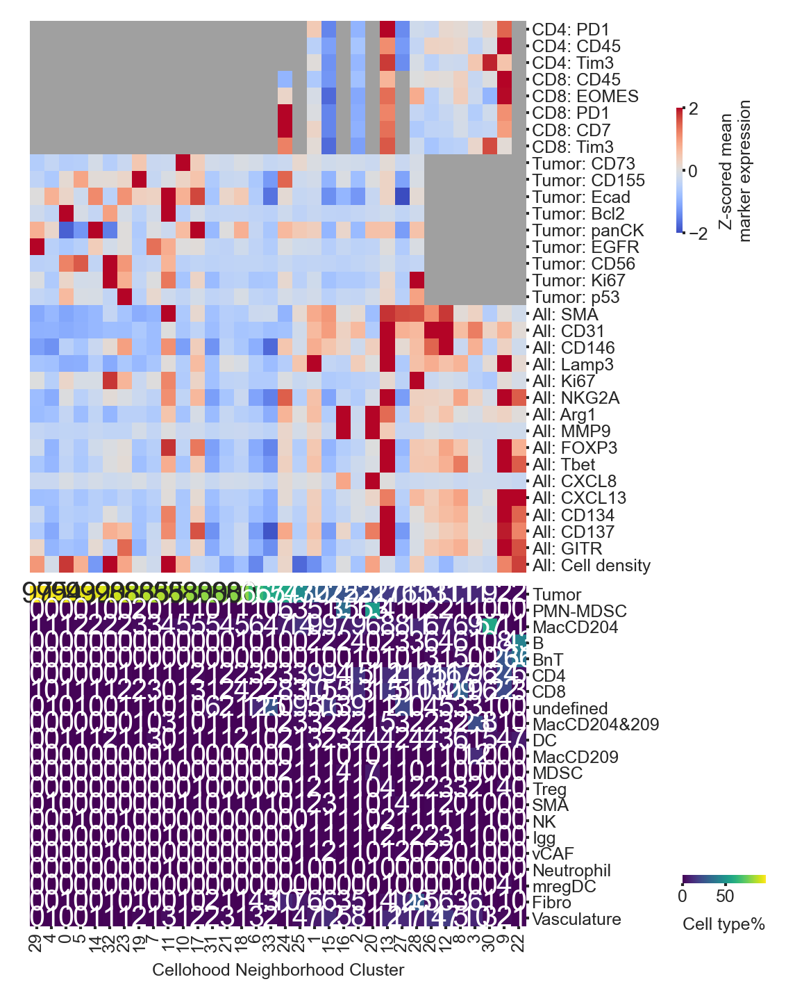

In [123]:
COLORBARS_SHIFT = 0.92

cc_abundance_std_argsort = (-celltype_percentages['Tumor'].values).argsort()

celltype_clustermap = sns.clustermap(
    (celltype_percentages[celltypes].T * 100)[cc_abundance_std_argsort], 
    annot=True,
    col_cluster=False,
    fmt='.0f',
    cmap='viridis',
    figsize=(5, 7),
    col_colors=cc_marker_ct_colors,
    #row_colors=[class_to_color[celltype_to_class[ct]] for ct in numpy.array(celltypes)],
    colors_ratio=0.015,
    yticklabels=True,
    xticklabels=cc_abundance_std_argsort,
    #linewidth=0.003
    #annot_kws={"size": 3},
    cbar_pos=[COLORBARS_SHIFT + 0.05, 0.1, 0.1, .007],
    cbar_kws={'label': 'Cell type%', 'orientation': 'horizontal'}
)


#handles = [Patch(facecolor=class_to_color[name]) for name in class_to_color]
#plt.legend(
#    handles, 
#    class_to_color, 
#    title=' Cell type Metatype',
#    bbox_to_anchor=(0.17, 0.53), 
#    bbox_transform=plt.gcf().transFigure,
#    frameon=False,
#    fontsize=6,
#)

celltype_clustermap.ax_col_dendrogram.set_visible(False)

cb_ax = celltype_clustermap.fig.add_axes([COLORBARS_SHIFT, .27, .05, .8])
cb_ax.imshow([[0, 1]])
cb_ax.set_visible(False)

cbar = celltype_clustermap.fig.colorbar(
    marker_sm, 
    drawedges=False,
    #bbox_to_anchor=(1, 0.5),
    label='Z-scored mean\nmarker expression',
    ax=cb_ax,
    #panchor=(1.5, 0.5),
    #anchor=(1.5, 0.5),
)

cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=6, size=1, pad=1)

celltype_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_clustermap.ax_row_dendrogram.set_visible(False)
celltype_clustermap.ax_col_dendrogram.set_visible(False)

celltype_clustermap.ax_heatmap.set_yticklabels(celltype_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1)
celltype_clustermap.ax_heatmap.set_xticklabels(celltype_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
celltype_clustermap.ax_col_colors.set_yticklabels(celltype_clustermap.ax_col_colors.get_yticklabels(), size=6)
celltype_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)


celltype_clustermap.fig.set_dpi(300)
celltype_clustermap.fig.set_size_inches((4, 6))
plt.tight_layout()

CD4


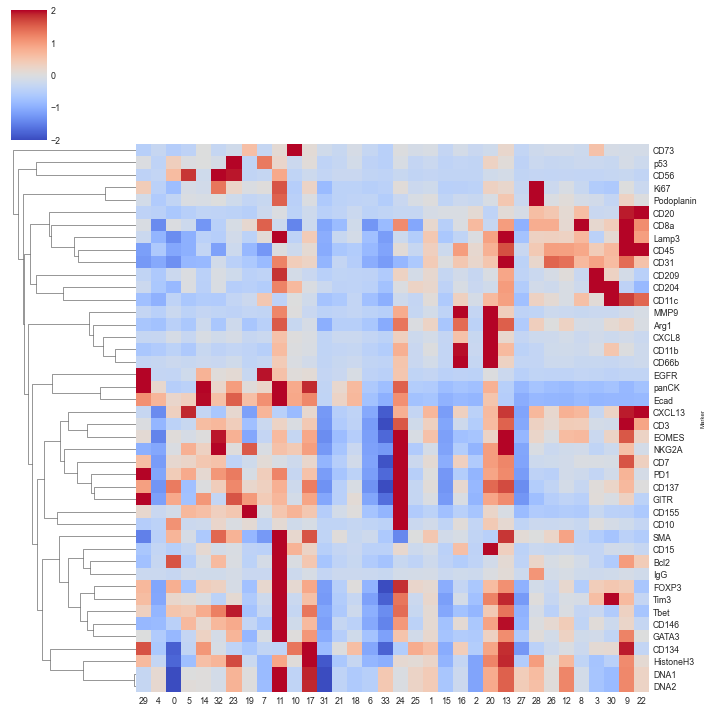

In [124]:
for ct in ['CD4']:
    print(ct)
    sns.clustermap(
        celltype_to_marker_dfs_clean[ct].loc[MARKERS_CLEAN][cc_abundance_std_argsort], 
        yticklabels=MARKERS_CLEAN,
        z_score=0,
        center=0,
        cmap='coolwarm',
        col_cluster=False,
        vmin=-2,
        vmax=2,
    )
    plt.show()

In [125]:
clustering_df = pandas.DataFrame(
    clusterer.cluster_centers_[GOOD_ROI_CLUSTERS_INDS],
    index=GOOD_ROI_CLUSTERS,
    columns=[col for col in range(CC_NB_OF_CLUSTERS)],
)

In [126]:
ct_norm = matplotlib.colors.Normalize(vmin=0, vmax=celltype_percentages.values.max())
ct_cmap = plt.get_cmap('viridis')

ct_sm = matplotlib.cm.ScalarMappable(norm=ct_norm, cmap=ct_cmap)

In [127]:
# NOTE: cc_marker_ct_colors is rebuilt from scratch above (cc_colors_dict), which
# drops the 'CN Class' column set earlier. In the original notebook this was masked
# by an out-of-order manual re-run of the 'CN Class' assignment cell shortly before
# the full_cc_colors_with_ct copy below (its saved execution_count shows it re-ran at
# step 219, after this rebuild's step 167, and just before the copy's step 229).
# Re-added here so a clean top-to-bottom run reproduces the same effective column.
cc_marker_ct_colors['CN Class'] = numpy.array(meta_cluster_colors)[numpy.argsort(META_CLUSTER_PERM)]

In [128]:
cc_marker_ct_colors

,CD4: PD1,CD4: CD45,CD4: Tim3,CD8: CD45,CD8: EOMES,CD8: PD1,CD8: CD7,CD8: Tim3,Tumor: CD73,Tumor: CD155,...,All: MMP9,All: FOXP3,All: Tbet,All: CXCL8,All: CXCL13,All: CD134,All: CD137,All: GITR,All: Cell density,CN Class
0,"(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...","[0.7087196897176471, 0.8057213889294117, 0.981...","[0.8958817682941177, 0.8499060565882353, 0.823...",...,"[0.753610618, 0.830232851, 0.960871157, 1.0]","[0.7633627801019607, 0.8350922218196078, 0.955...","[0.7486824103137254, 0.8276791079411765, 0.963...","[0.8433581741921568, 0.8618196540156863, 0.890...","[0.7289695795686274, 0.8174641357058824, 0.973...","[0.7189852929803922, 0.811992893745098, 0.9776...","[0.7289695795686274, 0.8174641357058824, 0.973...","[0.6461128107647058, 0.7644364965294117, 0.996...","[0.7851533046784314, 0.2208510887215686, 0.211...",#800000
1,"[0.9491505082901961, 0.7907852690666667, 0.710...","[0.7289695795686274, 0.8174641357058824, 0.973...","[0.8755573874313726, 0.860242158862745, 0.8514...","[0.6830556815607843, 0.790042626890196, 0.9897...","[0.8353447113529412, 0.8605139972941176, 0.898...","[0.8553783684509804, 0.8637781390980391, 0.876...","[0.9226814526235294, 0.8285681381176471, 0.777...","[0.8877520159490196, 0.8540404974980391, 0.834...","[0.8513716370313725, 0.8631253107372548, 0.881...","[0.8180564934117647, 0.8555896775450981, 0.914...",...,"[0.9127650614705882, 0.8366818943529412, 0.794...","[0.9527607176705882, 0.7829647976, 0.698645771...","[0.9605811984235294, 0.7625010185254902, 0.667...","[0.8755573874313726, 0.860242158862745, 0.8514...","[0.9383263563333333, 0.8089165520313726, 0.741...","[0.940878943, 0.8055964028235294, 0.7351665564...","[0.9595176584705882, 0.7669728545098039, 0.674...","[0.9434315296666667, 0.8022762536156862, 0.729...","[0.4305068882509804, 0.5648827414588236, 0.948...",#2E8B57
2,"[0.5706164368784313, 0.7041091618039216, 0.997...","[0.6566828675490196, 0.7718064767647058, 0.994...","[0.5869210038431373, 0.7181213123921568, 0.998...","[0.6354738224588236, 0.7567139921764706, 0.998...","[0.5216962808313725, 0.6595986063529412, 0.987...","[0.5434401939921568, 0.6800025894117647, 0.993...","[0.5597467255686274, 0.6947677280784313, 0.996...","[0.48924640790588236, 0.6275360555921569, 0.97...","[0.8136925818823529, 0.8542818385490196, 0.918...","[0.6247032376117647, 0.7483184872352941, 0.998...",...,"[0.8006008472941177, 0.8503583215607843, 0.930...","[0.7486824103137254, 0.8276791079411765, 0.963...","[0.8006008472941177, 0.8503583215607843, 0.930...","[0.7867207013568628, 0.8448072103686275, 0.939...","[0.8433581741921568, 0.8618196540156863, 0.890...","[0.8473649056117647, 0.8624724823764706, 0.885...","[0.6881884831921569, 0.7931783792980391, 0.988...","[0.7727059486039215, 0.8389782172392156, 0.949...","[0.6513978391568627, 0.7681214866470587, 0.995...",#2E8B57
3,"[0.8353447113529412, 0.8605139972941176, 0.898...","[0.753610618, 0.830232851, 0.960871157, 1.0]","[0.9545658223607844, 0.7790545618666667, 0.692...","[0.777377532854902, 0.8409212149490196, 0.9461...","[0.7960638698588236, 0.8486932057882353, 0.933...","[0.7035868880862746, 0.8025856365215686, 0.982...","[0.7486824103137254, 0.8276791079411765, 0.963...","[0.9127650614705882, 0.8366818943529412, 0.794...","(0.6274509803921569, 0.6274509803921569, 0.627...","(0.6274509803921569, 0.6274509803921569, 0.627...",...,"[0.8049647588235295, 0.8516661605568627, 0.926...","[0.839351442772549, 0.861166825654902, 0.89449...","[0.8553783684509804, 0.8637781390980391, 0.876...","[0.8049647588235295, 0.8516661605568627, 0.926...","[0.8136925818823529, 0.8542818385490196, 0.918..

In [129]:
full_cc_colors_with_ct = cc_marker_ct_colors.copy()

for celltype in celltype_clustermap.data2d.index:
    full_cc_colors_with_ct[f'{celltype}%'] = [
        ct_sm.to_rgba(x ** 0.5) for x in celltype_percentages[celltype]
    ]

In [130]:
full_cc_colors_with_ct.columns = [
    clean_up_celltype(col)
    for col in full_cc_colors_with_ct.columns
]

In [131]:
full_cc_colors_with_ct.index = [i for i in range(full_cc_colors_with_ct.shape[0])]

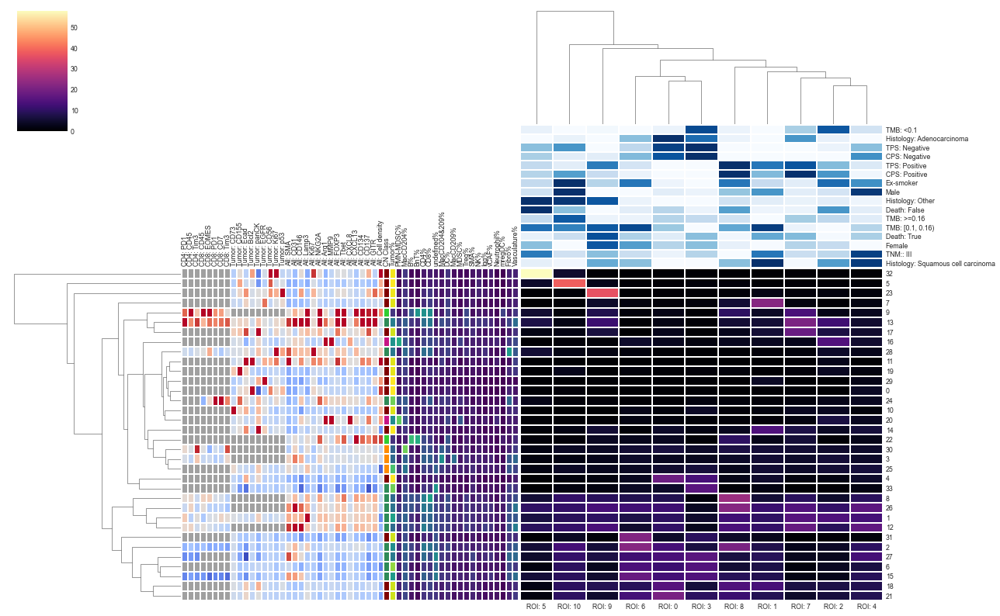

In [132]:
full_cm = sns.clustermap(
    clustering_df.T,  
    cmap='magma',
    col_colors=clinical_colors.T,
    row_colors=full_cc_colors_with_ct,
    figsize=(18, 12),
    colors_ratio=(0.007, 0.015),
    linewidth=0.00395,
    #vmin=-1.5,
    #vmax=1.5,
)

full_cm.ax_row_colors.xaxis.tick_top()
full_cm.ax_row_colors.xaxis.set_tick_params(rotation=90)
#dir(full_cm.ax_row_colors.xaxis)

In [133]:
clinical_colors_with_cluster_color = clinical_colors.copy().T
clinical_colors_with_cluster_color['ROI Cluster'] = [cluster_sm.to_rgba(x) for x in GOOD_ROI_CLUSTERS_INDS]

In [134]:
CELLTYPES_TO_LEAVE = [
    celltype_ for celltype_ in celltypes + ['All']
    if celltype_ not in ['MDSC', 'Treg', 'SMA', 'NK', 'Igg', 'vCAF', 'Neutrophil', 'mregDC', 'DC', 'undefined']
]

MARKERS_TO_LEAVE = ['Tumor: TCF7', 'Tumor: cl.PARP', 'All: Cell density', 'MacCD204&209: CD11c', 'MacCD204: CD11c']

def is_color_col_to_leave(col, ct_to_leave=None):
    if ct_to_leave is None:
        ct_to_leave = CELLTYPES_TO_LEAVE
    if col in MARKERS_TO_LEAVE:
        return False
    if col.endswith('%'):
        print(col)
        return col[:-1] in ct_to_leave
    if ':' in col:
        print(f':{col}')
        return col.split(':')[0] in CELLTYPES_TO_LEAVE
    return True

# BIG-L Fiugre

In [135]:
big_l_full_cc_colors_with_ct = full_cc_colors_with_ct.copy()
big_l_clustering_df = clustering_df.copy()
big_l_clustering_df.columns.name = ''
ct_to_l_selector = numpy.array(
    [is_color_col_to_leave(col) for col in big_l_full_cc_colors_with_ct.columns]
)
big_l_full_cc_colors_with_ct = big_l_full_cc_colors_with_ct.iloc[:, ct_to_l_selector]

:CD4: PD1
:CD4: CD45
:CD4: Tim3
:CD8: CD45
:CD8: EOMES
:CD8: PD1
:CD8: CD7
:CD8: Tim3
:Tumor: CD73
:Tumor: CD155
:Tumor: Ecad
:Tumor: Bcl2
:Tumor: panCK
:Tumor: EGFR
:Tumor: CD56
:Tumor: Ki67
:Tumor: p53
:All: SMA
:All: CD31
:All: CD146
:All: Lamp3
:All: Ki67
:All: NKG2A
:All: Arg1
:All: MMP9
:All: FOXP3
:All: Tbet
:All: CXCL8
:All: CXCL13
:All: CD134
:All: CD137
:All: GITR
Tumor%
PMN-MDSC%
MacCD204%
B%
BnT%
CD4%
CD8%
undefined%
MacCD204&209%
DC%
MacCD209%
MDSC%
Treg%
SMA%
NK%
Igg%
vCAF%
Neutrophil%
mregDC%
Fibro%
Vasculature%


In [136]:
def clean_up_big_l_clinical_tick(tick):
    tick_text = tick.get_text()
    return tick_text

In [137]:
CLUSTERS_TO_EXCLUDE = []
CLUSTERS_TO_KEEP = [cc_ for cc_ in range(CC_NB_OF_CLUSTERS) if cc_ not in CLUSTERS_TO_EXCLUDE]

In [138]:
big_l_full_cc_colors_with_ct.columns = [
    col[:-1] if col.endswith('%') else col
    for col in big_l_full_cc_colors_with_ct.columns
]

In [139]:
big_l_full_cc_colors_with_ct.insert(
    32, '', [(1, 1, 1, 1) for _ in range(big_l_full_cc_colors_with_ct.shape[0])]
)

In [140]:
clinical_colors_with_cluster_color.columns = [
    col.replace('TNB', 'TNM')
    for col in clinical_colors_with_cluster_color.columns
]

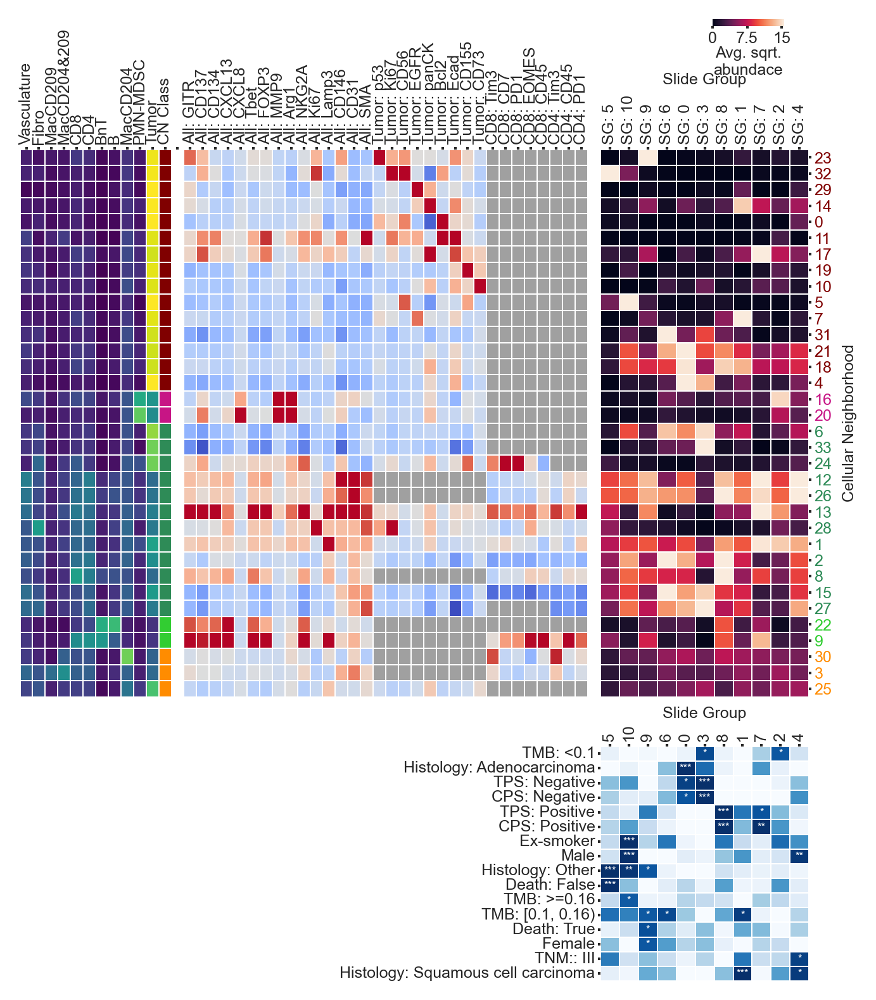

In [141]:
matplotlib.rcParams['font.family'] = 'Arial'

table = big_l_clustering_df[META_CLUSTER_PERM].T#[::-1]
table.index.name = 'Cellular Neighborhood'
table.columns.name = 'Slide Group'

big_l_figure = sns.clustermap(
    table,
    #row_cluster=False,
    figsize=(7.5, 6.5),
    linewidth=0.003,
    row_colors=big_l_full_cc_colors_with_ct.iloc[:, ::-1],
    col_colors=clinical_colors_with_cluster_color[list(clinical_colors_with_cluster_color.columns)[:-1]],
    colors_ratio=(0.013, 0.015),
    xticklabels=[col.replace('ROI', 'SG') for col in table.columns],
    yticklabels=True,
    row_cluster=False,
    vmax=numpy.quantile(table.values.flatten(), 0.95),
    cbar_pos=[0.645, 0.71, 0.05, 0.006],
    cbar_kws={'label': 'CN abundance', 'aspect': 10, 'orientation': 'horizontal'}
)

big_l_figure.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
big_l_figure.ax_heatmap.set_yticklabels(
    big_l_figure.ax_heatmap.get_yticklabels(), size=6,
)
big_l_figure.ax_heatmap.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_heatmap.set_xticklabels(
    big_l_figure.ax_heatmap.get_xticklabels(), size=6,
)
big_l_figure.ax_heatmap.xaxis.tick_top()
big_l_figure.ax_heatmap.yaxis.tick_right()

big_l_figure.ax_col_colors.yaxis.set_tick_params(size=1, pad=1, rotation=0)
big_l_figure.ax_col_colors.set_yticklabels(
    [clean_up_big_l_clinical_tick(tick) for tick in big_l_figure.ax_col_colors.get_yticklabels()],
    size=6,
)
big_l_figure.ax_row_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_row_colors.set_xticklabels(
    big_l_figure.ax_row_colors.get_xticklabels(), size=6,
)
big_l_figure.ax_row_colors.xaxis.tick_top()
big_l_figure.ax_col_colors.yaxis.tick_left()

ax_row_colors = big_l_figure.ax_row_colors
ax_col_colors = big_l_figure.ax_col_colors
row_box = ax_row_colors.get_position()
col_box = ax_col_colors.get_position()

box_heatmap = big_l_figure.ax_heatmap.get_position()
ax_col_colors.set_position([col_box.x0, box_heatmap.min[1] - col_box.height - 0.04, col_box.width, col_box.height])
ax_row_colors.set_position([box_heatmap.x0 - row_box.width - 0.009, row_box.y0, row_box.width, row_box.height])

big_l_figure.ax_col_dendrogram.set_visible(False)
big_l_figure.ax_row_dendrogram.set_visible(False)
#big_l_figure.ax_cbar.set_visible(False)
big_l_figure.fig.set_dpi(PLOTTING_DPI)
#big_l_figure.fig.set_size_inches((9, 6.5))

#big_l_figure.ax_cbar.outline.set_visible(False)
big_l_figure.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
big_l_figure.ax_cbar.set_xlabel('Avg. sqrt.\nabundace', labelpad=0, size=6)
big_l_figure.ax_cbar.set_xticks(
    [0, 7.5, 15],
    labels=[0, 7.5, 15],
)

annot_shape = clinical_cm.data2d.values.shape
permuted_rois = list(big_l_figure.data2d.columns)
permuted_features = list(clinical_cm.data2d.index)

for i in range(annot_shape[1]):
    for j in range(annot_shape[0]):
        current_text = clinical_cm.data2d.T.loc[permuted_rois[i]].loc[permuted_features[j]]
        current_text = round(current_text, 2)
        stars = ''
        if current_text < 0.2:
            stars += '*'
        if current_text < 0.05:
            stars += '*'
        if current_text < 0.01:
            stars += '*'
        big_l_figure.ax_col_colors.text(
            i + 0.5, j + 0.5, 
            stars, 
            horizontalalignment='center', 
            verticalalignment='center',
            c='w', size=4)
        
big_l_figure.ax_col_colors.set_xlabel('Slide Group', labelpad=2.2)
big_l_figure.ax_col_colors.xaxis.set_label_position('top')

big_l_figure.ax_col_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_col_colors.xaxis.tick_top()
_ = big_l_figure.ax_col_colors.set_xticks(
    ticks=[i + 0.5 for i in range(len(big_l_figure.data2d.columns))],
    labels=[int(x.split(':')[1]) for x in big_l_figure.data2d.columns],
    size=6,
)

# NOTE: full_cc_colors_with_ct has no 'CN Class' column in this (Panel 2)
# notebook -- that superclass grouping was a Panel-1-specific concept never
# added here. Guarding rather than fabricating a column; ticks keep default color.
try:
    for tick in big_l_figure.ax_heatmap.get_yticklabels():
        tick.set_color(full_cc_colors_with_ct.iloc[int(tick.get_text())]['CN Class'])
except (KeyError, NameError):
    pass
    
big_l_figure.ax_heatmap.xaxis.set_label_position('top')


In [142]:
sg_counts = roi_counts.groupby('ROI').size().to_frame()
sg_counts.index = [f'ROI: {i}' for i in sg_counts.index]

In [143]:
# NOTE: originally a hardcoded, positionally-matched list of 20 count
# expressions assumed to line up 1:1 with clinical_cm.data2d.index. That
# assumption held for the old clinical data (verified: the 20 hardcoded
# expressions do match the 20 labels in that order), but with the corrected
# clinical data fewer categories clear the FDR significance threshold (16
# instead of 20), so positional indexing breaks (ValueError: shape mismatch).
# Rebuilt as an explicit label -> count-expression lookup (covering every
# label seen in either run) and applied dynamically to whatever labels are
# actually present, in their existing order, so it is robust to which
# categories happen to be significant.
_label_to_count = {
    'TMB: <0.1': (roi_cluster_with_clinical['tmb_class'] == '<0.1').sum(),
    'Histology: Adenocarcinoma': (roi_cluster_with_clinical['simple_histology'] == 'Adenocarcinoma').sum(),
    'Non-smoker': (roi_cluster_with_clinical['smoking_status'] == 'Non-smoker').sum(),
    'TPS: Negative': (roi_cluster_with_clinical['TPS_score'] == 'negative').sum(),
    'CPS: Negative': (roi_cluster_with_clinical['CPS_score'] == 'negative').sum(),
    'TPS: Positive': (roi_cluster_with_clinical['TPS_score'] == 'positive').sum(),
    'CPS: Positive': (roi_cluster_with_clinical['CPS_score'] == 'positive').sum(),
    'Male': (roi_cluster_with_clinical['Gender_male'] == True).sum(),
    'Histology: Other': (roi_cluster_with_clinical['simple_histology'] == 'Other').sum(),
    'TNM:: I': (roi_cluster_with_clinical['simple_stage'] == 1).sum(),
    'TMB: >=0.16': (roi_cluster_with_clinical['tmb_class'] == '>=0.16').sum(),
    'Death: False': (roi_cluster_with_clinical['death'] == False).sum(),
    'Ex-smoker': (roi_cluster_with_clinical['smoking_status'] == 'Ex-smoker').sum(),
    'TMB: [0.1, 0.16)': (roi_cluster_with_clinical['tmb_class'] == '[0.1, 0.16)').sum(),
    'Death: True': (roi_cluster_with_clinical['death'] == True).sum(),
    'Female': (roi_cluster_with_clinical['Gender_male'] == False).sum(),
    'TNM:: III': (roi_cluster_with_clinical['simple_stage'] == 3).sum(),
    'TNM: 3, 4': (roi_cluster_with_clinical['stage_2-'] == False).sum(),
    'TNM:: II': (roi_cluster_with_clinical['simple_stage'] == 2).sum(),
    'Histology: Squamous cell carcinoma': (roi_cluster_with_clinical['simple_histology'] == 'Squamous cell carcinoma').sum(),
}
assert set(clinical_cm.data2d.index).issubset(_label_to_count), (
    'clinical_cm.data2d.index has a label with no known count expression -- '
    'extend _label_to_count above: ' + str(set(clinical_cm.data2d.index) - set(_label_to_count))
)

clinical_counts_for_big_l = pandas.DataFrame(
    [_label_to_count[label] for label in clinical_cm.data2d.index],
    index=clinical_cm.data2d.index
)

# sanity checks: paired categories should sum to the same total
_n = len(roi_cluster_with_clinical)
if 'Male' in clinical_counts_for_big_l.index and 'Female' in clinical_counts_for_big_l.index:
    assert clinical_counts_for_big_l.loc['Male', 0] + clinical_counts_for_big_l.loc['Female', 0] == _n
if 'Death: True' in clinical_counts_for_big_l.index and 'Death: False' in clinical_counts_for_big_l.index:
    assert clinical_counts_for_big_l.loc['Death: True', 0] + clinical_counts_for_big_l.loc['Death: False', 0] == _n
print('sanity checks passed, n =', _n)
clinical_counts_for_big_l

sanity checks passed, n = 189


,0
TMB: <0.1,89
Histology: Adenocarcinoma,123
TPS: Negative,127
CPS: Negative,89
TPS: Positive,57
CPS: Positive,95
Ex-smoker,147
Male,110
Histology: Other,20
Death: False,147


In [144]:
# NOTE: raw_clinical_to_clean_clinical_names (defined earlier) maps
# 'roman_simple_stage' -> 'TNM:', so clean_clinical_name() applied to a raw column
# name like 'roman_simple_stage: I' actually yields 'TNM:: I' (double colon), not
# 'TNM Stage: I' as this cell originally assumed. The original notebook's saved
# output only shows 'TNM Stage: ...' because it was captured from an out-of-order
# run against an older version of that mapping dict. Added the double-colon variants
# below (same longest-match-first ordering) so a clean sequential run still folds
# these down to the intended 'TNM: 1' / 'TNM: 2' / ... labels; kept the original
# 'TNM Stage: ...' replacements too since they are harmless no-ops on current data.
clinical_colors_with_cluster_color.columns = [
    col.replace('0.16', '16').replace('0.1', '10').replace(
    'TNM Stage: III, IV', 'TNM: 3, 4').replace('TNM Stage: III', 'TNM: 3').replace(
        'TNM Stage: II', 'TNM: 2').replace('TNM Stage: I', 'TNM: 1').replace(
    'TNM:: III, IV', 'TNM: 3, 4').replace('TNM:: III', 'TNM: 3').replace(
        'TNM:: II', 'TNM: 2').replace('TNM:: I', 'TNM: 1')
    for col in clinical_colors_with_cluster_color.columns
]

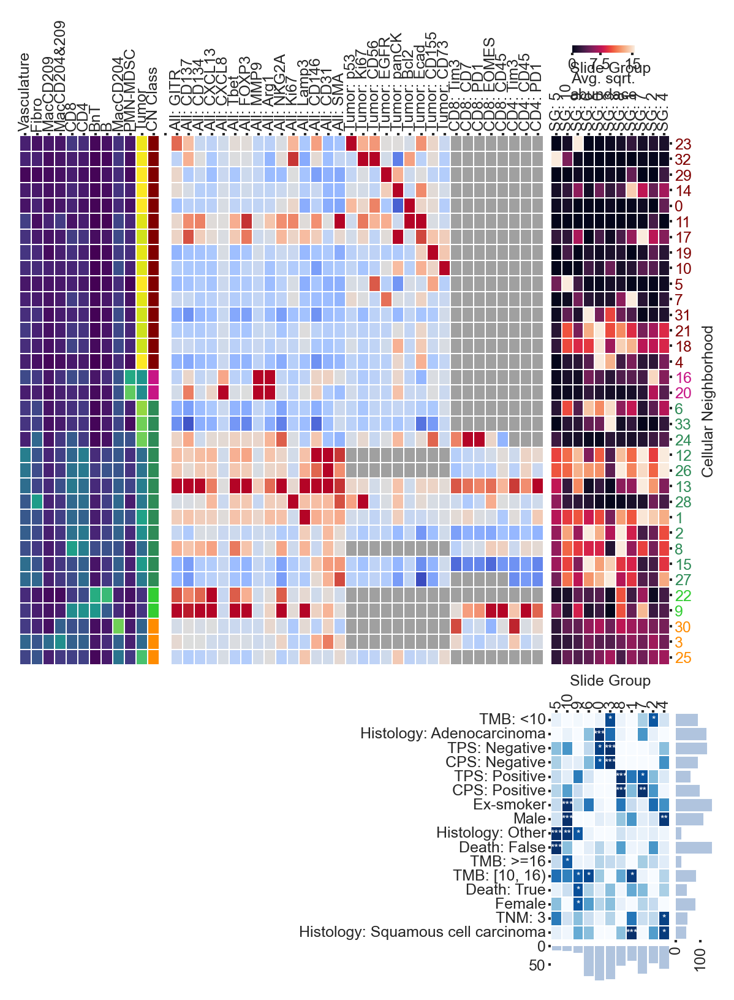

In [145]:
matplotlib.rcParams['font.family'] = 'Arial'

table = big_l_clustering_df[META_CLUSTER_PERM].T#[::-1]
table.index.name = 'Cellular Neighborhood'
table.columns.name = 'Slide Group'

big_l_figure = sns.clustermap(
    table,
    #row_cluster=False,
    figsize=(6.8, 6.5),
    linewidth=0.003,
    row_colors=big_l_full_cc_colors_with_ct.iloc[:, ::-1],
    col_colors=clinical_colors_with_cluster_color[list(clinical_colors_with_cluster_color.columns)[:-1]],
    colors_ratio=(0.0145, 0.015),
    xticklabels=[col.replace('ROI', 'SG') for col in table.columns],
    yticklabels=True,
    row_cluster=False,
    vmax=numpy.quantile(table.values.flatten(), 0.95),
    cbar_pos=[0.605, 0.68, 0.05, 0.006],
    cbar_kws={'label': 'CN abundance', 'aspect': 10, 'orientation': 'horizontal'}
)

big_l_figure.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
big_l_figure.ax_heatmap.set_yticklabels(
    big_l_figure.ax_heatmap.get_yticklabels(), size=6,
)
big_l_figure.ax_heatmap.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_heatmap.set_xticklabels(
    big_l_figure.ax_heatmap.get_xticklabels(), size=6,
)
big_l_figure.ax_heatmap.xaxis.tick_top()
big_l_figure.ax_heatmap.yaxis.tick_right()

big_l_figure.ax_col_colors.yaxis.set_tick_params(size=1, pad=1, rotation=0)
big_l_figure.ax_col_colors.set_yticklabels(
    [clean_up_big_l_clinical_tick(tick) for tick in big_l_figure.ax_col_colors.get_yticklabels()],
    size=6,
)
big_l_figure.ax_row_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_row_colors.set_xticklabels(
    big_l_figure.ax_row_colors.get_xticklabels(), size=6,
)
big_l_figure.ax_row_colors.xaxis.tick_top()
big_l_figure.ax_col_colors.yaxis.tick_left()

ax_row_colors = big_l_figure.ax_row_colors
ax_col_colors = big_l_figure.ax_col_colors
row_box = ax_row_colors.get_position()
col_box = ax_col_colors.get_position()

box_heatmap = big_l_figure.ax_heatmap.get_position()
ax_col_colors.set_position([col_box.x0, box_heatmap.min[1] - col_box.height - 0.04, col_box.width, col_box.height])
ax_row_colors.set_position([box_heatmap.x0 - row_box.width - 0.006, row_box.y0, row_box.width, row_box.height])

big_l_figure.ax_col_dendrogram.set_visible(False)
big_l_figure.ax_row_dendrogram.set_visible(False)
#big_l_figure.ax_cbar.set_visible(False)
big_l_figure.fig.set_dpi(PLOTTING_DPI)
#big_l_figure.fig.set_size_inches((9, 6.5))

#big_l_figure.ax_cbar.outline.set_visible(False)
big_l_figure.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
big_l_figure.ax_cbar.set_xlabel('Avg. sqrt.\nabundace', labelpad=0, size=6)
big_l_figure.ax_cbar.set_xticks(
    [0, 7., 15],
    labels=[0, 7.5, 15],
)

ordered_counts = [sg_counts.loc[roi].values[0] for roi in permuted_rois]
ordered_counts_cl = clinical_counts_for_big_l.values[::-1, 0]

bar_height = 0.03  # Adjust this to change the height of the barplot
bar_height_cl = 0.03
bar_ax = big_l_figure.fig.add_axes([
    col_box.x0, 
    ax_col_colors.get_position().min[1] - bar_height - 0.005,  # Position above col_colors
    col_box.width, 
    bar_height
])

bar_ax_cl = big_l_figure.fig.add_axes([
    col_box.x1 + 0.005, 
    ax_col_colors.get_position().max[1] - col_box.height,  # Position above col_colors
    bar_height_cl,
    col_box.height
])


# Create the barplot
x_positions = list(range(len(ordered_counts)))
bars_ = bar_ax.bar(x_positions, ordered_counts, width=0.75, 
                  color='lightsteelblue', edgecolor='lightsteelblue', linewidth=0.5)
bar_ax.invert_yaxis()
bar_ax.set_facecolor('white')

x_positions_cl = list(range(len(ordered_counts_cl)))
bars_cl = bar_ax_cl.barh(x_positions_cl, ordered_counts_cl, height=0.75, 
                  color='lightsteelblue', edgecolor='lightsteelblue', linewidth=0.5)
#bar_ax_cl.invert_xaxis()
bar_ax_cl.set_facecolor('white')


# Style the barplot
bar_ax.set_xlim(-0.5, len(ordered_counts) - 0.5)
bar_ax.set_xticks([])  # Remove x-axis ticks since they're shown below
bar_ax.spines['bottom'].set_visible(False)
bar_ax.spines['top'].set_visible(False)
bar_ax.spines['right'].set_visible(False)
bar_ax.spines['left'].set_linewidth(0.0)

# Style y-axis
bar_ax.tick_params(axis='y', labelsize=6, size=1, pad=1)
#bar_ax.set_ylabel('Counts', size=6, labelpad=2)
#bar_ax.yaxis.tick_right()

bar_ax_cl.set_ylim(-0.5, len(ordered_counts_cl) - 0.5)
bar_ax_cl.set_yticks([])  # Remove x-axis ticks since they're shown below
bar_ax_cl.spines['bottom'].set_visible(False)
bar_ax_cl.spines['top'].set_visible(False)
bar_ax_cl.spines['right'].set_visible(False)
bar_ax_cl.spines['left'].set_linewidth(0.0)

# Style y-axis
bar_ax_cl.tick_params(axis='x', labelsize=6, size=1, pad=1., rotation=90)

annot_shape = clinical_cm.data2d.values.shape
permuted_rois = list(big_l_figure.data2d.columns)
permuted_features = list(clinical_cm.data2d.index)

for i in range(annot_shape[1]):
    for j in range(annot_shape[0]):
        current_text = clinical_cm.data2d.T.loc[permuted_rois[i]].loc[permuted_features[j]]
        current_text = round(current_text, 2)
        stars = ''
        if current_text < 0.2:
            stars += '*'
        if current_text < 0.05:
            stars += '*'
        if current_text < 0.01:
            stars += '*'
        big_l_figure.ax_col_colors.text(
            i + 0.5, j + 0.5, 
            stars, 
            horizontalalignment='center', 
            verticalalignment='center',
            c='w', size=4)
        
big_l_figure.ax_col_colors.set_xlabel('Slide Group', labelpad=2.2)
big_l_figure.ax_col_colors.xaxis.set_label_position('top')

big_l_figure.ax_col_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_col_colors.xaxis.tick_top()
_ = big_l_figure.ax_col_colors.set_xticks(
    ticks=[i + 0.5 for i in range(len(big_l_figure.data2d.columns))],
    labels=[int(x.split(':')[1]) for x in big_l_figure.data2d.columns],
    size=6,
)

# NOTE: full_cc_colors_with_ct has no 'CN Class' column in this (Panel 2)
# notebook -- that superclass grouping was a Panel-1-specific concept never
# added here. Guarding rather than fabricating a column; ticks keep default color.
try:
    for tick in big_l_figure.ax_heatmap.get_yticklabels():
        tick.set_color(full_cc_colors_with_ct.iloc[int(tick.get_text())]['CN Class'])
except (KeyError, NameError):
    pass
    
big_l_figure.ax_heatmap.xaxis.set_label_position('top')


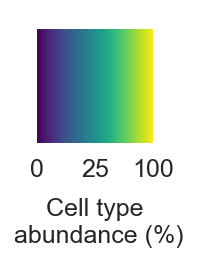

In [146]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

# Define normalization: data values are square-rooted before mapping to colors
norm = mpl.colors.Normalize(vmin=0, vmax=1)
sqrt_norm = mpl.colors.Normalize(vmin=np.sqrt(0), vmax=np.sqrt(1))

# Create colormap
cmap = plt.cm.viridis

# Create a scalar mappable with sqrt-transformed values
sm = mpl.cm.ScalarMappable(norm=sqrt_norm, cmap=cmap)
sm.set_array([])

# Create figure and colorbar
fig, ax = plt.subplots(figsize=(0.5, 1), dpi=300)
fig.subplots_adjust(bottom=0.5)

cbar = plt.colorbar(sm, cax=ax, orientation='horizontal')

# Define ticks (original data values)
tick_values = numpy.array([0, 25, 100])
# Convert them to sqrt scale for placement
cbar.set_ticks(np.sqrt(tick_values / 100), labels=tick_values, fontsize=6)
# Label them with original (unsquare-rooted) values
cbar.set_ticklabels([f"{v:g}" for v in tick_values])

cbar.set_label('Cell type\n abundance (%)')

plt.show()


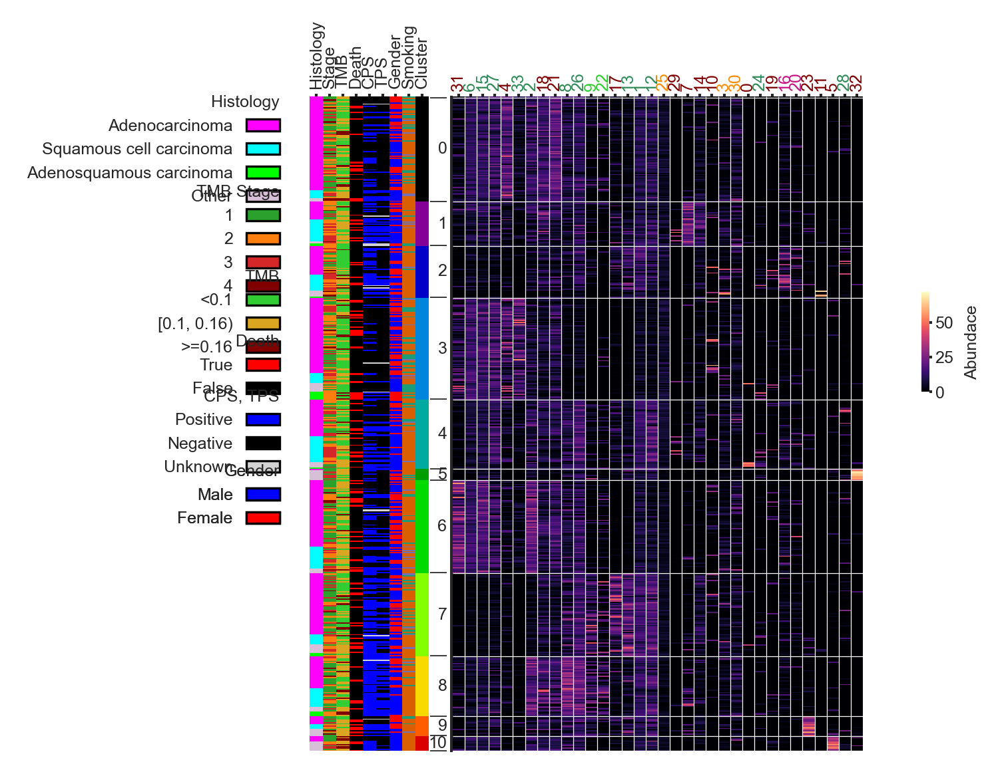

In [147]:
plt.rcParams['font.family'] = 'Arial'

cluster_norm = matplotlib.colors.Normalize(vmin=0, vmax=ROI_CLUSTERS)
cluster_cmap = plt.get_cmap('nipy_spectral')

cluster_sm = matplotlib.cm.ScalarMappable(norm=cluster_norm, cmap=cluster_cmap)

vectors_df = pandas.DataFrame(
    vectors.T,
    index=patient_to_clinical_colors_df.index,
)
#vectors_df.index.name = ROI_PLOT_NAME
#vectors_df.columns.name = CC_PLOT_NAME


patient_to_clinical_colors_df['Cluster'] = [cluster_sm.to_rgba(x) for x in clusters]

BASE = 30

hist_to_int = {
    'Adenocarcinoma': 0, 
    'Squamous cell carcinoma': 1, 
    'Other': 2,
    'Adenosquamous carcinoma': 3,
}

clusters_with_histology = clusters.copy()

for ind_, (cl, hist) in enumerate(zip(clusters_with_histology, roi_counts['simple_histology'])):
    clusters_with_histology[ind_] = BASE * cl + hist_to_int[hist]

patient_clustermap = sns.clustermap( 
    vectors_df.iloc[clusters_with_histology.argsort()].T.iloc[corr_cmap.data2d.index].T,
    col_cluster=False,
    row_cluster=False,
    xticklabels=1,
    cbar_pos=[.99, 0.5, 0.01, .1],
    cbar_kws={'label': 'Abundace'},
    yticklabels=horizontal_ticks,
    row_colors=patient_to_clinical_colors_df,
    figsize=(3.95, 5),
    colors_ratio=0.02,
    cmap='magma',
)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(rotation=0)

patient_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
patient_clustermap.ax_row_dendrogram.set_visible(False)
patient_clustermap.ax_col_dendrogram.set_visible(False)

patient_clustermap.ax_heatmap.set_yticklabels(
    patient_clustermap.ax_heatmap.get_yticklabels(), size=6)
patient_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
patient_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
patient_clustermap.ax_heatmap.set_xticklabels(
    patient_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)


patient_clustermap.ax_row_colors.xaxis.set_tick_params(size=1, top=True, pad=2, rotation=90)
patient_clustermap.ax_row_colors.set_xticklabels(
    patient_clustermap.ax_row_colors.get_xticklabels(), size=6,
)
patient_clustermap.ax_row_colors.xaxis.tick_top()
#patient_clustermap.ax_col_colors.set_yticklabels(
#    patient_clustermap.ax_col_colors.get_yticklabels(), size=6
#)
#patient_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

LEGEND_SPACING = 0.195

GOOD_HISTS = ['Adenocarcinoma', 'Squamous cell carcinoma', 'Adenosquamous carcinoma', 'Other']

pos_neg_handles = [
    matplotlib.patches.Patch(
        facecolor=tau.SIMPLE_HISTOLOGY_COLORS[name], 
        edgecolor='black') for name in GOOD_HISTS
]
pos_neg_legend = plt.legend(
    pos_neg_handles, 
    GOOD_HISTS, 
    title='Histology',
    bbox_to_anchor=(LEGEND_SPACING, .8125), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(pos_neg_legend)

GOOD_STAGES = [1, 2, 3, 4]

grade_handles = [
    matplotlib.patches.Patch(facecolor=tau.SIMPLE_STAGE_COLORS[name], edgecolor='black') 
    for name in GOOD_STAGES
]
grade_legend = plt.legend(
    grade_handles, 
    GOOD_STAGES, 
    title='TMB Stage',
    bbox_to_anchor=(LEGEND_SPACING, .7225), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(grade_legend)

GOOD_TMB = ['<0.1', '[0.1, 0.16)', '>=0.16']

tmb_handles = [
    matplotlib.patches.Patch(facecolor=tmb_color[name], edgecolor='black')
    for name in GOOD_TMB
]
tmb_legend = plt.legend(
    tmb_handles, 
    GOOD_TMB, 
    title='TMB',
    bbox_to_anchor=(LEGEND_SPACING, .6375), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(tmb_legend)

death_handles = [
    matplotlib.patches.Patch(facecolor=death_color[name], edgecolor='black') 
    for name in death_color
]
death_legend = plt.legend(
    death_handles, 
    death_color, 
    title='Death',
    bbox_to_anchor=(LEGEND_SPACING, .5725), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(death_legend)

GOOD_TPSES = ['Positive', 'Negative', 'Unknown']

ps_handles = [
    matplotlib.patches.Patch(facecolor=tps_color[name], edgecolor='black')
    for name in tps_color
]
ps_legend = plt.legend(
    ps_handles, 
    GOOD_TPSES,
    title='CPS, TPS',
    bbox_to_anchor=(LEGEND_SPACING, .5175), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(ps_legend)

neo_handles = [
    matplotlib.patches.Patch(facecolor=neo_color[x], edgecolor='black')
    for x in neo_color
]
neo_legend = plt.legend(
    neo_handles, 
    neo_color, 
    title=f'{GENDER_PLOT_NAME}',
    bbox_to_anchor=(LEGEND_SPACING, .4425), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    fontsize=6,
    alignment='right',
    markerfirst=False,
)
plt.gcf().add_artist(neo_legend)
    
patient_clustermap.ax_heatmap.xaxis.tick_top()
patient_clustermap.ax_heatmap.yaxis.tick_left()

ax_row_colors = patient_clustermap.ax_row_colors
row_box = ax_row_colors.get_position()

box_heatmap = patient_clustermap.ax_heatmap.get_position()
ax_row_colors.set_position([box_heatmap.x0 - row_box.width - 0.03, row_box.y0, row_box.width, row_box.height])


# NOTE: full_cc_colors_with_ct is defined later in the notebook (out-of-order
# editing artifact); guard rather than fail here -- ticks keep default color.
try:
    for tick in patient_clustermap.ax_heatmap.get_xticklabels():
        tick.set_color(full_cc_colors_with_ct.iloc[int(tick.get_text())]['CN Class'])
except (NameError, KeyError):
    pass
    
for i in range(1, vectors_df.shape[1]):
    patient_clustermap.ax_heatmap.vlines(i, 0, vectors_df.shape[0], linewidth=0.3, color="white")

for bar in bars:
    patient_clustermap.ax_heatmap.hlines(bar + 1, 0, vectors_df.shape[1], linewidth=0.3, color="white")

patient_clustermap.fig.set_dpi(PLOTTING_DPI)
#patient_clustermap.fig.set_size_inches((4, 8))

In [148]:
other_images = set(roi_counts['image'][roi_counts['simple_histology'] == 'Other'])

In [149]:
other_cell_df = cell_df[cell_df['image'].apply(lambda x: x in other_images)]
non_other_cell_df = cell_df[cell_df['image'].apply(lambda x: x not in other_images)]

In [150]:
other_cell_df.shape, non_other_cell_df.shape

((216279, 88), (1440351, 88))

In [151]:
other_counts_n = pandas.melt(pandas.pivot_table(
    other_cell_df, 
    values=DUMMY_COL_NAME, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=['image'],
    aggfunc="sum",
).fillna(0).T)

non_other_counts_n = pandas.melt(pandas.pivot_table(
    non_other_cell_df, 
    values=DUMMY_COL_NAME, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=['image'],
    aggfunc="sum",
).fillna(0).T)

other_counts = other_counts_n.copy()
non_other_counts = non_other_counts_n.copy()
other_counts['value'] = other_counts_n['value'] ** 0.5
non_other_counts['value'] = non_other_counts_n['value'] ** 0.5

In [152]:
other_counts['Source'] = 'Other'
non_other_counts['Source'] = 'Non-other'

full_other_counts = pandas.concat([other_counts, non_other_counts])

In [153]:
other_p_c = other_counts_n.groupby('Cellohood Neighborhood Cluster')['value'].mean()
non_other_p_c = non_other_counts_n.groupby('Cellohood Neighborhood Cluster')['value'].mean()

In [154]:
non_other_pc_np, other_pc_np = numpy.zeros((CC_NB_OF_CLUSTERS,)), numpy.zeros((CC_NB_OF_CLUSTERS,))

In [155]:
for ind_, val_ in zip(non_other_p_c.index, non_other_p_c.values):
    non_other_pc_np[ind_] = val_
    
    
for ind_, val_ in zip(other_p_c.index, other_p_c.values):
    other_pc_np[ind_] = val_

In [156]:
import scipy

ttest_ps = []
ttest_ts_ps = []
log_fold = []


for cl_ in range(CC_NB_OF_CLUSTERS):
    current_cc_counts = full_other_counts[full_other_counts['Cellohood Neighborhood Cluster'] == cl_]
    current_other_cc_counts = current_cc_counts[current_cc_counts['Source'] == 'Other']
    current_non_other_cc_counts = current_cc_counts[current_cc_counts['Source'] != 'Other']
    try:
        current_test = scipy.stats.ttest_ind(
            current_other_cc_counts['value'],
            current_non_other_cc_counts['value'],
            alternative='greater',
            equal_var=False,
        )
        if numpy.isnan(current_test.pvalue):
            print(cl_)
            ttest_ps.append(1)
        else:
            ttest_ps.append(current_test.pvalue)
            
        current_test_ts = scipy.stats.ttest_ind(
            current_other_cc_counts['value'],
            current_non_other_cc_counts['value'],
            alternative='two-sided',
            #equal_var=False,
        )
        if numpy.isnan(current_test_ts.pvalue):
            print(cl_)
            ttest_ts_ps.append(1)
        else:
            ttest_ts_ps.append(current_test_ts.pvalue)
    except:
        ttest_ps.append(1.)
    log_fold.append(
        numpy.log2(numpy.mean(current_other_cc_counts['value'])) - numpy.log2(numpy.mean(current_non_other_cc_counts['value'])))

11
11


In [157]:
import statsmodels

_, ttest_q_vals, _, _ = statsmodels.stats.multitest.multipletests(ttest_ps, method='fdr_bh', alpha=0.1)
_, ttest_q_ts_vals, _, _ = statsmodels.stats.multitest.multipletests(ttest_ts_ps, method='fdr_bh', alpha=0.1)

In [158]:
cl_colors = [
    meta_cluster_colors[META_CLUSTER_PERM.index(i)]
    for i in range(CC_NB_OF_CLUSTERS)
]

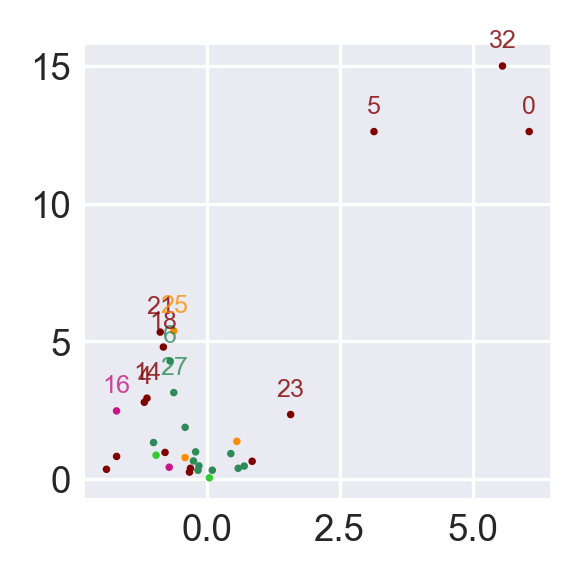

In [159]:
log_change = log_fold
log_10_qvals = numpy.clip(-numpy.log10(ttest_q_ts_vals), None, 15)

x_ys = []

plt.figure(figsize=(2, 2), dpi=300)
plt.scatter(
    log_change,
    log_10_qvals,
    s=1,
    c=cl_colors,
)
for ind_, (x, y) in enumerate(zip(log_change, log_10_qvals)):
    if ttest_q_ts_vals[ind_] > 0.01:
        continue
    plt.text(x, y + 0.5, ind_, ha='center', va='bottom', size=6, color=cl_colors[ind_], alpha=0.8)
    x_ys.append((x, y, ind_))

In [160]:
x_ys

[(6.0563472687835125, 12.619053097344885, 0),
 (-1.16729701241195, 2.7907828685217715, 4),
 (3.1436332415962758, 12.619053097344885, 5),
 (-0.683995219254725, 4.288918724090735, 6),
 (-1.1176274371743118, 2.9397545665710805, 14),
 (-1.6891489094588585, 2.4773448010264785, 16),
 (-0.8099941701312408, 4.797137597741492, 18),
 (-0.868558115494698, 5.338783531018056, 21),
 (1.5787933339229419, 2.3459246011613293, 23),
 (-0.614744260268816, 5.384156378751145, 25),
 (-0.6138442636059556, 3.142670842860979, 27),
 (5.555095801403102, 15.0, 32)]

In [161]:
x_ys_corrected = [
    (6.0563472687835125, 12.619053097344885, 0),
     (-1.16729701241195, 2.7907828685217715, 4),
     (3.1436332415962758, 12.619053097344885, 5),
     (-0.463995219254725, 3.288918724090735, 6),
     (-1.2076274371743118, 0.9397545665710805, 14),
     (-1.6891489094588585, 2.5273448010264785, 16),
     (-1.2099941701312408, 3.857137597741492, 18),
     (-1.268558115494698, 4.938783531018056, 21),
     (1.5787933339229419, 2.3459246011613293, 23),
     (-0.614744260268816, 5.384156378751145, 25),
     (-0.6138442636059556, 1.142670842860979, 27),
     (5.555095801403102, 15, 32)
]

/tmp/ipykernel_121012/1546392516.py:19: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_121012/1546392516.py:20: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


[Text(0, -5.0, '−5'),
 Text(0, 0.0, '0'),
 Text(0, 5.0, '5'),
 Text(0, 10.0, '10'),
 Text(0, 15.0, '15'),
 Text(0, 20.0, '20')]

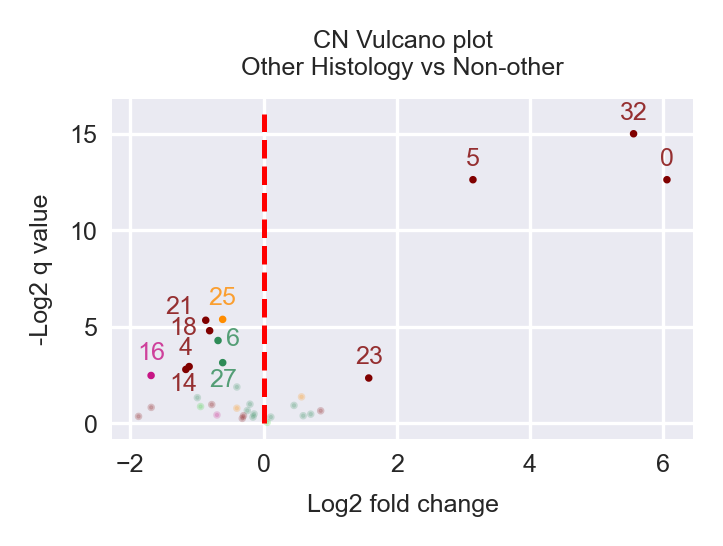

In [162]:
plt.figure(figsize=(2.5, 1.5), dpi=300)
plt.scatter(
    log_change,
    log_10_qvals,
    s=1,
    alpha=0.2 + 0.8 * (numpy.array(ttest_q_ts_vals) <= 0.01),
    c=cl_colors,
)
plt.plot([0, 0], [0, 16], '--', c='r', markersize=0.5)
for x, y, ind_ in x_ys_corrected:
    if ttest_q_ts_vals[ind_] > 0.01:
        continue
    plt.text(x, y + 0.5, ind_, ha='center', va='bottom', size=6, color=cl_colors[ind_], alpha=0.8)
    #x_ys.append((x, y, ind_))
plt.xlabel('Log2 fold change', size=6)
plt.ylabel('-Log2 q value', size=6)
plt.title('CN Vulcano plot\nOther Histology vs Non-other')
ax = plt.gca()
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.set_yticklabels(ax.get_yticklabels(), size=6)

/tmp/ipykernel_121012/395818974.py:17: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_121012/395818974.py:18: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


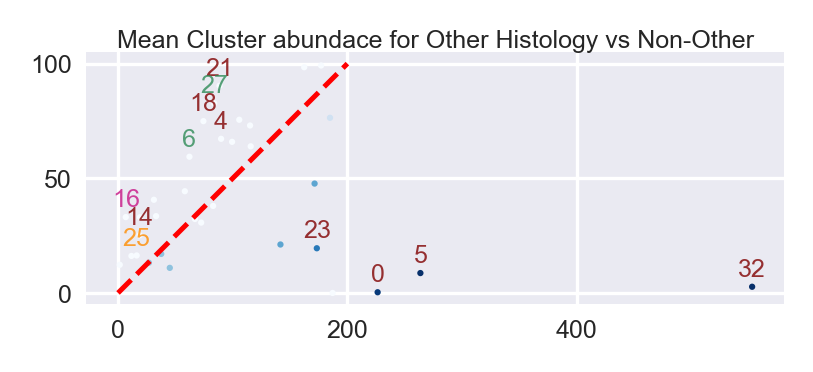

In [163]:
plt.figure(figsize=(3, 2), dpi=300)
plt.plot([0, 200], [0, 200], '--', c='r')
plt.scatter(
    other_pc_np,
    non_other_pc_np,
    s=0.5,
    #s=1. + 4 * (1 - numpy.array(ttest_q_vals)),
    c=numpy.array(ttest_q_vals),
    cmap='Blues_r',
)
for ind_, (x, y) in enumerate(zip(non_other_pc_np, other_pc_np)):
    if ttest_q_ts_vals[ind_] > 0.01:
        continue
    plt.text(y, x + 5, ind_, ha='center', va='bottom', size=6, color=cl_colors[ind_], alpha=0.8)
plt.title('Mean Cluster abundace for Other Histology vs Non-Other', size=6, pad=1)
ax = plt.gca()
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.set_aspect(1)

/tmp/ipykernel_121012/1506078283.py:22: UserWarning: FixedFormatter should only be used together with FixedLocator
  _ = other_box.yaxis.set_ticklabels(


Text(0.5, 0, '')

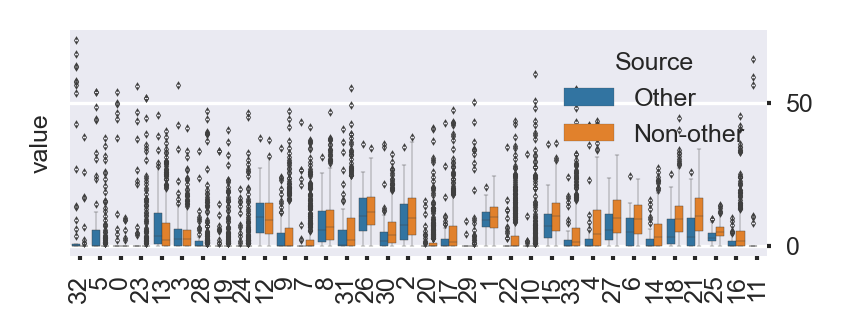

In [164]:
plt.figure(figsize=(3, 1), dpi=300)

ps_argsort = numpy.argsort(ttest_ps)

other_box = sns.boxplot(
    data=full_other_counts, 
    x='Cellohood Neighborhood Cluster', 
    y='value', 
    hue='Source',
    linewidth=0.1,
    fliersize=0.1,
    order=ps_argsort,
    #palette={'TLS': 'limegreen', 'Tumor': 'maroon'},
    #width=0.6,
    #showfliers=False,
)
other_box.xaxis.set_tick_params(size=1, rotation=90)
other_box.yaxis.set_tick_params(size=1, rotation=0)
_ = other_box.xaxis.set_ticklabels(
    other_box.xaxis.get_ticklabels(), size=6,
)
_ = other_box.yaxis.set_ticklabels(
    other_box.yaxis.get_ticklabels(), size=6,
)
other_box.yaxis.tick_right()
other_box.set_xlabel('')

In [165]:
IMAGES_PATH_PANEL_1 = '/raid/immucan/IMC/NSCLC2/IMC1/unzipped/'
IMAGES_PATH_PANEL_2 = '/raid/immucan/IMC/NSCLC2_PANEL2/unzipped/' 

In [166]:
png_to_full_path = defaultdict(list)


for root, dirnames, filenames in os.walk(IMAGES_PATH_PANEL_1):
    for filename in filenames:
        if filename.endswith('.tiff') and 'masks' not in root:
            png_to_full_path[filename].append(os.path.join(root, filename))
            
            
for root, dirnames, filenames in os.walk(IMAGES_PATH_PANEL_2):
    for filename in filenames:
        if filename.endswith('.tiff') and 'masks' not in root:
            png_to_full_path[filename].append(os.path.join(root, filename))

In [167]:
import pyometiff

In [168]:
from pyometiff import OMETIFFReader

reader = OMETIFFReader(fpath=list(png_to_full_path.values())[0][0])

img_array, metadata, xml_metadata = reader.read()

In [169]:
import numpy as np


def compute_triangle_areas(triangulation):
    """
    Compute areas of all triangles in a matplotlib triangulation
    
    Args:
        triangulation: matplotlib.tri.Triangulation object
        
    Returns:
        numpy array with areas of each triangle
    """
    # Get coordinates and triangles
    x = triangulation.x
    y = triangulation.y
    triangles = triangulation.triangles
    
    # Get vertices for each triangle
    v1 = np.column_stack((x[triangles[:,0]], y[triangles[:,0]]))
    v2 = np.column_stack((x[triangles[:,1]], y[triangles[:,1]]))
    v3 = np.column_stack((x[triangles[:,2]], y[triangles[:,2]]))
    
    # Compute areas using cross product
    # Area = 1/2 * |cross product|
    areas = 0.5 * np.abs(
        (v2[:,0] - v1[:,0]) * (v3[:,1] - v1[:,1]) -
        (v3[:,0] - v1[:,0]) * (v2[:,1] - v1[:,1])
    )
    
    return areas


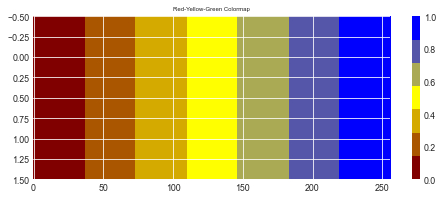

In [170]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

# Define the colors and their positions
colors = ['maroon', 'yellow', 'blue']
n_bins = 7  # Number of color gradations

# Create the colormap
custom_cmap = LinearSegmentedColormap.from_list('custom_RYG', colors, N=n_bins)

# Example to visualize the colormap:
plt.figure(figsize=(8, 3))
gradient = np.linspace(0, 1, 256)
gradient = np.vstack((gradient, gradient))
plt.imshow(gradient, aspect='auto', cmap=custom_cmap)
plt.colorbar()
plt.title('Red-Yellow-Green Colormap')
plt.show()

In [171]:
cluster_sort = (-celltype_percentages['Tumor'].values).argsort()
CLUSTER_PERM = cluster_sort
CLUSTER_PERM_ARGSORT = numpy.argsort(CLUSTER_PERM)

cell_df['cc_perm'] = cell_df[PREDICTION_CLUSTER_COLUMN].apply(lambda x: CLUSTER_PERM_ARGSORT[x])

/tmp/ipykernel_121012/472937149.py:188: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


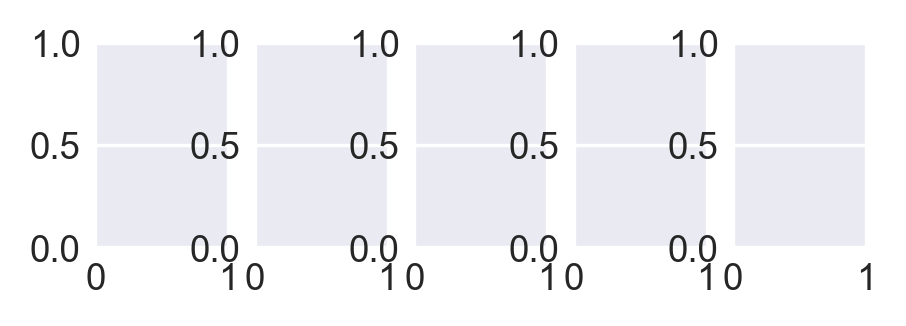

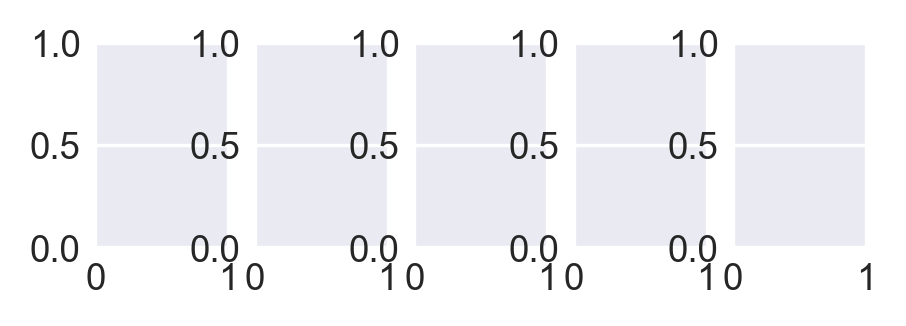

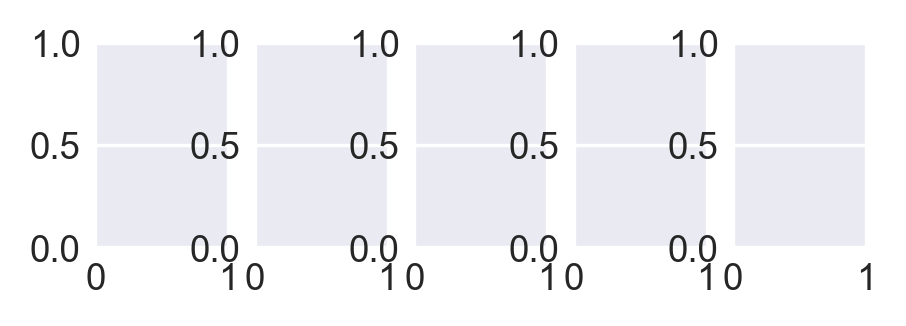

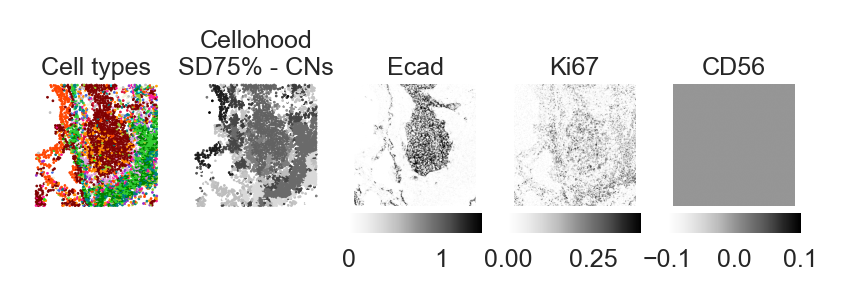

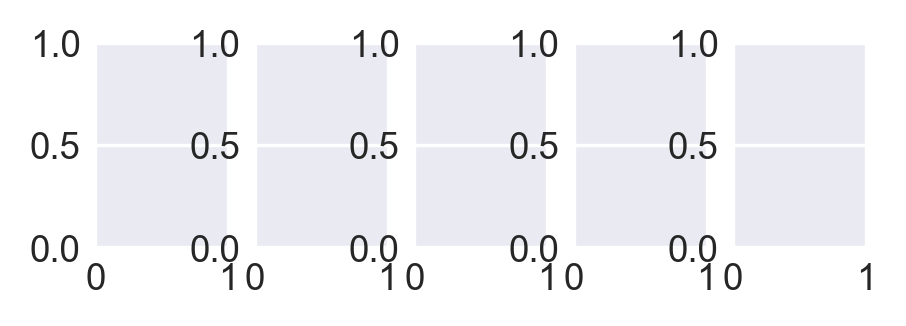

...

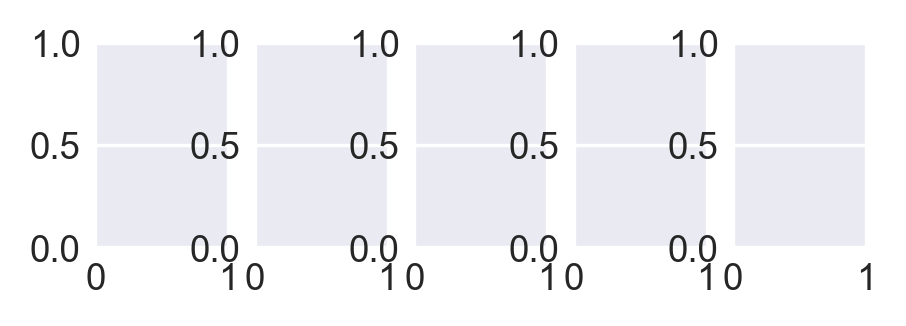

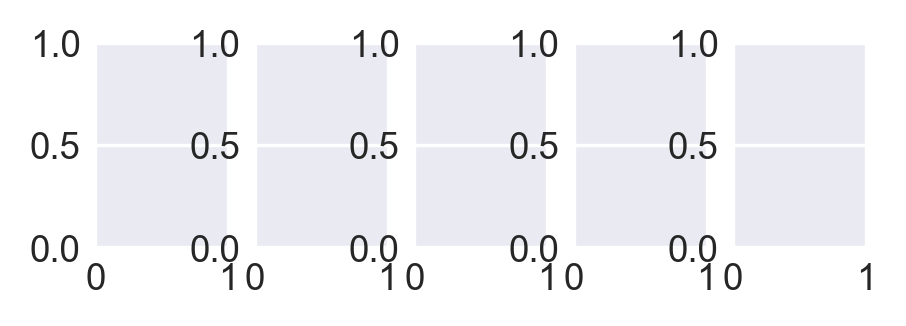

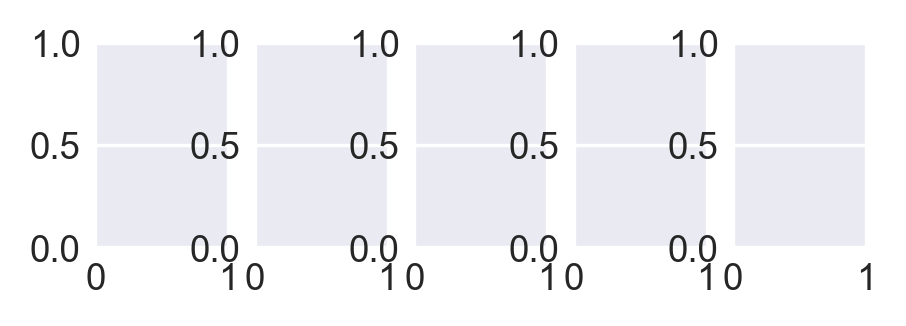

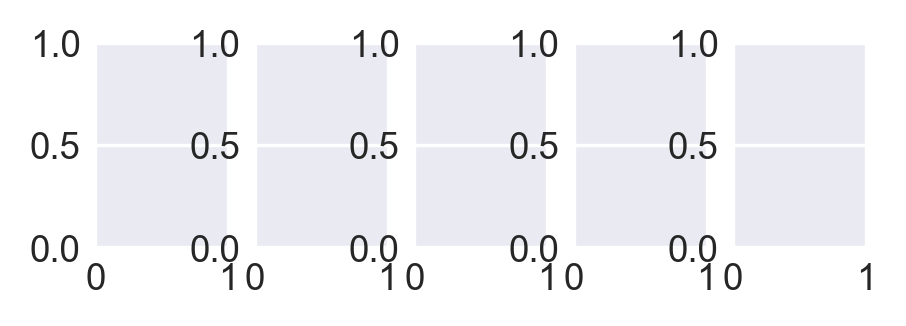

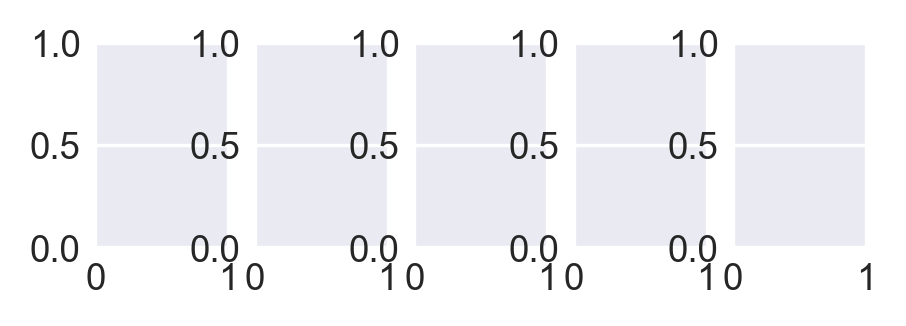

In [172]:
import matplotlib


CLUSTER_TO_ANALYZE = 9
cluster_images = list(set(roi_counts[clusters == CLUSTER_TO_ANALYZE].image))


from matplotlib import tri
from mpl_toolkits.axes_grid1 import make_axes_locatable

tumor_percentage_argsort = (-celltype_percentages['Tumor']).argsort().argsort()
MARKER_SIZE = 0.2

for image in cluster_images:
    # Create figure and gridspec for better control of subplot sizes
    fig = plt.figure(figsize=(4, 1), dpi=300)
    gs = plt.GridSpec(2, 6, height_ratios=[1, 0.1], hspace=0.01)
    
    # Create main plot axes
    axs = [plt.subplot(gs[0, i]) for i in range(1, 6)]
    if len(png_to_full_path[image]) == 0:
        continue
    # Read and process image
    reader = OMETIFFReader(fpath=png_to_full_path[image][0])
    img_array, _, _ = reader.read()
    img_array = numpy.arcsinh(img_array / 5.)
    image_df = cell_df[cell_df.image == image]
    
    # Compute triangulation
    tr = tri.Triangulation(image_df['Pos_X'], image_df['Pos_Y'])
    areas = compute_triangle_areas(tr)
    tr.set_mask(areas > 200)
    
    # Plot 1: Cell types
    axs[0].set_title('Cell types', size=6, pad=0.1)
    scatter0 = axs[0].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
        #alpha=0.5,
        c=image_df['celltypes'].apply(lambda x: tau.PANEL_2_CELL_TYPE_TO_COLOR[x]),
    )
    axs[0].set_aspect(1)
    axs[0].axis('off')
    axs[0].set_ylabel(f'{ROI_CLUSTER_NAME}: {CLUSTER_TO_ANALYZE}')
    # Create legend elements
    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=color, label=cell_type, 
                                 markersize=4)
                      for cell_type, color in tau.PANEL_1_CELL_TYPE_TO_COLOR.items()]
    
    # Add legend with small font and two columns
#    legend_ax = plt.subplot(gs[0, 0])
#     legend = legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           bbox_to_anchor=(0.05, -0.1),
#                           loc='center left',
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     legend_ax.axis('off')
    
#     # Remove legend frame
#     legend.get_frame().set_linewidth(0.0)
    
    axs[0].set_aspect(1)
    axs[0].axis('off')
    
    # Plot 2: Cellohood
    axs[1].set_title('Cellohood\nSD75% - CNs', size=6, pad=0.1)
    scatter1 = axs[1].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        c=image_df['Cellohood Neighborhood Cluster'],#.apply(lambda x: big_l_full_cc_colors_with_ct['CN Class'][x]),
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
    )
    axs[1].axis('off')
    axs[1].set_aspect(1)
    
    cc_norm = matplotlib.colors.Normalize(vmin=0, vmax=6)
    cc_sm = matplotlib.cm.ScalarMappable(norm=cc_norm, cmap=custom_cmap)
    

    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=cc_sm.to_rgba(i), label=f'CC:{i}', 
                                 markersize=4)
                      for i in range(7)]
#    cc_legend_ax = plt.subplot(gs[1, 2])
#     cc_legend = cc_legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           #bbox_to_anchor=(0.05, 0.1),
#                           #loc='upper center',
#                           bbox_to_anchor=(0.88, 3),
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     cc_legend.get_frame().set_linewidth(0.0)
#     cc_legend_ax.axis('off')

    
    # Plot 3: ECAD Expression
    axs[2].set_title('Ecad', size=6, pad=0.1)
    ECAD_INDEX = tau.PANEL_2_MARKER_NAMES.index('Ecad')
    img_m_arr = img_array[ECAD_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im2 = axs[2].imshow(
        img_m_arr,
        cmap='Greys',
    )
    axs[2].axis('off')
    
    # Plot 4: Ki67 Expression
    axs[3].set_title('Ki67', size=6, pad=0.1)
    KI67_INDEX = tau.PANEL_2_MARKER_NAMES.index('Ki67')
    img_m_arr = img_array[KI67_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im3 = axs[3].imshow(
        img_m_arr,
        cmap='Greys',
    )
    axs[3].axis('off')
    
    # Plot 5: CD3 Expression
    axs[4].set_title('CD56', size=6, pad=0.1)
    CD3_INDEX = tau.PANEL_2_MARKER_NAMES.index('CD56')
    img_m_arr = img_array[CD3_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im4 = axs[4].imshow(
        img_m_arr,
        cmap='Greys',
        #vmax=1.,
        #vmin=0,
    )
    axs[4].axis('off')
    
    
    # Add colorbars in separate row
    # Only add for plots that need them (2-5)
    for i, im in enumerate([im2, im3, im4]):
        cax = plt.subplot(gs[1, i+3])
        cbar = plt.colorbar(
            im, 
            cax=cax, 
            orientation='horizontal', 
            aspect=40, 
            shrink=0.9, 
            pad=0.01, 
            anchor=(1.1, 0),
        )
        cbar.ax.tick_params(labelsize=6)
        cbar.outline.set_visible(False)
        EPS = 0.12
        cbar_pos = cbar.ax.get_position()
        new_box = matplotlib.transforms.Bbox([[cbar_pos.x0, cbar_pos.y0 + EPS], [cbar_pos.x1, cbar_pos.y1 + EPS]])
        cbar.ax.set_position(new_box)
    
    # Make sure all plots have same limits
    # Get the overall limits from all scatter plots and images
    xlims = []
    ylims = []
    
    # Get limits from scatter plots
    xlims.extend([axs[0].get_xlim(), axs[1].get_xlim()])
    ylims.extend([axs[0].get_ylim(), axs[1].get_ylim()])
    
    # Get limits from images
    for i in range(2, 5):
        xlims.append([0, img_array.shape[2]])
        ylims.append([0, img_array.shape[1]])
    
    # Find the overall limits
    xmin = min([x[0] for x in xlims])
    xmax = max([x[1] for x in xlims])
    ymin = min([y[0] for y in ylims])
    ymax = max([y[1] for y in ylims])
    
    # Apply the same limits to all plots
    for ax in axs:
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
    
    plt.tight_layout()

    plt.show()

Skipping:  IMMUcan_Batch20210701_LUNG_10018884-LUNG-VAR-TIS-01-IMC-02_002
Skipping:  IMMUcan_Batch20210701_LUNG_10040768-LUNG-VAR-TIS-01-IMC-02_002
Skipping:  IMMUcan_Batch20210701_LUNG_10040815-LUNG-VAR-TIS-01-IMC-02_002


/tmp/ipykernel_121012/1823570943.py:192: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


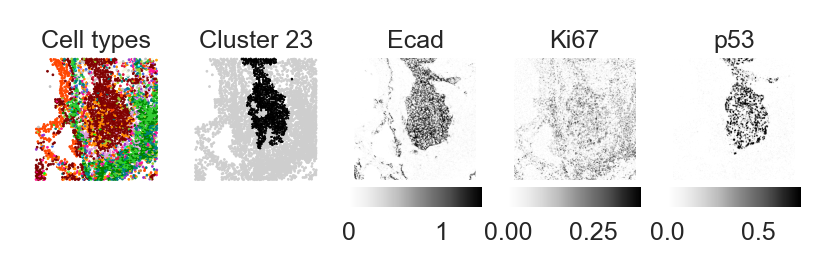

Skipping:  IMMUcan_Batch20210701_LUNG_10040838-LUNG-VAR-TIS-01-IMC-02_003
Skipping:  IMMUcan_Batch20210701_LUNG_10040769-LUNG-VAR-TIS-01-IMC-02_001
Skipping:  IMMUcan_Batch20210701_LUNG_10040838-LUNG-VAR-TIS-01-IMC-02_002
Skipping:  IMMUcan_Batch20210921_LUNG_10041564-LUNG-VAR-TIS-01-IMC-02_002.tiff
Skipping:  IMMUcan_Batch20210701_LUNG_10022144-LUNG-VAR-TIS-01-IMC-02_002
Skipping:  IMMUcan_Batch20210921_LUNG_10041589-LUNG-VAR-TIS-01-IMC-02_002.tiff
Skipping:  IMMUcan_Batch20210921_LUNG_10041564-LUNG-VAR-TIS-01-IMC-02_001.tiff
Skipping:  IMMUcan_Batch20210921_LUNG_10041582-LUNG-VAR-TIS-01-IMC-02_003.tiff
Skipping:  IMMUcan_Batch20210701_LUNG_10018884-LUNG-VAR-TIS-01-IMC-02_001
Skipping:  IMMUcan_Batch20210701_LUNG_10040838-LUNG-VAR-TIS-01-IMC-02_001
Skipping:  IMMUcan_Batch20210701_LUNG_10040815-LUNG-VAR-TIS-01-IMC-02_001
Skipping:  IMMUcan_Batch20210701_LUNG_10040815-LUNG-VAR-TIS-01-IMC-02_003
Skipping:  IMMUcan_Batch20210921_LUNG_10041582-LUNG-VAR-TIS-01-IMC-02_001.tiff


In [173]:
import matplotlib


CLUSTER_TO_ANALYZE = 9
CC_CLUSTER_TO_HIGHLIGHT = 23
cluster_images = list(set(roi_counts[clusters == CLUSTER_TO_ANALYZE].image))


from matplotlib import tri
from mpl_toolkits.axes_grid1 import make_axes_locatable

tumor_percentage_argsort = (-celltype_percentages['Tumor']).argsort().argsort()
MARKER_SIZE = 0.2

for image in cluster_images:
    if len(png_to_full_path[image]) == 0:
        print('Skipping: ', image)
        continue
    # Create figure and gridspec for better control of subplot sizes
    fig = plt.figure(figsize=(4, 1), dpi=300)
    gs = plt.GridSpec(2, 6, height_ratios=[1, 0.1], hspace=0.01)
    
    # Create main plot axes
    axs = [plt.subplot(gs[0, i]) for i in range(1, 6)]
    
    # Read and process image
    reader = OMETIFFReader(fpath=png_to_full_path[image][0])
    img_array, _, _ = reader.read()
    img_array = numpy.arcsinh(img_array / 5.)
    image_df = cell_df[cell_df.image == image]
    
    # Compute triangulation
    tr = tri.Triangulation(image_df['Pos_X'], image_df['Pos_Y'])
    areas = compute_triangle_areas(tr)
    tr.set_mask(areas > 200)
    
    # Plot 1: Cell types
    axs[0].set_title('Cell types', size=6, pad=0.1)
    scatter0 = axs[0].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
        #alpha=0.5,
        c=image_df['celltypes'].apply(lambda x: tau.PANEL_2_CELL_TYPE_TO_COLOR[x]),
    )
    axs[0].set_aspect(1)
    axs[0].axis('off')
    axs[0].set_ylabel(f'{ROI_CLUSTER_NAME}: {CLUSTER_TO_ANALYZE}')
    # Create legend elements
    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=color, label=cell_type, 
                                 markersize=4)
                      for cell_type, color in tau.PANEL_1_CELL_TYPE_TO_COLOR.items()]
    
    # Add legend with small font and two columns
#    legend_ax = plt.subplot(gs[0, 0])
#     legend = legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           bbox_to_anchor=(0.05, -0.1),
#                           loc='center left',
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     legend_ax.axis('off')
    
#     # Remove legend frame
#     legend.get_frame().set_linewidth(0.0)
    
    axs[0].set_aspect(1)
    axs[0].axis('off')
    
    # Plot 2: Cellohood
    axs[1].set_title(f'Cluster {CC_CLUSTER_TO_HIGHLIGHT}', size=6, pad=0.1)
    scatter1 = axs[1].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        c=0.3 + 0.7 * (image_df['Cellohood Neighborhood Cluster'] == CC_CLUSTER_TO_HIGHLIGHT),
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
        vmin=0,
    )
    axs[1].axis('off')
    axs[1].set_aspect(1)
    
    cc_norm = matplotlib.colors.Normalize(vmin=0, vmax=6)
    cc_sm = matplotlib.cm.ScalarMappable(norm=cc_norm, cmap=custom_cmap)
    

    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=cc_sm.to_rgba(i), label=f'CC:{i}', 
                                 markersize=4)
                      for i in range(7)]
#    cc_legend_ax = plt.subplot(gs[1, 2])
#     cc_legend = cc_legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           #bbox_to_anchor=(0.05, 0.1),
#                           #loc='upper center',
#                           bbox_to_anchor=(0.88, 3),
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     cc_legend.get_frame().set_linewidth(0.0)
#     cc_legend_ax.axis('off')

    
    # Plot 3: ECAD Expression
    axs[2].set_title('Ecad', size=6, pad=0.1)
    ECAD_INDEX = tau.PANEL_2_MARKER_NAMES.index('Ecad')
    img_m_arr = img_array[ECAD_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im2 = axs[2].imshow(
        img_m_arr,
        cmap='Greys',
    )
    axs[2].axis('off')
    
    # Plot 4: Ki67 Expression
    axs[3].set_title('Ki67', size=6, pad=0.1)
    KI67_INDEX = tau.PANEL_2_MARKER_NAMES.index('Ki67')
    img_m_arr = img_array[KI67_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im3 = axs[3].imshow(
        img_m_arr,
        cmap='Greys',
    )
    axs[3].axis('off')
    
    # Plot 5: CD3 Expression
    axs[4].set_title('p53', size=6, pad=0.1)
    CD3_INDEX = tau.PANEL_2_MARKER_NAMES.index('p53')
    img_m_arr = img_array[CD3_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im4 = axs[4].imshow(
        img_m_arr,
        cmap='Greys',
        #vmax=1.,
        #vmin=0,
    )
    axs[4].axis('off')
    
    
    # Add colorbars in separate row
    # Only add for plots that need them (2-5)
    for i, im in enumerate([im2, im3, im4]):
        cax = plt.subplot(gs[1, i+3])
        cbar = plt.colorbar(
            im, 
            cax=cax, 
            orientation='horizontal', 
            aspect=40, 
            shrink=0.9, 
            pad=0.01, 
            anchor=(1.1, 0),
        )
        cbar.ax.tick_params(labelsize=6)
        cbar.outline.set_visible(False)
        EPS = 0.12
        cbar_pos = cbar.ax.get_position()
        new_box = matplotlib.transforms.Bbox([[cbar_pos.x0, cbar_pos.y0 + EPS], [cbar_pos.x1, cbar_pos.y1 + EPS]])
        cbar.ax.set_position(new_box)
    
    # Make sure all plots have same limits
    # Get the overall limits from all scatter plots and images
    xlims = []
    ylims = []
    
    # Get limits from scatter plots
    xlims.extend([axs[0].get_xlim(), axs[1].get_xlim()])
    ylims.extend([axs[0].get_ylim(), axs[1].get_ylim()])
    
    # Get limits from images
    for i in range(2, 5):
        xlims.append([0, img_array.shape[2]])
        ylims.append([0, img_array.shape[1]])
    
    # Find the overall limits
    xmin = min([x[0] for x in xlims])
    xmax = max([x[1] for x in xlims])
    ymin = min([y[0] for y in ylims])
    ymax = max([y[1] for y in ylims])
    
    # Apply the same limits to all plots
    for ax in axs:
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
    
    plt.tight_layout()

    plt.show()

Skipping:  IMMUcan_Batch20210921_LUNG_10041577-LUNG-VAR-TIS-01-IMC-02_001.tiff
Skipping:  IMMUcan_Batch20210921_LUNG_10041577-LUNG-VAR-TIS-01-IMC-02_002.tiff
Skipping:  IMMUcan_Batch20210921_LUNG_10041577-LUNG-VAR-TIS-01-IMC-02_003.tiff


/tmp/ipykernel_121012/4100247307.py:197: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


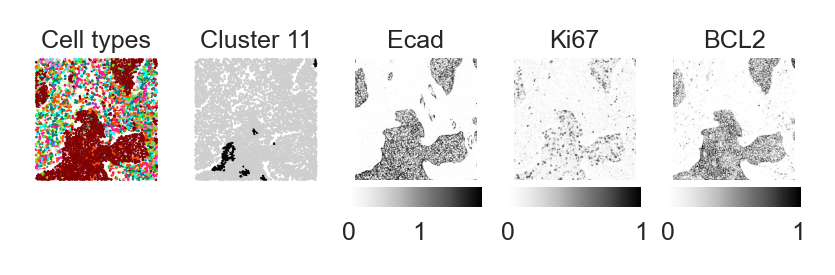

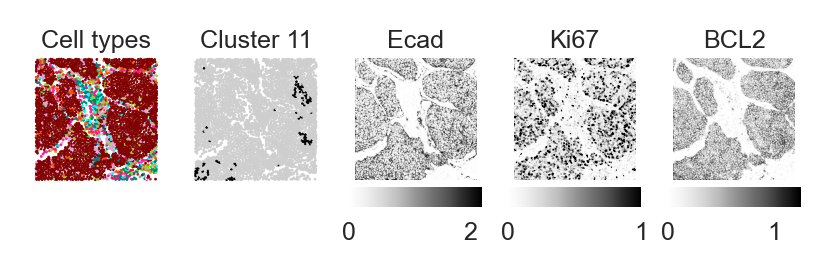

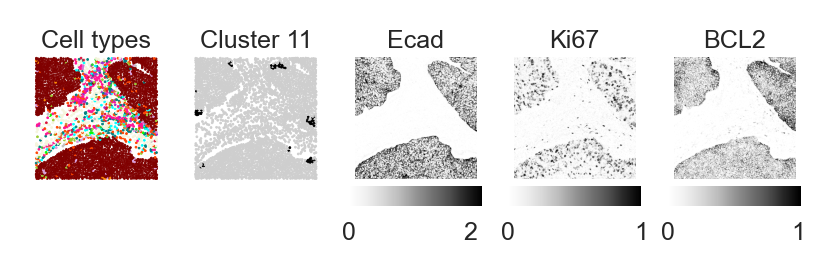

Skipping:  IMMUcan_Batch20210701_LUNG_10022144-LUNG-VAR-TIS-01-IMC-02_003
Skipping:  IMMUcan_Batch20210701_LUNG_10022151-LUNG-VAR-TIS-01-IMC-02_001
Skipping:  IMMUcan_Batch20210701_LUNG_10022151-LUNG-VAR-TIS-01-IMC-02_002
Skipping:  IMMUcan_Batch20210701_LUNG_10022151-LUNG-VAR-TIS-01-IMC-02_003
Skipping:  IMMUcan_Batch20210701_LUNG_10022165-LUNG-VAR-TIS-01-IMC-02_001
Skipping:  IMMUcan_Batch20210701_LUNG_10040811-LUNG-VAR-TIS-01-IMC-02_001
Skipping:  IMMUcan_Batch20210701_LUNG_10022165-LUNG-VAR-TIS-01-IMC-02_003
Skipping:  IMMUcan_Batch20210701_LUNG_10022144-LUNG-VAR-TIS-01-IMC-02_002
Skipping:  IMMUcan_Batch20210701_LUNG_10022149-LUNG-VAR-TIS-01-IMC-02_001
Skipping:  IMMUcan_Batch20210701_LUNG_10022149-LUNG-VAR-TIS-01-IMC-02_002
Skipping:  IMMUcan_Batch20210701_LUNG_10022149-LUNG-VAR-TIS-01-IMC-02_003
Skipping:  IMMUcan_Batch20210701_LUNG_10022165-LUNG-VAR-TIS-01-IMC-02_002
Skipping:  IMMUcan_Batch20210701_LUNG_10022144-LUNG-VAR-TIS-01-IMC-02_001
Skipping:  IMMUcan_Batch20210701_LUNG_

In [174]:
import matplotlib


CLUSTER_TO_ANALYZE = 10
CC_CLUSTER_TO_HIGHLIGHT = 11
cluster_images = list(roi_counts.iloc[(-roi_counts[CC_CLUSTER_TO_HIGHLIGHT]).argsort()[:20]]['image'])


from matplotlib import tri
from mpl_toolkits.axes_grid1 import make_axes_locatable

tumor_percentage_argsort = (-celltype_percentages['Tumor']).argsort().argsort()
MARKER_SIZE = 0.2

for image in cluster_images:
    if not image.endswith('.tiff'):
        image_to_read = image + '.tiff'
    else:
        image_to_read = image
    if len(png_to_full_path[image_to_read]) == 0:
        print('Skipping: ', image)
        continue
    # Create figure and gridspec for better control of subplot sizes
    fig = plt.figure(figsize=(4, 1), dpi=300)
    gs = plt.GridSpec(2, 6, height_ratios=[1, 0.1], hspace=0.01)
    
    # Create main plot axes
    axs = [plt.subplot(gs[0, i]) for i in range(1, 6)]
    
    # Read and process image
    reader = OMETIFFReader(fpath=png_to_full_path[image_to_read][0])
    img_array, _, _ = reader.read()
    img_array = numpy.arcsinh(img_array / 5.)
    image_df = cell_df[cell_df.image == image]
    
    # Compute triangulation
    tr = tri.Triangulation(image_df['Pos_X'], image_df['Pos_Y'])
    areas = compute_triangle_areas(tr)
    tr.set_mask(areas > 200)
    
    # Plot 1: Cell types
    axs[0].set_title('Cell types', size=6, pad=0.1)
    scatter0 = axs[0].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
        #alpha=0.5,
        c=image_df['celltypes'].apply(lambda x: tau.PANEL_2_CELL_TYPE_TO_COLOR[x]),
    )
    axs[0].set_aspect(1)
    axs[0].axis('off')
    axs[0].set_ylabel(f'{ROI_CLUSTER_NAME}: {CLUSTER_TO_ANALYZE}')
    # Create legend elements
    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=color, label=cell_type, 
                                 markersize=4)
                      for cell_type, color in tau.PANEL_1_CELL_TYPE_TO_COLOR.items()]
    
    # Add legend with small font and two columns
#    legend_ax = plt.subplot(gs[0, 0])
#     legend = legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           bbox_to_anchor=(0.05, -0.1),
#                           loc='center left',
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     legend_ax.axis('off')
    
#     # Remove legend frame
#     legend.get_frame().set_linewidth(0.0)
    
    axs[0].set_aspect(1)
    axs[0].axis('off')
    
    # Plot 2: Cellohood
    axs[1].set_title(f'Cluster {CC_CLUSTER_TO_HIGHLIGHT}', size=6, pad=0.1)
    scatter1 = axs[1].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        c=0.3 + 0.7 * (image_df['Cellohood Neighborhood Cluster'] == CC_CLUSTER_TO_HIGHLIGHT),
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
        vmin=0,
    )
    axs[1].axis('off')
    axs[1].set_aspect(1)
    
    cc_norm = matplotlib.colors.Normalize(vmin=0, vmax=6)
    cc_sm = matplotlib.cm.ScalarMappable(norm=cc_norm, cmap=custom_cmap)
    

    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=cc_sm.to_rgba(i), label=f'CC:{i}', 
                                 markersize=4)
                      for i in range(7)]
#    cc_legend_ax = plt.subplot(gs[1, 2])
#     cc_legend = cc_legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           #bbox_to_anchor=(0.05, 0.1),
#                           #loc='upper center',
#                           bbox_to_anchor=(0.88, 3),
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     cc_legend.get_frame().set_linewidth(0.0)
#     cc_legend_ax.axis('off')

    
    # Plot 3: ECAD Expression
    axs[2].set_title('Ecad', size=6, pad=0.1)
    ECAD_INDEX = tau.PANEL_2_MARKER_NAMES.index('Ecad')
    img_m_arr = img_array[ECAD_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im2 = axs[2].imshow(
        img_m_arr,
        cmap='Greys',
    )
    axs[2].axis('off')
    
    # Plot 4: Ki67 Expression
    axs[3].set_title('Ki67', size=6, pad=0.1)
    KI67_INDEX = tau.PANEL_2_MARKER_NAMES.index('Ki67')
    img_m_arr = img_array[KI67_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im3 = axs[3].imshow(
        img_m_arr,
        cmap='Greys',
        vmax=1,
    )
    axs[3].axis('off')
    
    # Plot 5: CD3 Expression
    axs[4].set_title('BCL2', size=6, pad=0.1)
    CD3_INDEX = tau.PANEL_2_MARKER_NAMES.index('Bcl2')
    img_m_arr = img_array[CD3_INDEX]
    img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
    im4 = axs[4].imshow(
        img_m_arr,
        cmap='Greys',
        #vmax=1.,
        #vmin=0,
    )
    axs[4].axis('off')
    
    
    # Add colorbars in separate row
    # Only add for plots that need them (2-5)
    for i, im in enumerate([im2, im3, im4]):
        cax = plt.subplot(gs[1, i+3])
        cbar = plt.colorbar(
            im, 
            cax=cax, 
            orientation='horizontal', 
            aspect=40, 
            shrink=0.9, 
            pad=0.01, 
            anchor=(1.1, 0),
        )
        cbar.ax.tick_params(labelsize=6)
        cbar.outline.set_visible(False)
        EPS = 0.12
        cbar_pos = cbar.ax.get_position()
        new_box = matplotlib.transforms.Bbox([[cbar_pos.x0, cbar_pos.y0 + EPS], [cbar_pos.x1, cbar_pos.y1 + EPS]])
        cbar.ax.set_position(new_box)
    
    # Make sure all plots have same limits
    # Get the overall limits from all scatter plots and images
    xlims = []
    ylims = []
    
    # Get limits from scatter plots
    xlims.extend([axs[0].get_xlim(), axs[1].get_xlim()])
    ylims.extend([axs[0].get_ylim(), axs[1].get_ylim()])
    
    # Get limits from images
    for i in range(2, 5):
        xlims.append([0, img_array.shape[2]])
        ylims.append([0, img_array.shape[1]])
    
    # Find the overall limits
    xmin = min([x[0] for x in xlims])
    xmax = max([x[1] for x in xlims])
    ymin = min([y[0] for y in ylims])
    ymax = max([y[1] for y in ylims])
    
    # Apply the same limits to all plots
    for ax in axs:
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
    
    plt.tight_layout()

    plt.show()

Skipping:  IMMUcan_Batch20210701_LUNG_10040770-LUNG-VAR-TIS-01-IMC-02_001


/tmp/ipykernel_121012/978192772.py:233: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


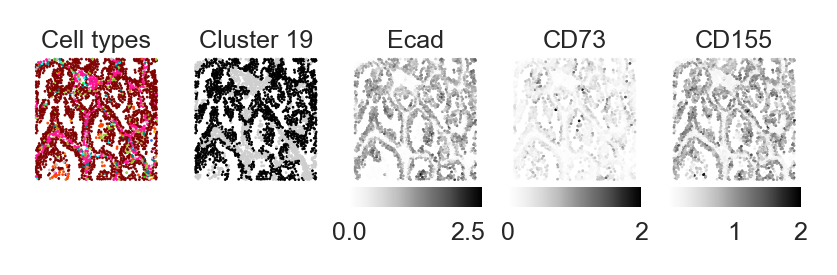

Skipping:  IMMUcan_Batch20210701_LUNG_10040757-LUNG-VAR-TIS-01-IMC-02_003


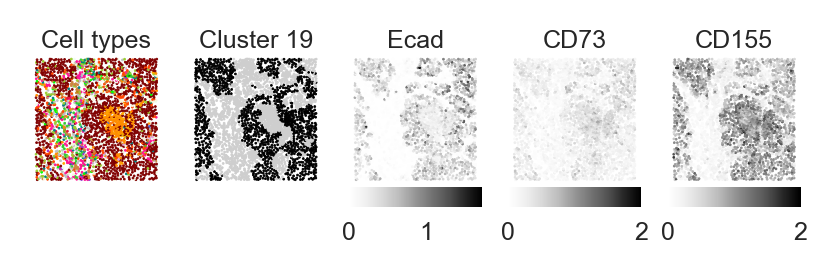

Skipping:  IMMUcan_Batch20210701_LUNG_10022157-LUNG-VAR-TIS-01-IMC-02_001


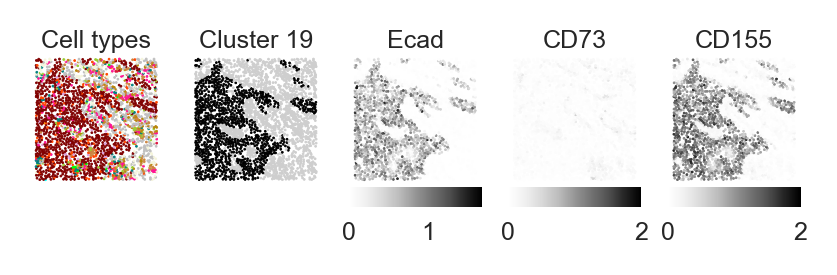

Skipping:  IMMUcan_Batch20210701_LUNG_10022157-LUNG-VAR-TIS-01-IMC-02_002


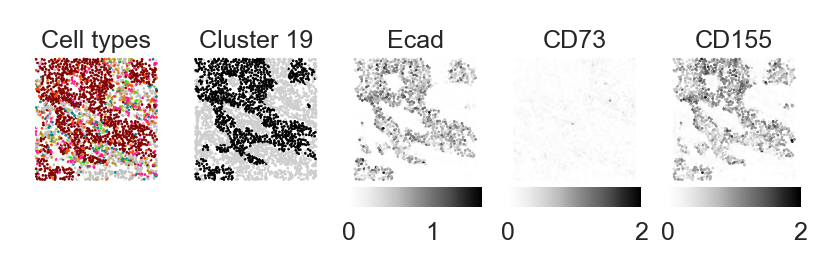

Skipping:  IMMUcan_Batch20210701_LUNG_10040757-LUNG-VAR-TIS-01-IMC-02_001


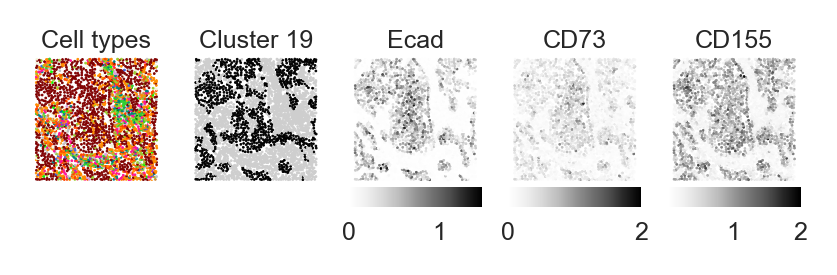

Skipping:  IMMUcan_Batch20210701_LUNG_10022159-LUNG-VAR-TIS-01-IMC-02_002


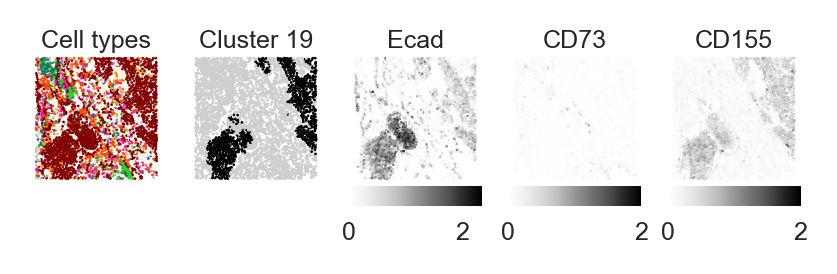

Skipping:  IMMUcan_Batch20210701_LUNG_10018936-LUNG-VAR-TIS-01-IMC-02_002


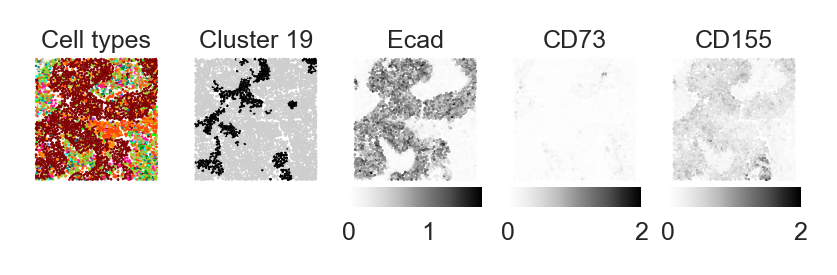

Skipping:  IMMUcan_Batch20210701_LUNG_10040757-LUNG-VAR-TIS-01-IMC-02_002


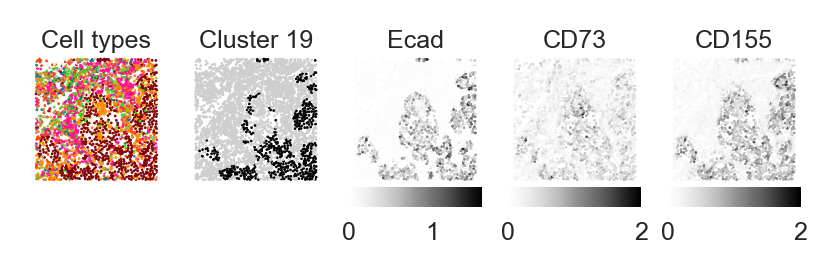

Skipping:  IMMUcan_Batch20210701_LUNG_10040770-LUNG-VAR-TIS-01-IMC-02_003


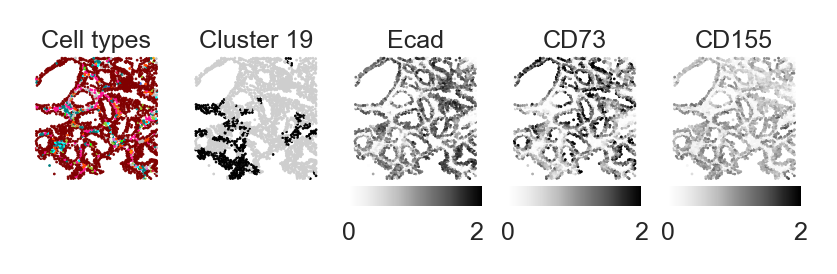

Skipping:  IMMUcan_Batch20210921_LUNG_10041542-LUNG-VAR-TIS-01-IMC-02_001.tiff


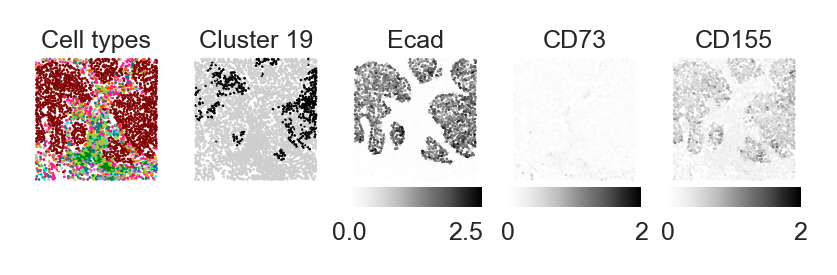

Skipping:  IMMUcan_Batch20210701_LUNG_10040812-LUNG-VAR-TIS-01-IMC-02_003


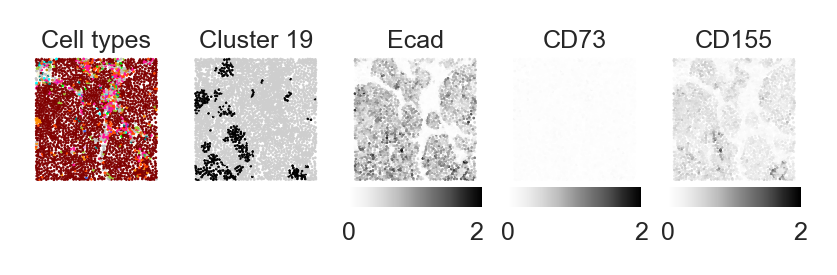

Skipping:  IMMUcan_Batch20210701_LUNG_10041511-LUNG-VAR-TIS-01-IMC-02_001


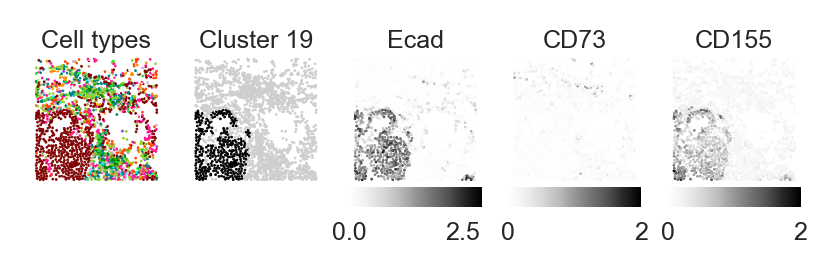

Skipping:  IMMUcan_Batch20210701_LUNG_10022159-LUNG-VAR-TIS-01-IMC-02_001


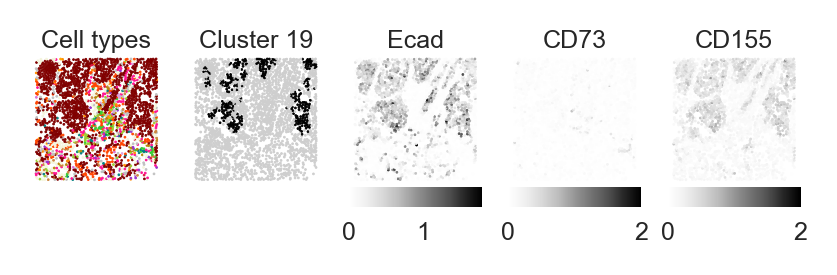

Skipping:  IMMUcan_Batch20210701_LUNG_10022159-LUNG-VAR-TIS-01-IMC-02_003


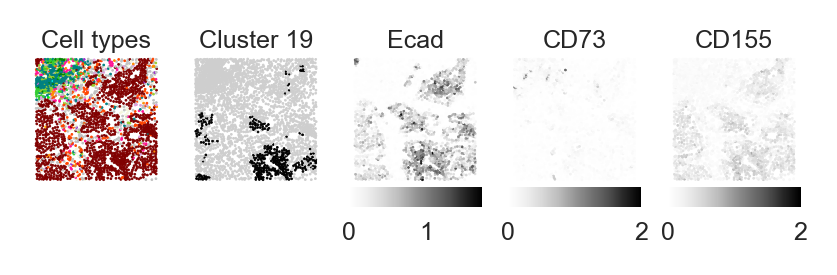

Skipping:  IMMUcan_Batch20210921_LUNG_10041542-LUNG-VAR-TIS-01-IMC-02_003.tiff


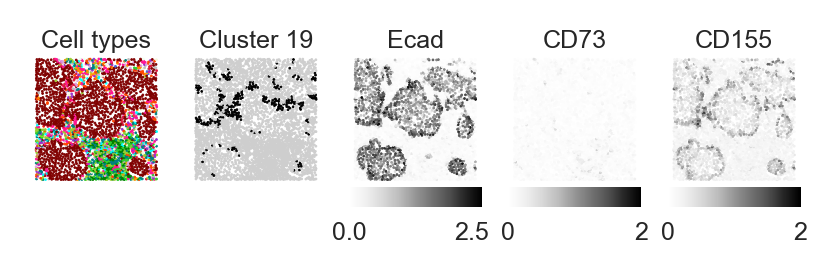

Skipping:  IMMUcan_Batch20210701_LUNG_10018888-LUNG-VAR-TIS-01-IMC-02_002


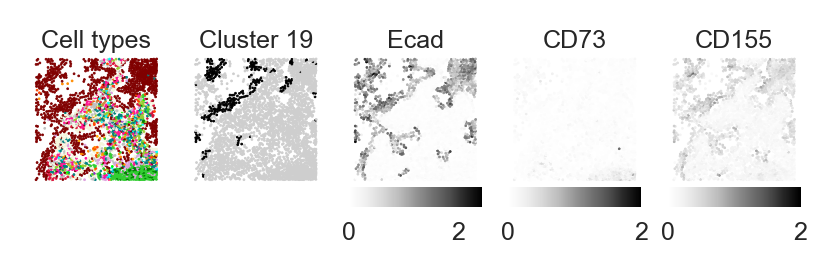

Skipping:  IMMUcan_Batch20210921_LUNG_10041542-LUNG-VAR-TIS-01-IMC-02_002.tiff


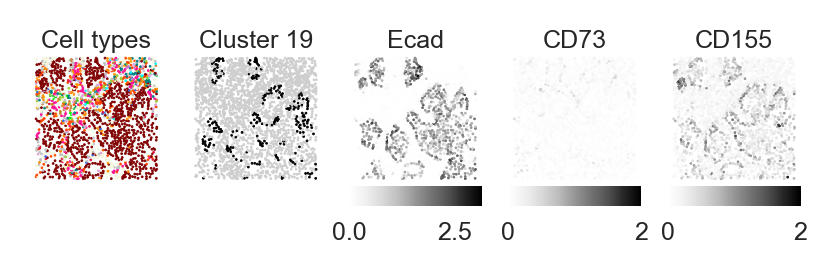

Skipping:  IMMUcan_Batch20210921_LUNG_10041567-LUNG-VAR-TIS-01-IMC-02_001.tiff


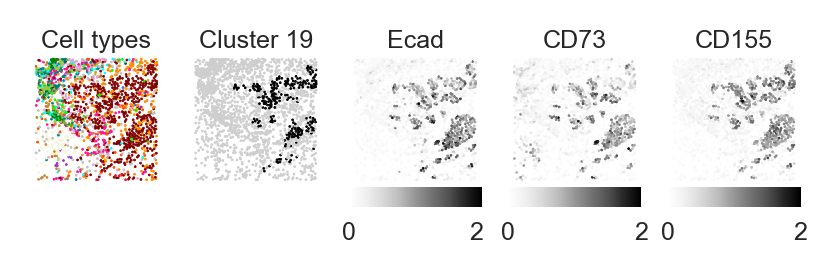

Skipping:  IMMUcan_Batch20210921_LUNG_10041567-LUNG-VAR-TIS-01-IMC-02_003.tiff


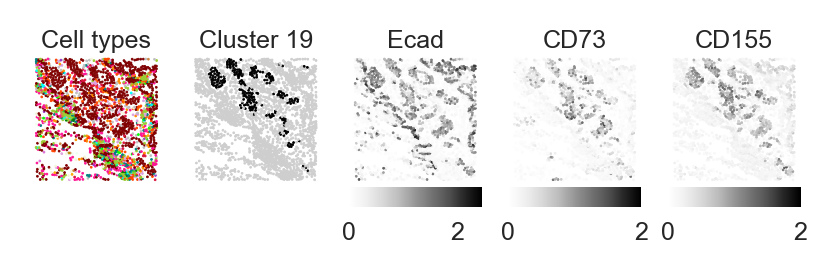

Skipping:  IMMUcan_Batch20210701_LUNG_10018890-LUNG-VAR-TIS-01-IMC-02_001


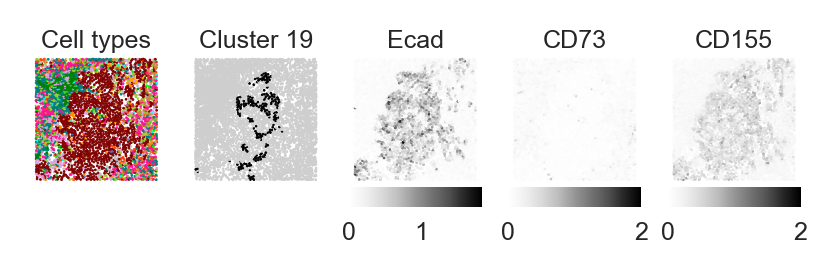

In [175]:
import matplotlib


CLUSTER_TO_ANALYZE = 5
CC_CLUSTER_TO_HIGHLIGHT = 19
cluster_images = list(roi_counts.iloc[(-roi_counts[CC_CLUSTER_TO_HIGHLIGHT]).argsort()[:20]]['image'])


from matplotlib import tri
from mpl_toolkits.axes_grid1 import make_axes_locatable

tumor_percentage_argsort = (-celltype_percentages['Tumor']).argsort().argsort()
MARKER_SIZE = 0.2

for image in cluster_images:
    if len(png_to_full_path[image]) == 0:
        print('Skipping: ', image)
        img_array = None
    else: 
        reader = OMETIFFReader(fpath=png_to_full_path[image][0])
        img_array, _, _ = reader.read()
        img_array = numpy.arcsinh(img_array / 5.)
    # Create figure and gridspec for better control of subplot sizes
    fig = plt.figure(figsize=(4, 1), dpi=300)
    gs = plt.GridSpec(2, 6, height_ratios=[1, 0.1], hspace=0.01)
    
    # Create main plot axes
    axs = [plt.subplot(gs[0, i]) for i in range(1, 6)]
    
    # Read and process image
    
    image_df = cell_df[cell_df.image == image]
    
    # Compute triangulation
    tr = tri.Triangulation(image_df['Pos_X'], image_df['Pos_Y'])
    areas = compute_triangle_areas(tr)
    tr.set_mask(areas > 200)
    
    # Plot 1: Cell types
    axs[0].set_title('Cell types', size=6, pad=0.1)
    scatter0 = axs[0].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
        #alpha=0.5,
        c=image_df['celltypes'].apply(lambda x: tau.PANEL_2_CELL_TYPE_TO_COLOR[x]),
    )
    axs[0].set_aspect(1)
    axs[0].axis('off')
    axs[0].set_ylabel(f'{ROI_CLUSTER_NAME}: {CLUSTER_TO_ANALYZE}')
    # Create legend elements
    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=color, label=cell_type, 
                                 markersize=4)
                      for cell_type, color in tau.PANEL_1_CELL_TYPE_TO_COLOR.items()]
    
    # Add legend with small font and two columns
#    legend_ax = plt.subplot(gs[0, 0])
#     legend = legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           bbox_to_anchor=(0.05, -0.1),
#                           loc='center left',
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     legend_ax.axis('off')
    
#     # Remove legend frame
#     legend.get_frame().set_linewidth(0.0)
    
    axs[0].set_aspect(1)
    axs[0].axis('off')
    
    # Plot 2: Cellohood
    axs[1].set_title(f'Cluster {CC_CLUSTER_TO_HIGHLIGHT}', size=6, pad=0.1)
    scatter1 = axs[1].scatter(
        image_df['Pos_X'],
        image_df['Pos_Y'],
        c=0.3 + 0.7 * (image_df['Cellohood Neighborhood Cluster'] == CC_CLUSTER_TO_HIGHLIGHT),
        s=MARKER_SIZE,
        linewidths=MARKER_SIZE,
        vmin=0,
    )
    axs[1].axis('off')
    axs[1].set_aspect(1)
    
    cc_norm = matplotlib.colors.Normalize(vmin=0, vmax=6)
    cc_sm = matplotlib.cm.ScalarMappable(norm=cc_norm, cmap=custom_cmap)
    

    legend_elements = [plt.Line2D([0], [0], marker='o', color='w', 
                                 markerfacecolor=cc_sm.to_rgba(i), label=f'CC:{i}', 
                                 markersize=4)
                      for i in range(7)]
#    cc_legend_ax = plt.subplot(gs[1, 2])
#     cc_legend = cc_legend_ax.legend(handles=legend_elements, 
#                           fontsize=6,
#                           ncol=2,
#                           #bbox_to_anchor=(0.05, 0.1),
#                           #loc='upper center',
#                           bbox_to_anchor=(0.88, 3),
#                           labelspacing=0.1,
#                           columnspacing=0.3,
#                           handletextpad=0.01,
#                           borderaxespad=0.)
#     cc_legend.get_frame().set_linewidth(0.0)
#     cc_legend_ax.axis('off')

    
    # Plot 3: ECAD Expression
    axs[2].set_title('Ecad', size=6, pad=0.1)
    if img_array is not None:
        ECAD_INDEX = tau.PANEL_2_MARKER_NAMES.index('Ecad')
        img_m_arr = img_array[ECAD_INDEX]
        img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
        im2 = axs[2].imshow(
            img_m_arr,
            cmap='Greys',
        )
        axs[2].axis('off')
    else:
        im2 = axs[2].scatter(
            image_df['Pos_X'],
            image_df['Pos_Y'],
            c=image_df['Ecad'],
            cmap='Greys',
            #vmax=2.5,
            s=MARKER_SIZE,
            linewidths=MARKER_SIZE,
        )
        axs[2].axis('off')
        axs[2].set_aspect(1)
    
    # Plot 4: Ki67 Expression
    axs[3].set_title('CD73', size=6, pad=0.1)
    if img_array is not None:
        KI67_INDEX = tau.PANEL_2_MARKER_NAMES.index('CD73')
        img_m_arr = img_array[KI67_INDEX]
        img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
        im3 = axs[3].imshow(
            img_m_arr,
            cmap='Greys',
        )
        axs[3].axis('off')
    else:
        im3 = axs[3].scatter(
            image_df['Pos_X'],
            image_df['Pos_Y'],
            c=image_df['CD73'],
            cmap='Greys',
            s=MARKER_SIZE,
            vmax=2,
            linewidths=MARKER_SIZE,
        )
        axs[3].axis('off')
        axs[3].set_aspect(1)
        
    
    # Plot 5: CD3 Expression
    axs[4].set_title('CD155', size=6, pad=0.1)
    if img_array is not None:
        CD3_INDEX = tau.PANEL_2_MARKER_NAMES.index('CD155')
        img_m_arr = img_array[CD3_INDEX]
        img_m_arr = numpy.clip(img_m_arr, 0, numpy.quantile(img_m_arr.flatten(), 0.95))
        im4 = axs[4].imshow(
            img_m_arr,
            cmap='Greys',
            #vmin=0,
        )
        axs[4].axis('off')
    else:
        im4 = axs[4].scatter(
            image_df['Pos_X'],
            image_df['Pos_Y'],
            c=image_df['CD155'],
            cmap='Greys',
            s=MARKER_SIZE,
            vmax=2,
            linewidths=MARKER_SIZE,
        )
        axs[4].axis('off')
        axs[4].set_aspect(1)
    
    
    # Add colorbars in separate row
    # Only add for plots that need them (2-5)
    for i, im in enumerate([im2, im3, im4]):
        cax = plt.subplot(gs[1, i+3])
        cbar = plt.colorbar(
            im, 
            cax=cax, 
            orientation='horizontal', 
            aspect=40, 
            shrink=0.9, 
            pad=0.01, 
            anchor=(1.1, 0),
        )
        cbar.ax.tick_params(labelsize=6)
        cbar.outline.set_visible(False)
        EPS = 0.12
        cbar_pos = cbar.ax.get_position()
        new_box = matplotlib.transforms.Bbox([[cbar_pos.x0, cbar_pos.y0 + EPS], [cbar_pos.x1, cbar_pos.y1 + EPS]])
        cbar.ax.set_position(new_box)
    
    # Make sure all plots have same limits
    # Get the overall limits from all scatter plots and images
    xlims = []
    ylims = []
    
    # Get limits from scatter plots
    xlims.extend([axs[0].get_xlim(), axs[1].get_xlim()])
    ylims.extend([axs[0].get_ylim(), axs[1].get_ylim()])
    
    # Get limits from images
    for i in range(2, 5):
        xlims.append([0, 600])
        ylims.append([0, 600])
    
    # Find the overall limits
    xmin = min([x[0] for x in xlims])
    xmax = max([x[1] for x in xlims])
    ymin = min([y[0] for y in ylims])
    ymax = max([y[1] for y in ylims])
    
    # Apply the same limits to all plots
    for ax in axs:
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
    
    plt.tight_layout()

    plt.show()

In [176]:
cleaned_celltypes = {
    'PMN_MDSC': 'PMN_MDSC',
    'MacCD204_CD209': 'MacCD204&209'
}

(-0.05500000000000001,
 0.05500000000000001,
 -0.05500000000000001,
 0.05500000000000001)

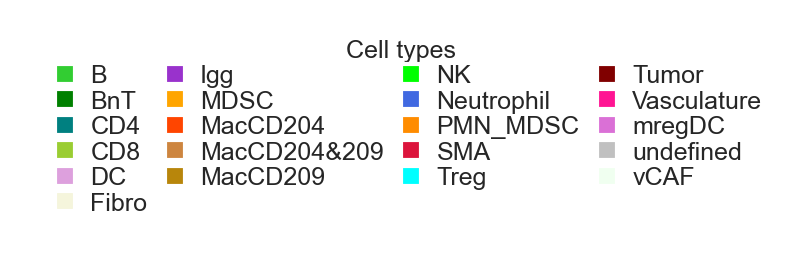

In [177]:
plt.figure(figsize=(1, 0.5), dpi=300)

plt.plot([0], [0])


state_elements = [
    plt.Line2D(
        [0], [0], 
        marker='s', 
        markerfacecolor=tau.PANEL_2_CELL_TYPE_TO_COLOR[cl], 
        color='white', 
        label=cl if cl not in cleaned_celltypes else cleaned_celltypes[cl], 
        markersize=5)
    for cl in tau.PANEL_2_CELL_TYPE_TO_COLOR
]

plt.legend(
    handles=state_elements, 
    ncols=4, 
    loc=(-0.8, -0.1), 
    fontsize=6, 
    frameon=False,
    title='Cell types',
    title_fontsize=6,
    labelspacing=0.1,
    columnspacing=0.1,
    handletextpad=0.01,
)
plt.axis('off')

In [178]:
class_to_celltypes = {
    'Cl.Tumor': ['Tumor'],
    'Immune': ['B', 'BnT', 'CD4', 'CD8', 'DC', 'Igg', 'MDSC', 'MacCD204',
               'MacCD204_CD209', 'MacCD209', 'NK', 'Neutrophil', 'PMN_MDSC',
               'Treg', 'mregDC',
              ],
    'Mural': ['Fibro', 'vCAF', 'SMA'],
    'Vasculature': ['Vasculature'],
    'Other': ['undefined']
}

In [179]:
celltypes_to_class = {
    ct: class_
    for class_, cts in class_to_celltypes.items()
    for ct in cts
}

In [180]:
cell_df['Class'] = cell_df['celltypes'].apply(
    lambda x: celltypes_to_class[x]
)

In [181]:
# NOTE: was `celltypes_to_class.values()` (values are single class strings, not
# lists -- can't be flattened with sum(..., [])); class_to_celltypes is the
# class->list-of-celltypes mapping actually being sanity-checked here.
len(sum(class_to_celltypes.values(), [])), len(tau.PANEL_2_CELL_TYPE_TO_COLOR)

(21, 21)

In [182]:
from matplotlib import colors as mcolors


class_to_color = {
    'Immune': tau.META_CLUSTER_TO_COLOR['INFILTRATION'],
    'Cl.Tumor': tau.META_CLUSTER_TO_COLOR['PURE_TUMOR'], 
    'Other': mcolors.CSS4_COLORS['black'], 
    'Mural': tau.META_CLUSTER_TO_COLOR['MURAL'],
    'Vasculature': mcolors.CSS4_COLORS['red'],
}

In [183]:
spatial_dimensions = pandas.read_csv(
    '/raid/immucan/immuw/cellohood_artifacts/NSCLC_P2/cells_with_sd.csv'
)

/tmp/ipykernel_121012/3132194523.py:1: DtypeWarning: Columns (18,41,87,88) have mixed types. Specify dtype option on import or set low_memory=False.
  spatial_dimensions = pandas.read_csv(


In [184]:
spatial_dimensions = spatial_dimensions.set_index('Unnamed: 0')

In [185]:
spatial_dimensions = spatial_dimensions.loc[cell_df['Unnamed: 0']]

/tmp/ipykernel_121012/847971525.py:18: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
/tmp/ipykernel_121012/847971525.py:19: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)


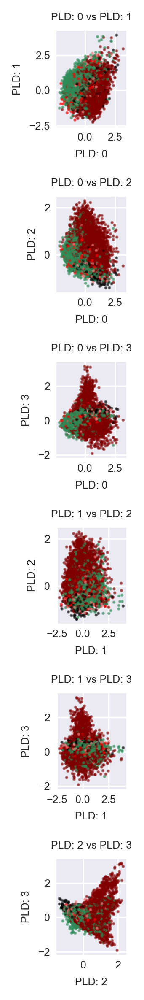

In [186]:
plt.figure(figsize=(1.2, 8), dpi=300)
current_index = 1
for l_i in range(4):
    for r_i in range(l_i + 1, 4):
        plt.subplot(6, 1, current_index)
        current_index += 1
        plt.scatter(
            spatial_dimensions[f'{l_i}ss'][::100],
            spatial_dimensions[f'{r_i}ss'][::100],
            c=cell_df[::100]['Class'].apply(lambda x: class_to_color[x]),
            s=1,
            alpha=0.5,
        )
        plt.xlabel(f'PLD: {l_i}')
        plt.ylabel(f'PLD: {r_i}')
        plt.title(f'PLD: {l_i} vs PLD: {r_i}')
        current_ax = plt.gca()
        current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
        current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)
plt.tight_layout()

/tmp/ipykernel_121012/436529994.py:20: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
/tmp/ipykernel_121012/436529994.py:21: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)


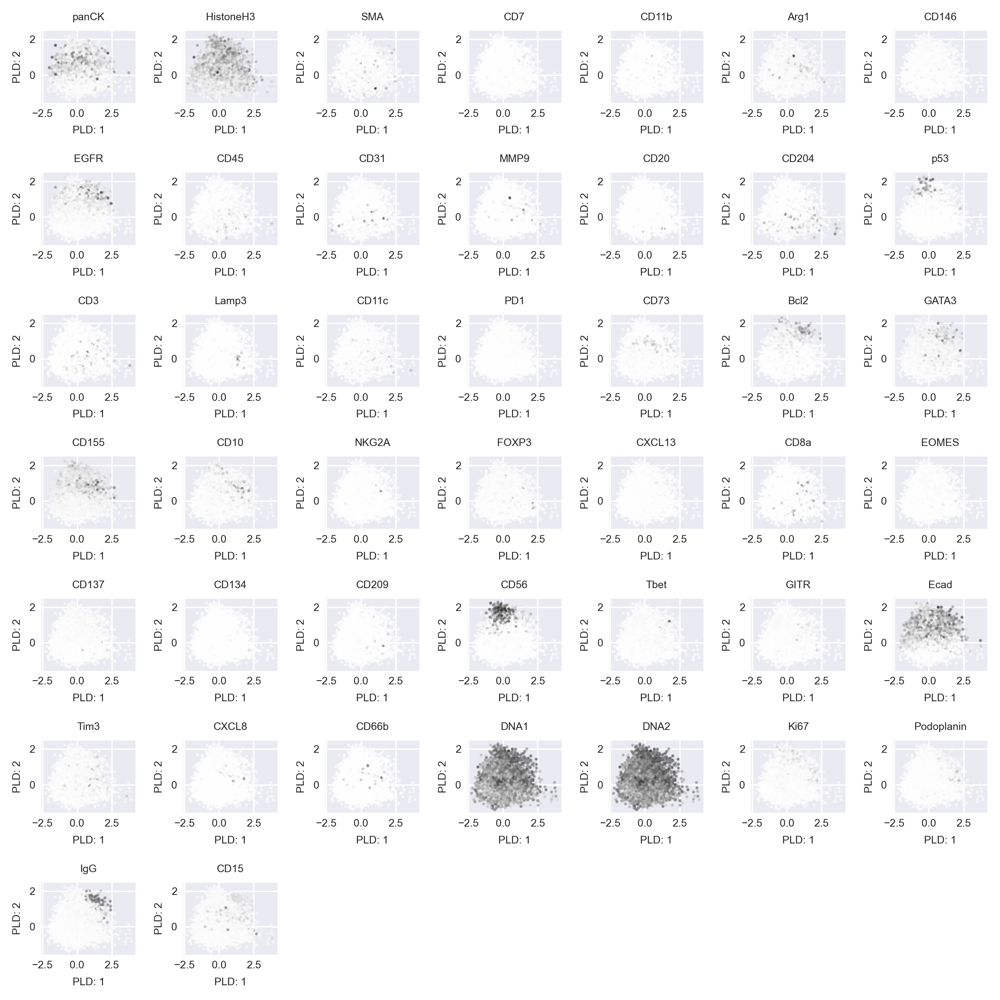

In [187]:
L_I = 1
R_I = 2

plt.figure(figsize=(8, 8), dpi=300)
current_index = 1
for marker in tau.PANEL_2_MARKER_NAMES:
    plt.subplot(7, 7, current_index)
    current_index += 1
    plt.scatter(
        spatial_dimensions[f'{L_I}ss'][::100],
        spatial_dimensions[f'{R_I}ss'][::100],
        c=cell_df[::100][marker],
        s=1,
        alpha=0.5,
    )
    plt.xlabel(f'PLD: {L_I}')
    plt.ylabel(f'PLD: {R_I}')
    plt.title(f'{marker}')
    current_ax = plt.gca()
    current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
    current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)
plt.tight_layout()

/tmp/ipykernel_121012/3433413451.py:17: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
/tmp/ipykernel_121012/3433413451.py:18: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)


/tmp/ipykernel_121012/3433413451.py:32: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
/tmp/ipykernel_121012/3433413451.py:33: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)
/tmp/ipykernel_121012/3433413451.py:17: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
/tmp/ipykernel_121012/3433413451.py:18: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)


/tmp/ipykernel_121012/3433413451.py:32: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
/tmp/ipykernel_121012/3433413451.py:33: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)
/tmp/ipykernel_121012/3433413451.py:17: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
/tmp/ipykernel_121012/3433413451.py:18: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)


/tmp/ipykernel_121012/3433413451.py:32: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
/tmp/ipykernel_121012/3433413451.py:33: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)


/tmp/ipykernel_121012/3433413451.py:17: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
/tmp/ipykernel_121012/3433413451.py:18: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)


/tmp/ipykernel_121012/3433413451.py:32: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
/tmp/ipykernel_121012/3433413451.py:33: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)


/tmp/ipykernel_121012/3433413451.py:17: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
/tmp/ipykernel_121012/3433413451.py:18: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)


/tmp/ipykernel_121012/3433413451.py:32: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
/tmp/ipykernel_121012/3433413451.py:33: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)


/tmp/ipykernel_121012/3433413451.py:17: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
/tmp/ipykernel_121012/3433413451.py:18: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)


/tmp/ipykernel_121012/3433413451.py:32: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
/tmp/ipykernel_121012/3433413451.py:33: UserWarning: FixedFormatter should only be used together with FixedLocator
  current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)


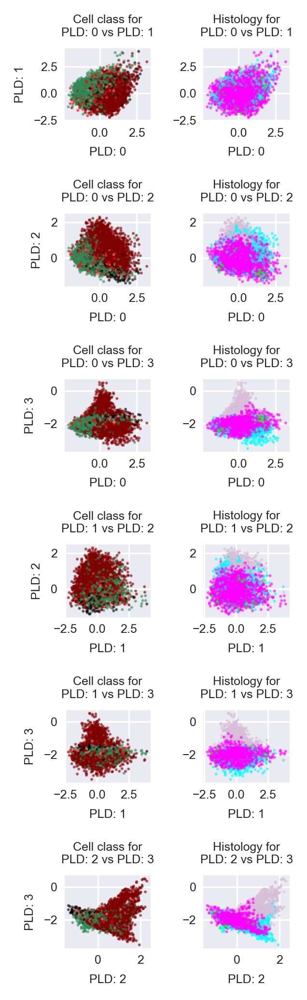

In [188]:
plt.figure(figsize=(2.2, 7), dpi=300)
current_index = 1
for l_i in range(4):
    for r_i in range(l_i + 1, 4):
        plt.subplot(6, 2, current_index)
        plt.scatter(
            spatial_dimensions[f'{l_i}ss'][::100],
            spatial_dimensions[f'{r_i}ss'][::100],
            c=cell_df[::100]['Class'].apply(lambda x: class_to_color[x]),
            s=0.5,
            alpha=0.5,
        )
        plt.xlabel(f'PLD: {l_i}')
        plt.ylabel(f'PLD: {r_i}')
        plt.title(f'Cell class for\nPLD: {l_i} vs PLD: {r_i}')
        current_ax = plt.gca()
        current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
        current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)
        current_index += 1
        plt.subplot(6, 2, current_index)
        plt.scatter(
            spatial_dimensions[f'{l_i}ss'][::100],
            spatial_dimensions[f'{r_i}ss'][::100],
            c=cell_df[::100]['sample_id'].apply(lambda x: tau.SIMPLE_HISTOLOGY_COLORS[
                roi_cluster_with_clinical.set_index('immucan_id').loc['-'.join(x.split('-')[:3])]['simple_histology']]),
            s=0.5,
            alpha=0.5,
        )
        plt.xlabel(f'PLD: {l_i}')
        plt.title(f'Histology for\nPLD: {l_i} vs PLD: {r_i}')
        current_ax = plt.gca()
        current_ax.set_xticklabels(current_ax.get_xticklabels(), size=6)
        current_ax.set_yticklabels(current_ax.get_yticklabels(), size=6)
        current_index += 1
plt.tight_layout()

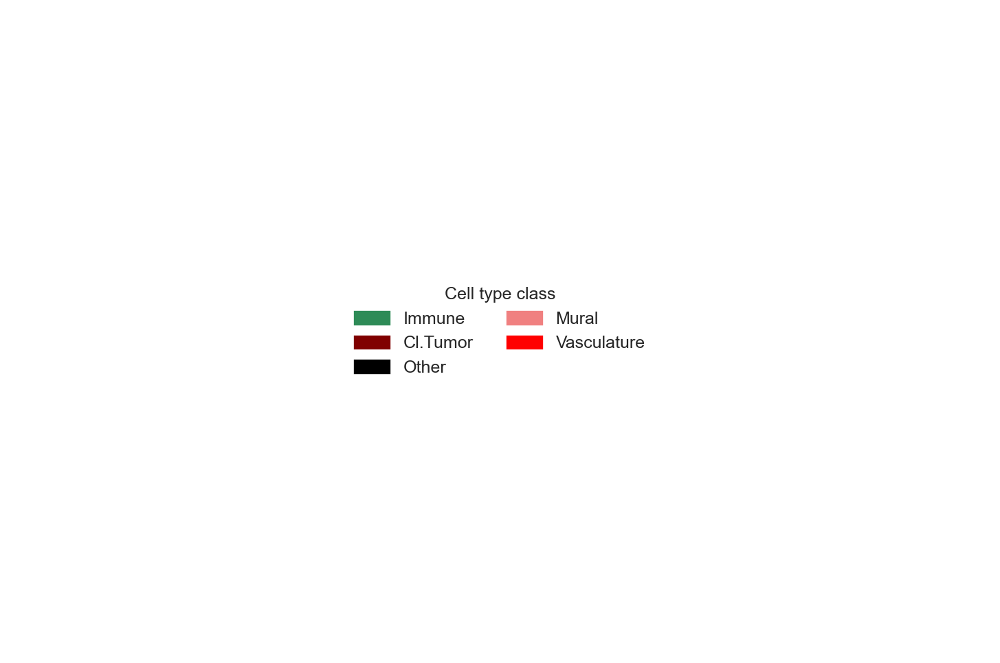

In [189]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches


# Create figure and axis
fig, ax = plt.subplots(dpi=300)

# Create legend handles
legend_handles = []
for class_name, color in class_to_color.items():
    handle = patches.Patch(color=color, label=class_name)
    legend_handles.append(handle)

# Add legend to the plot
ax.legend(handles=legend_handles, loc='center', ncols=2, fontsize=6, title='Cell type class')

# Hide axes since we only want the legend
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis('off')

plt.show()